# ТВД 110 кВт · подробный расчёт фиксированной проточной части

Принят последний вариант со сближенными профилями сопловых аппаратов и рабочих колёс. Две ступени, один ЦБК, 30 700 об/мин, наружный диаметр 216,289 мм, числа лопаток СА1/РК1/СА2/РК2 — **13/14/17/19**. Рабочая точка номинальная. Для работы вне номинала понадобится отдельный расчёт режима на заданной геометрии.

Запустите **Restart Kernel and Run All**. Ноутбук содержит номинальные исходные данные и параметры всех 20 сечений. Перезапуск пересчитывает газодинамику, потери, прочность и экспорт. Размеры берутся из сохранённой конфигурации. При расхождении с ней или нарушении неразрывности выполнение останавливается до экспорта.

Для запуска нужны Python 3.10+, NumPy 2.x, SciPy, pandas, matplotlib, IPython и ezdxf. Все исходные данные находятся в ноутбуке.
К шагам расчёта приложены формулы и ведомости. Все результаты ниже относятся к одной номинальной конфигурации.

Числа лопаток взаимно просты во всех шести парах венцов. Для РК2 при переходе с 18 на 19 уточнены параметры профилей с сохранением осевых ширин, радиусов и положений кромок по оси.

В разделе 6 приведён расчёт длительной прочности обоих РК с отечественным сплавом ЖС6У. В §6.1 — запас, оценка времени с запасом, сравнение с ЖС6К и архивный расчёт РК2.


## 1. Номинальный режим и фиксированные размеры

Продольный контур от входа СА1 до среза сопла строится по фиксированным узлам `CHANNEL_NODES`. Каждый узел задаёт осевую координату, радиусы втулки и корпуса и площадь кольца. Газодинамика проверяет неразрывность в этих узлах. В STAGE_RINGS заданы средние диаметры, высоты, площади и радиальный зазор. В BLADE_SECTIONS сохранены радиусы сечений, исходные направления для построения касательных, осевая ширина, радиус носка, кромка и параметры парабол. Координаты и площади заданы в СИ, углы — в градусах.


In [65]:
import math
from dataclasses import dataclass
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import quad
from IPython.display import display

@dataclass(frozen=True)
class Config:
    target_W: float = 110000.
    pi_k: float = 5.
    Ta: float = 288.
    pa: float = 101300.
    Tg: float = 1250.
    R: float = 287.4  # единая постоянная — явно принятое приближение
    eta_pc: float = .85
    eta_burn: float = .98
    eta_mech: float = .99
    eta_gear: float = .98
    sigma_in: float = .98
    sigma_burn: float = .96
    sigma_exhaust: float = .99
    Q_LHV: float = 43000000.  # Дж/кг, 2014, табл. 2, с. 21
    l0: float = 14.61
    Tref: float = 288.  # температура определения Q; T топлива принято = Tref
    g_leak: float = .0075
    phi: tuple[float, float] = (.97,.97)
    psi: tuple[float, float] = (.96,.96)
    mu: float = .90
    sigma_mix: float = .995
    delta_rel: float = .007
    delta_min: float = .0005  # выбран нижний ориентир для малых турбин; не тепловой расчёт
    epsilon: float = 1.
    Kn: float = 6.8e-6  # МПа / [(об/мин)^2 м²], 2006, с. 55–57
    sigma_project_MPa: float = 200.  # 2006 с.57 / 2014 с.49: верх обычного предварительного интервала
    pback_ratio: float = 1.05
    phi_nozzle: float = .95
    flight_speed: float = 0.
    rho_stage1: float | None = None
    rho_stage2: float | None = None
    @property
    def air_burn(self): return 1-self.g_leak
    def validate(self):
        if not (0<=self.g_leak<1 and self.air_burn>0):
            raise ValueError('Некорректная невозвратная утечка')
        if not (self.Q_LHV>0 and self.l0>0 and self.R>0 and self.target_W>0):
            raise ValueError('Некорректные энергетические исходные данные')
        for rho in (self.rho_stage1,self.rho_stage2):
            if rho is not None and not 0<rho<1:raise ValueError('Реактивность должна лежать между 0 и 1')
        for key in ['eta_pc','eta_burn','eta_mech','eta_gear','sigma_in','sigma_burn','sigma_exhaust','mu','sigma_mix','phi_nozzle','epsilon']:
            if not 0<getattr(self,key)<=1: raise ValueError(key)
        for values in (self.phi,self.psi):
            if len(values)!=2 or not all(0<v<=1 for v in values):raise ValueError('Нужны два коэффициента скорости, по одному на ступень')
        if not (200<self.Tref<400 and self.Tg>self.Ta>200 and self.pa>0 and self.pi_k>1 and self.pback_ratio>1 and self.delta_min>0):
            raise ValueError('Некорректные температуры, давления или зазор')

from pathlib import Path
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import PchipInterpolator
from IPython.display import Image

C=Config(rho_stage1=0.19460382006761426,rho_stage2=0.2323782218109361,phi=(0.9030216288173786, 0.9290068576074574),psi=(0.9084671681042589, 0.9458026794857542))

# Михальцев, ч. 1, 2006, с. 80–82. Ориентиры для проверок профиля.
BOOK_DEFAULTS = {
    'leading_radius_over_bax': .035,
    'stator_te_over_throat': .055,
    'rotor_te_over_throat': .07,
    'max_thickness_stator_over_chord': .13,
    'max_thickness_rotor_over_chord': .11,
}

NOMINAL_CYCLE = [30700.0,
 0.21628855281243597,
 11.2,
 17.23138611020823,
 1.0121808618089065,
 1.0456293114692594,
 0.517006670480376]

BLADE_COUNTS = {'СА1': 13, 'РК1': 14, 'СА2': 17, 'РК2': 19}

STAGE_RINGS = [{'Dc': 0.2018642269479296,
  'Dl': 0.19980620598670024,
  'l_c': 0.01442432586450637,
  'l_l': 0.016482346825576942,
  'A1': 0.009147549341908815,
  'A2': 0.010346129127368476,
  'A_post': 0.010448682350507076,
  'delta': 0.0005},
 {'Dc': 0.19758698696894184,
  'Dl': 0.1953477277256697,
  'l_c': 0.018701565843494142,
  'l_l': 0.02094082508666057,
  'A1': 0.011608769337700373,
  'A2': 0.012851446891655342,
  'A_post': 0.01295700644588862,
  'delta': 0.0005}]

CHANNEL_NODES = [['Вход СА1', 0.0, 0.09650953130319617, 0.10814427640621799, 0.007480430204693805],
 ['Выход СА1', 0.03061560747467637, 0.09371995054171162, 0.10814427640621799, 0.009147549341908815],
 ['Вход РК1', 0.03765719719385194, 0.09371995054171162, 0.10814427640621799, 0.009147549341908815],
 ['Кромка РК1', 0.07337454759108868, 0.09166192958065533, 0.10814427640621799, 0.010346129127368476],
 ['После потерь РК1, 2+',
  0.07937454759108868,
  0.09148369051182831,
  0.10814427640621799,
  0.010448682350507076],
 ['Вход СА2', 0.09337454759108868, 0.08931616030527013, 0.10814427640621799, 0.011679838387429536],
 ['Выход СА2', 0.12150493730597522, 0.08944271056272385, 0.10814427640621799, 0.011608769337700373],
 ['Вход РК2', 0.12797492694039914, 0.08944271056272385, 0.10814427640621799, 0.011608769337700373],
 ['Кромка РК2', 0.15912769548449351, 0.08720345131957011, 0.10814427640621799, 0.012851446891655342],
 ['После потерь РК2, 2+',
  0.16512769548449352,
  0.08701058138152525,
  0.10814427640621799,
  0.01295700644588862],
 ['Срез сопла', 0.19012769548449351, 0.09124608411705794, 0.10814427640621799, 0.010585083275678793]]

BLADE_SECTIONS = {'СА1': [{'radius': 0.09371995054171162,
          'beta_in': 90.0,
          'beta_out': 11.199999999999998,
          'deviation': 0.3333333333333333,
          'l_in': 0.011634745103021815,
          'l_out': 0.01442432586450637,
          'bax': 0.03061560747467637,
          'params': [28.646140521592812,
                     4.116790186757464,
                     44.0318560017967,
                     2.415476391586271,
                     0.19387494120159676,
                     0.1446979590697053],
          'leading_ratio': 0.03815167173227343,
          'edge': 0.0005,
          'xp': [0.0, 0.03061560747467637]},
         {'radius': 0.09749373745145988,
          'beta_in': 90.0,
          'beta_out': 11.2,
          'deviation': 0.5,
          'l_in': 0.011634745103021815,
          'l_out': 0.01442432586450637,
          'bax': 0.02889845811801805,
          'params': [27.23479833616226,
                     7.342789907728569,
                     43.93383337530527,
                     2.4271943705464976,
                     0.18789084357780053,
                     0.14331067154936042],
          'leading_ratio': 0.03870064548970398,
          'edge': 0.0005,
          'xp': [0.001717149356658322, 0.03061560747467637]},
         {'radius': 0.10114312909730612,
          'beta_in': 90.0,
          'beta_out': 11.2,
          'deviation': 0.5,
          'l_in': 0.011634745103021815,
          'l_out': 0.01442432586450637,
          'bax': 0.02886274398210032,
          'params': [27.498980676235853,
                     1.0898221483906667,
                     43.33665397965387,
                     2.6951810819092064,
                     0.18572673925481373,
                     0.14536794220153942],
          'leading_ratio': 0.03970775975683774,
          'edge': 0.0005,
          'xp': [0.0017528634925760497, 0.03061560747467637]},
         {'radius': 0.1046881913833497,
          'beta_in': 90.0,
          'beta_out': 11.199999999999998,
          'deviation': 0.5,
          'l_in': 0.011634745103021815,
          'l_out': 0.01442432586450637,
          'bax': 0.02885801595024651,
          'params': [27.512399597424114,
                     6.3291041708667075,
                     40.8129192585091,
                     2.5690905567021884,
                     0.1902678021623643,
                     0.1405958636552047],
          'leading_ratio': 0.038631265907604934,
          'edge': 0.0005,
          'xp': [0.00175759152442986, 0.03061560747467637]},
         {'radius': 0.10814427640621438,
          'beta_in': 90.0,
          'beta_out': 11.2,
          'deviation': 0.5,
          'l_in': 0.011634745103021815,
          'l_out': 0.01442432586450637,
          'bax': 0.02885217736880531,
          'params': [26.725645107702867,
                     4.922981506746598,
                     44.92630368285685,
                     3.102573218594359,
                     0.18397154782072314,
                     0.1428723004608142],
          'leading_ratio': 0.039841244058496046,
          'edge': 0.0005,
          'xp': [0.0017634301058710618, 0.03061560747467637]}],
 'РК1': [{'radius': 0.09166192958056164,
          'beta_in': 21.24617801393493,
          'beta_out': 18.82044000621968,
          'deviation': 1.0,
          'l_in': 0.014424325864506371,
          'l_out': 0.016482346825576942,
          'bax': 0.03571735039723674,
          'params': [37.979279162880424,
                     9.89648841196842,
                     20.955575576630068,
                     2.2292202411130675,
                     0.30223424171161684,
                     0.1114746842649694],
          'leading_ratio': 0.03504043247924188,
          'edge': 0.0005,
          'xp': [0.03765719719385194, 0.07337454759108868]},
         {'radius': 0.09606223443260575,
          'beta_in': 22.856263149640526,
          'beta_out': 18.274612320720955,
          'deviation': 1.0,
          'l_in': 0.014424325864506371,
          'l_out': 0.016482346825576942,
          'bax': 0.031134343031351926,
          'params': [32.91461493251768,
                     9.219545061910424,
                     21.57752898481801,
                     2.9234712588649443,
                     0.21510233594310027,
                     0.09732829679301569],
          'leading_ratio': 0.0355051926057025,
          'edge': 0.0005,
          'xp': [0.042240204559736746, 0.07337454759108868]},
         {'radius': 0.10025949985873743,
          'beta_in': 24.720241362238284,
          'beta_out': 17.767931339460223,
          'deviation': 1.0,
          'l_in': 0.014424325864506371,
          'l_out': 0.016482346825576942,
          'bax': 0.03002216433715785,
          'params': [31.588634910107135,
                     9.960703014967956,
                     26.933228401059907,
                     2.960551603103261,
                     0.20361542366492766,
                     0.0983191550819989],
          'leading_ratio': 0.03530636237606592,
          'edge': 0.0005,
          'xp': [0.04335238325393083, 0.07337454759108868]},
         {'radius': 0.10427983693173286,
          'beta_in': 26.903068029612204,
          'beta_out': 17.29716558904416,
          'deviation': 1.0,
          'l_in': 0.014424325864506371,
          'l_out': 0.016482346825576942,
          'bax': 0.029628639348629054,
          'params': [30.903663667362945,
                     7.665194035336445,
                     14.058492285267643,
                     3.051989064715522,
                     0.20446831905193194,
                     0.09776156384681982],
          'leading_ratio': 0.03532716749477798,
          'edge': 0.0005,
          'xp': [0.04374590824245962, 0.07337454759108868]},
         {'radius': 0.10814427640613859,
          'beta_in': 29.49038658538362,
          'beta_out': 16.858967427386318,
          'deviation': 1.0,
          'l_in': 0.014424325864506371,
          'l_out': 0.016482346825576942,
          'bax': 0.028972015986713128,
          'params': [29.27117490672148,
                     9.501623928604616,
                     11.050820426510242,
                     2.613335086485142,
                     0.1926774512943485,
                     0.0970956610941225],
          'leading_ratio': 0.03635591725980102,
          'edge': 0.0005,
          'xp': [0.044402531604375545, 0.07337454759108868]}],
 'СА2': [{'radius': 0.08944271056272385,
          'beta_in': 71.26776958973986,
          'beta_out': 17.231386110208234,
          'deviation': 0.3333333333333333,
          'l_in': 0.018828116100947853,
          'l_out': 0.018701565843494142,
          'bax': 0.028130389714886548,
          'params': [36.91976032034383,
                     2.7842614914920505,
                     42.96501287028581,
                     3.039355728233455,
                     0.1809167209068089,
                     0.13608701439367699],
          'leading_ratio': 0.035022884729905876,
          'edge': 0.0005,
          'xp': [0.09337454759108868, 0.12150493730597522]},
         {'radius': 0.0944030957888126,
          'beta_in': 72.66720831433882,
          'beta_out': 17.23138611020823,
          'deviation': 0.39243144929586027,
          'l_in': 0.018828116100947853,
          'l_out': 0.018701565843494142,
          'bax': 0.02737082889658011,
          'params': [35.83918983710394,
                     7.231875706259084,
                     32.1915771607149,
                     2.628128121806075,
                     0.2199809585299887,
                     0.14067640110463953],
          'leading_ratio': 0.039765563503814036,
          'edge': 0.0005,
          'xp': [0.09413410840939512, 0.12150493730597522]},
         {'radius': 0.09914683238008956,
          'beta_in': 73.86679779749129,
          'beta_out': 17.23138611020823,
          'deviation': 0.49299326179819336,
          'l_in': 0.018828116100947853,
          'l_out': 0.018701565843494142,
          'bax': 0.026936694756500873,
          'params': [35.062397937507924,
                     5.133808953483675,
                     42.187469833923416,
                     2.1505953005242056,
                     0.24735033750800797,
                     0.13588892926946441],
          'leading_ratio': 0.03757803056885634,
          'edge': 0.0005,
          'xp': [0.09456824254947435, 0.12150493730597522]},
         {'radius': 0.10371691786493588,
          'beta_in': 74.90905386503117,
          'beta_out': 17.231386110208234,
          'deviation': 0.5801826052728817,
          'l_in': 0.018828116100947853,
          'l_out': 0.018701565843494142,
          'bax': 0.02656043656103979,
          'params': [34.57456504735758,
                     4.188587583119801,
                     42.298998295591005,
                     2.8092336623610974,
                     0.24763976963785808,
                     0.14030801140209256],
          'leading_ratio': 0.03908864220207326,
          'edge': 0.0005,
          'xp': [0.09494450074493543, 0.12150493730597522]},
         {'radius': 0.10814427640621466,
          'beta_in': 75.82470616029346,
          'beta_out': 17.23138611020823,
          'deviation': 0.656920903590572,
          'l_in': 0.018828116100947853,
          'l_out': 0.018701565843494142,
          'bax': 0.026548606793349094,
          'params': [33.0380667375081,
                     4.95061504950821,
                     43.52663055660024,
                     3.634251451378943,
                     0.16469662800287488,
                     0.13667617008198785],
          'leading_ratio': 0.03737086564722964,
          'edge': 0.0005,
          'xp': [0.09495633051262614, 0.12150493730597522]}],
 'РК2': [{'radius': 0.08720345131950456,
          'beta_in': 32.41679369398114,
          'beta_out': 27.956798124589106,
          'deviation': 1.0,
          'l_in': 0.01870156584349414,
          'l_out': 0.02094082508666057,
          'bax': 0.031152768544094364,
          'params': [44.94533319408568,
                     9.991200315455146,
                     23.328930626925,
                     2.001299502447937,
                     0.22116477273595522,
                     0.09805096419630609],
          'leading_ratio': 0.03674476918776647,
          'edge': 0.0005,
          'xp': [0.12797492694039914, 0.15912769548449351]},
         {'radius': 0.09289845437329997,
          'beta_in': 35.62746575529265,
          'beta_out': 26.981622733604194,
          'deviation': 1.4853319101465248,
          'l_in': 0.01870156584349414,
          'l_out': 0.02094082508666057,
          'bax': 0.029456560369131204,
          'params': [43.6867496748273,
                     9.974143628020565,
                     35.60540754072623,
                     2.415932831107542,
                     0.1864072968696975,
                     0.10374969712850647],
          'leading_ratio': 0.0369686371669569,
          'edge': 0.0005,
          'xp': [0.1296711351153623, 0.15912769548449351]},
         {'radius': 0.09825179283753026,
          'beta_in': 39.44158999001665,
          'beta_out': 26.07726892857879,
          'deviation': 1.4166666316690317,
          'l_in': 0.01870156584349414,
          'l_out': 0.02094082508666057,
          'bax': 0.028104237415570964,
          'params': [40.7831566856596,
                     9.85785046083745,
                     43.478912247505484,
                     2.9786272951534793,
                     0.1313955479085294,
                     0.10051732488208917],
          'leading_ratio': 0.035203059514597075,
          'edge': 0.0005,
          'xp': [0.13102345806892254, 0.15912769548449351]},
         {'radius': 0.10331969489082672,
          'beta_in': 44.01872965285643,
          'beta_out': 25.241695593811038,
          'deviation': 1.3494030731702875,
          'l_in': 0.01870156584349414,
          'l_out': 0.02094082508666057,
          'bax': 0.02739942527007423,
          'params': [38.14958136315768,
                     9.928264003131433,
                     24.28495246395598,
                     2.7791238376861553,
                     0.13769133513894324,
                     0.09807412345615536],
          'leading_ratio': 0.03704169722410227,
          'edge': 0.0005,
          'xp': [0.13172827021441927, 0.15912769548449351]},
         {'radius': 0.10814427640616513,
          'beta_in': 49.54670010642738,
          'beta_out': 24.46993680667051,
          'deviation': 1.2835616522840985,
          'l_in': 0.01870156584349414,
          'l_out': 0.02094082508666057,
          'bax': 0.026929289325878573,
          'params': [35.977977832924914,
                     9.909475155317551,
                     24.06564418015616,
                     2.4669197523010955,
                     0.13424219711996016,
                     0.0966454212437054],
          'leading_ratio': 0.035674105264182354,
          'edge': 0.0005,
          'xp': [0.13219840615861492, 0.15912769548449351]}]}


## 2. Газодинамический расчёт двух ступеней

**Свойства рабочего тела.** Используется истинная теплоёмкость $c_p(T,\alpha)$ по полиномам для воздуха и газа. Функции энтальпии и температурной части изменения энтропии получены интегрированием. Для изоэнтропы $\int_{T_a}^{T_b}(c_p/T)\,dT=R\ln(p_b/p_a)$. Полиномы и единицы приведены в следующей ячейке.

**Компрессор и камера сгорания.** Температура после ЦБК определяется из $\int_{T_a}^{T_k}(c_p/T)\,dT=R\ln(\pi_k)/\eta_{к.п.}$. Удельная работа сжатия $L_k=h(T_k)-h(T_a)$. В камере сгорания $f$ находится из $(1+f)h(T_г,\alpha)-h(T_k)=f\eta_гQ_н$, где $\alpha=1/(fl_0)$. Невозвратная утечка вычитается из расхода воздуха перед КС. Расход газа обеих ступеней одинаков.

**Сопловой аппарат и рабочее колесо.** При заданном статическом давлении за РК рассчитывается изоэнтропический перепад $H_0$. Для реактивности $\rho$ получаем $H_c=(1-\rho)H_0$ и $c_1=\phi\sqrt{2H_c}$. Далее $w_1$ определяется из треугольника, а $w_2=\psi\sqrt{w_1^2+2H_l+u_2^2-u_1^2}$. Здесь $H_l$ получен из изоэнтропы от состояния перед РК до выходного давления. В обозначениях кода $c_{2u}$ положителен против вращения, поэтому работа Эйлера $L_u=u_1c_{1u}+u_2c_{2u}$.

**Сечения 2 и 2+.** Сечение 2 расположено за кромкой РК. В 2+ в потоке учтено тепло от потерь зазора и диска при том же статическом давлении и той же осевой скорости. Площадь каждого сечения закреплена и проверяется по $G=A c_a p/(RT)$. Работа ступени $L_t=L_u-h_{заз}-h_{диск}$. Межступенчатый переход адиабатический, полная энтальпия сохраняется. Перенос скорости и потери полного давления заданы коэффициентами $\mu$ и $\sigma_{mix}$.

**Мощность и сопло.** Расход воздуха определяется численным решением баланса мощности $N_{вал}=\eta_{ред}[\eta_{м}(G_{г1}L_{t1}+G_{г2}L_{t2})-G_{в}L_k]$. Поэтому 110 кВт — входное условие номинального расчёта. Для сопла вычисляется критическое состояние из $h_0-h_* = a_*^2/2$. При незапертом течении принята статическая величина давления на срезе, равная атмосферной. Площадь среза закреплена и проверяется по неразрывности.

Обозначения и источники в исходном расчёте: Михальцев и Моляков, 2006, ч. 1, с. 88–92, пп. 70–140 для ступени, приложение 6 пособия 2014 года для теплоёмкости.


In [66]:
@lru_cache(maxsize=4096)
def cp_coeff(alpha, upper):
    inv=0. if np.isinf(alpha) else 1/alpha
    if not np.isinf(alpha) and alpha<=.2: raise ValueError('Аппроксимация требует α>0,2')
    if not upper:
        A=.0174*inv+.2407;B=.0093*inv+.0193
        D=.002-(0. if np.isinf(alpha) else .001056/(alpha-.2))
        coeff=(A-.875*B+6.5625*D,.0025*B-.0275*D,.000025*D)
    else:
        A=.0267*inv+.26;B=.0133*inv+.032
        D=.00374+(0. if np.isinf(alpha) else .0094/(alpha*alpha+10))
        coeff=(A-.88235*B-6.67*D,.001176*B+.013056*D,-.0000055556*D)
    return tuple(4187*x for x in coeff)

def cp_true(T,alpha=np.inf):
    a,b,c=cp_coeff(float(alpha),T>=750.)
    return a+b*T+c*T*T

def _primitive(T,coeff,entropy):
    a,b,c=coeff
    return a*math.log(T)+b*T+c*T*T/2 if entropy else a*T+b*T*T/2+c*T*T*T/3

def integral(Ta,Tb,alpha=np.inf,entropy=False):
    if min(Ta,Tb)<=0: raise ValueError('Требуется T>0')
    if Ta>Tb:return -integral(Tb,Ta,alpha,entropy)
    cuts=[Ta]+([750.] if Ta<750<Tb else [])+[Tb]
    return sum(_primitive(hi,cp_coeff(float(alpha),(lo+hi)/2>=750),entropy)-
               _primitive(lo,cp_coeff(float(alpha),(lo+hi)/2>=750),entropy)
               for lo,hi in zip(cuts[:-1],cuts[1:]))

def h(T,alpha=np.inf,cfg=C):return integral(cfg.Tref,T,alpha)
def ds(Ta,Tb,alpha=np.inf):return integral(Ta,Tb,alpha,True)
def inv_h(value,alpha=np.inf,cfg=C):
    return brentq(lambda t:h(t,alpha,cfg)-value,180.,2100.,xtol=1e-9)
def isentropic_T(Ta,pa,pb,alpha=np.inf,cfg=C):
    if min(pa,pb)<=0:raise ValueError('Требуется p>0')
    return brentq(lambda t:ds(Ta,t,alpha)-cfg.R*math.log(pb/pa),180.,2100.,xtol=1e-9)
def pressure_isentropic(Ta,Tb,pa,alpha=np.inf,cfg=C):
    return pa*math.exp(ds(Ta,Tb,alpha)/cfg.R)
def sound(T,alpha,cfg=C):
    cp=cp_true(T,alpha); k=cp/(cp-cfg.R)
    return math.sqrt(k*cfg.R*T)

@lru_cache(maxsize=128)
def upstream(cfg=C):
    cfg.validate()
    Tk=brentq(lambda t:ds(cfg.Ta,t)-cfg.R*math.log(cfg.pi_k)/cfg.eta_pc,cfg.Ta,1000.)
    Lk=integral(cfg.Ta,Tk)
    def balance(f):
        aa=1/(f*cfg.l0)
        return (1+f)*h(cfg.Tg,aa,cfg)-h(Tk,np.inf,cfg)-f*cfg.eta_burn*cfg.Q_LHV
    f=brentq(balance,.002,.08);aa=1/(f*cfg.l0)
    return dict(Tk=Tk,Lk=Lk,f=f,alpha=aa,p_in=cfg.pa*cfg.sigma_in,
                p_k=cfg.pa*cfg.sigma_in*cfg.pi_k,
                p_g=cfg.pa*cfg.sigma_in*cfg.pi_k*cfg.sigma_burn,
                burner_specific_residual=balance(f))

class Bad(ValueError):pass

def annulus(A,Dk):
    rad=Dk*Dk-4*A/math.pi
    if not (np.isfinite(A) and A>0 and rad>0):raise Bad('Площадь не помещается в корпус')
    l=2*A/(math.pi*(Dk+math.sqrt(rad)))
    return dict(A=A,l=l,Dm=Dk-l,Dhub=Dk-2*l,Dtip=Dk)

def stage_at_diameters(T0,p0,p2,H0,rho,Dc,Dl,n,G,a1,kappa,alpha,cfg=C,*,phi,psi):
    hh=lambda T:h(T,alpha,cfg)
    T2ideal=inv_h(hh(T0)-H0,alpha,cfg)
    Hc=(1-rho)*H0
    T1ad=inv_h(hh(T0)-Hc,alpha,cfg)
    p1=pressure_isentropic(T0,T1ad,p0,alpha,cfg)
    c1=phi*math.sqrt(2*Hc)
    T1=inv_h(hh(T0)-c1*c1/2,alpha,cfg)
    c1a=c1*math.sin(math.radians(a1));c1u=c1*math.cos(math.radians(a1))
    u1=math.pi*Dc*n/60;u2=math.pi*Dl*n/60
    w1=math.hypot(c1a,c1u-u1)
    beta1=math.degrees(math.atan2(c1a,c1u-u1))
    T2ad=isentropic_T(T1,p1,p2,alpha,cfg)
    Hl=hh(T1)-hh(T2ad)
    rad=w1*w1+2*Hl+u2*u2-u1*u1
    if rad<=0:raise Bad('Нет действительной w2')
    w2=psi*math.sqrt(rad);c2a=kappa*c1a
    if not 0<c2a<w2:raise Bad('Невозможно построить выходной треугольник')
    beta2=math.degrees(math.asin(c2a/w2));c2u=math.sqrt(w2*w2-c2a*c2a)-u2
    c2=math.hypot(c2a,c2u);a2=math.degrees(math.atan2(c2a,c2u))
    T2=inv_h(hh(T1)-(w2*w2-w1*w1-u2*u2+u1*u1)/2,alpha,cfg)
    v1=cfg.R*T1/p1;v2=cfg.R*T2/p2
    A1=G*v1/c1a;A2=G*v2/c2a;l1=A1/(math.pi*Dc);l2=A2/(math.pi*Dl)
    Lu=u1*c1u+u2*c2u
    hc=Hc-c1*c1/2
    # Обобщение книжной поправки hc'=hc*T2ad/T1 на переменную cp:
    hc_eff=hh(T2ad)-hh(T2ideal)
    hl=(psi**-2-1)*w2*w2/2;hv=c2*c2/2
    delta=max(cfg.delta_rel*l2,cfg.delta_min);Dm=(Dc+Dl)/2;um=(u1+u2)/2
    hgap=1.37*(1+1.6*rho)*(1+l2/Dm)*delta/l2*Lu
    density=.5*(1/v1+1/v2)
    Ndisc=(1.07*Dm*Dm+61*(1-cfg.epsilon)*Dm*l2)*(um/100)**3*density*1000
    hdisc=Ndisc/G;Lt=Lu-hgap-hdisc
    # Два различных сечения: 2 — кромка РК, 2+ — после смешения дополнительных потерь.
    Tpost=inv_h(hh(T2)+hgap+hdisc,alpha,cfg)
    Tstar=inv_h(hh(Tpost)+hv,alpha,cfg)
    pstar=pressure_isentropic(Tpost,Tstar,p2,alpha,cfg)
    His=hh(T0)-hh(isentropic_T(T0,p0,pstar,alpha,cfg))
    if Lt<=0 or His<=0:raise Bad('Недопустимая работа / полный теплоперепад')
    A_post=G*cfg.R*Tpost/(p2*c2a)
    return dict(T0=T0,p0=p0,p2=p2,G=G,alpha=alpha,phi=phi,psi=psi,H0=H0,rho=rho,Hc=Hc,Hl=Hl,
        Dc=Dc,Dl=Dl,l_c=l1,l_l=l2,A1=A1,A2=A2,v1=v1,v2=v2,T1=T1,T1ad=T1ad,p1=p1,T2=T2,T2ad=T2ad,
        c1=c1,c1a=c1a,c1u=c1u,c2=c2,c2a=c2a,c2u=c2u,w1=w1,w2=w2,
        a1=a1,a2=a2,beta1=beta1,beta2=beta2,u1=u1,u2=u2,
        Lu=Lu,Lt=Lt,hc=hc,hc_eff=hc_eff,hl=hl,hv=hv,hgap=hgap,hdisc=hdisc,Ndisc=Ndisc,
        eta_u=Lu/H0,eta_u_losses=1-(hc_eff+hl+hv)/H0,eta_t=Lt/H0,eta_star=Lt/His,Hstar=His,
        delta=delta,sigma_MPa=cfg.Kn*n*n*A2,Tpost=Tpost,Tstar=Tstar,pstar=pstar,A_post=A_post,
        M_c1=c1/sound(T1,alpha,cfg),M_w2=w2/sound(T2,alpha,cfg),
        M_c2=c2/sound(T2,alpha,cfg),M_post=c2/sound(Tpost,alpha,cfg))

def root_on_valid_intervals(fun,grid,preferred=None):
    # Недопустимый узел РАЗРЫВАЕТ интервал; через него скобку не строим.
    brackets=[];previous=None
    for x in grid:
        try:
            fx=float(fun(float(x)))
            if not np.isfinite(fx):raise Bad('Неконечная невязка')
        except (ValueError,ArithmeticError,RuntimeError):
            previous=None;continue
        if fx==0:return float(x)
        if previous is not None and fx*previous[1]<0:brackets.append((previous[0],float(x)))
        previous=(float(x),fx)
    if not brackets:raise Bad('Корень не найден на непрерывных допустимых интервалах')
    if preferred is None:lo,hi=brackets[0]
    else:lo,hi=min(brackets,key=lambda b:abs((b[0]+b[1])/2-preferred))
    # Проверка всей скобки, а не только концов; brentq также не скрывает внутренние ошибки.
    for x in np.linspace(lo,hi,9):fun(float(x))
    return brentq(fun,lo,hi,xtol=1e-10)


def nozzle(s,Gair,Dk,cfg,*,area):
    al=s['alpha'];T0=s['Tstar'];p0=s['pstar']*cfg.sigma_exhaust;pa=cfg.pa
    if p0<=pa:raise Bad('Нет располагаемого давления сопла')
    # Критическое состояние из h0=h*+a*²/2, без замораживания k.
    Tc=brentq(lambda T:h(T0,al,cfg)-h(T,al,cfg)-sound(T,al,cfg)**2/2,180.,T0)
    pc=pressure_isentropic(T0,Tc,p0,al,cfg)
    if pa<=pc:raise Bad('Запирание сопла: расчёт критического горла не реализован')
    Tis=isentropic_T(T0,p0,pa,al,cfg)
    c=cfg.phi_nozzle*math.sqrt(2*integral(Tis,T0,al))
    Te=inv_h(h(T0,al,cfg)-c*c/2,al,cfg)
    A=area
    inferred=s['G']*cfg.R*Te/(pa*c)
    require_match('Площадь среза сопла',inferred,A,2e-10)
    geom=annulus(A,Dk)
    thrust=s['G']*c-Gair*cfg.flight_speed
    return dict(T0=T0,p0=p0,Te=Te,pe=pa,c=c,M=c/sound(Te,al,cfg),A=A,G=s['G'],alpha=al,
                geometry=geom,pcrit=pc,Tcrit=Tc,net_thrust=thrust,gross_thrust=s['G']*c,
                energy_residual=integral(Te,T0,al)-c*c/2,
                mass_residual=pa/(cfg.R*Te)*A*c-s['G'])

def _radial_stator_state(s,law,scale,points,cfg):
    rm=s['Dc']/2;radius=np.linspace(rm-s['l_c']/2,rm+s['l_c']/2,points);al=s['alpha']
    if law=='alpha_const':
        c=scale*s['c1']*(rm/radius)**math.cos(math.radians(s['a1']))**2
        cu=c*math.cos(math.radians(s['a1']));ca=c*math.sin(math.radians(s['a1']))
    elif law=='circulation':
        cu=scale*s['c1u']*rm/radius;ca=np.full_like(radius,scale*s['c1a']);c=np.hypot(cu,ca)
    else:raise ValueError(law)
    T=np.array([inv_h(h(s['T0'],al,cfg)-v*v/2,al,cfg) for v in c])
    # Удержано полное давление за СА исходного meanline-решения, а не p0 перед СА.
    pstar_sa=pressure_isentropic(s['T1'],s['T0'],s['p1'],al,cfg)
    p=np.array([pressure_isentropic(s['T0'],t,pstar_sa,al,cfg) for t in T])
    mass_density=2*math.pi*radius*p/(cfg.R*T)*ca
    mass=cumulative_trapezoid(mass_density,radius,initial=0.)
    return pd.DataFrame(dict(r=radius,T=T,p=p,ca=ca,cu=cu,c=c,mass=mass))


def radial_stage(s,geometry,cfg=C,law='alpha_const',points=101):
    # Расходы замыкаются интегралами при неизменных кольцевых границах.
    # Это отдельное axisymmetric-уточнение; meanline-поля не подменяются молча.
    f=lambda scale:_radial_stator_state(s,law,scale,points,cfg).mass.iloc[-1]-s['G']
    scale=root_on_valid_intervals(f,np.linspace(.85,1.15,13),1.)
    inlet=_radial_stator_state(s,law,scale,points,cfg)
    F1=inlet.mass.to_numpy()/s['G'];r1=inlet.r.to_numpy();cu1=inlet.cu.to_numpy()
    omega=2*math.pi*geometry[0]/60;al=s['alpha'];rm2=s['Dl']/2
    r2=np.linspace(rm2-s['l_l']/2,rm2+s['l_l']/2,points)
    Fout=(r2*r2-r2[0]**2)/(r2[-1]**2-r2[0]**2)
    hstar= h(s['T0'],al,cfg)-s['Lu']
    for iteration in range(160):
        mapped_r1=np.interp(Fout,F1,r1);mapped_cu1=np.interp(Fout,F1,cu1)
        # Книжный c2u положителен против вращения. Lu сохраняется вдоль линии тока.
        cu2=(s['Lu']-omega*mapped_r1*mapped_cu1)/(omega*r2)
        offset=cumulative_trapezoid(cu2*cu2/r2,r2,initial=0.)
        offset-=np.interp(rm2,r2,offset)
        h_upper=np.min(hstar-cu2*cu2/2-offset)-1e-7
        def state(hmid):
            hv=hmid+offset;T=np.array([inv_h(hi,al,cfg) for hi in hv]);Tmid=inv_h(hmid,al,cfg)
            ca2sq=2*(hstar-hv)-cu2*cu2
            if np.min(ca2sq)<=0:raise Bad('Радиальная модель: нет действительной ca2')
            ca2=np.sqrt(ca2sq)
            p=np.array([pressure_isentropic(Tmid,t,s['p2'],al,cfg) for t in T])
            flow=cumulative_trapezoid(2*math.pi*r2*p/(cfg.R*T)*ca2,r2,initial=0.)
            return T,ca2,p,flow
        delta_lo=max(3e4,s['c2a']**2*2)
        hmid=brentq(lambda hm:state(hm)[3][-1]-s['G'],h_upper-delta_lo,h_upper,xtol=1e-7)
        T,ca2,p,flow=state(hmid);Fn=flow/flow[-1]
        if np.max(np.abs(Fn-Fout))<2e-8:
            Fout=Fn;break
        Fout=.5*Fout+.5*Fn
    else:raise Bad('Не сошлось отображение массовых линий тока')
    # Распределения входа / выхода РК, пять экспортируемых массовых сечений.
    inlet['u']=omega*inlet.r;inlet['w']=np.hypot(inlet.ca,inlet.cu-inlet.u)
    inlet['beta']=np.degrees(np.arctan2(inlet.ca,inlet.cu-inlet.u))
    inlet['alpha']=np.degrees(np.arctan2(inlet.ca,inlet.cu))
    inlet['M_c']=[v/sound(t,al,cfg) for v,t in zip(inlet.c,inlet['T'])]
    inlet['M_w']=[v/sound(t,al,cfg) for v,t in zip(inlet.w,inlet['T'])]
    outlet=pd.DataFrame(dict(r=r2,T=T,p=p,ca=ca2,cu=cu2,mass=flow,u=omega*r2))
    outlet['c']=np.hypot(outlet.ca,outlet.cu);outlet['w']=np.hypot(outlet.ca,outlet.cu+outlet.u)
    outlet['beta']=np.degrees(np.arctan2(outlet.ca,outlet.cu+outlet.u))
    outlet['alpha']=np.degrees(np.arctan2(outlet.ca,outlet.cu))
    outlet['M_c']=[v/sound(t,al,cfg) for v,t in zip(outlet.c,outlet['T'])]
    outlet['M_w']=[v/sound(t,al,cfg) for v,t in zip(outlet.w,outlet['T'])]
    mapped_r1=np.interp(Fout,F1,r1);mapped_cu1=np.interp(Fout,F1,cu1)
    euler=omega*mapped_r1*mapped_cu1+omega*r2*cu2
    h2=np.array([h(t,al,cfg) for t in T]);radial_eq=np.gradient(h2,r2)-cu2*cu2/r2
    psi_rows=[]
    for j in range(points):
        fmass=Fout[j]
        t1=float(np.interp(fmass,F1,inlet['T']));p1=float(np.interp(fmass,F1,inlet.p))
        w1=float(np.interp(fmass,F1,inlet.w));u1=omega*mapped_r1[j]
        t2ad=isentropic_T(t1,p1,p[j],al,cfg);Hl=integral(t2ad,t1,al)
        ideal=w1*w1+2*Hl+outlet.u.iloc[j]**2-u1*u1
        psi_rows.append(outlet.w.iloc[j]/math.sqrt(ideal) if ideal>0 else float('nan'))
    outlet['psi_required']=psi_rows
    sections=[]
    for fmass in np.linspace(0,1,5):
        a={k:float(np.interp(fmass,F1,inlet[k])) for k in ['r','T','p','ca','cu','c','w','beta','alpha','M_c','M_w']}
        b={k:float(np.interp(fmass,Fout,outlet[k])) for k in ['r','T','p','ca','cu','c','w','beta','alpha','M_c','M_w','psi_required']}
        sections.append({'mass_fraction':fmass,**{'in_'+k:v for k,v in a.items()},**{'out_'+k:v for k,v in b.items()}})
    return dict(inlet=inlet,outlet=outlet,sections=pd.DataFrame(sections),scale=scale,iterations=iteration+1,
        mass_in_residual=inlet.mass.iloc[-1]-s['G'],mass_out_residual=flow[-1]-s['G'],
        euler_max_residual=float(np.max(np.abs(euler-s['Lu']))),
        radial_eq_relative=float(np.max(np.abs(radial_eq[1:-1]))/max(np.max(cu2*cu2/r2),1.)),
        inlet_mean_velocity_change_pct=(scale-1)*100,
        psi_required_min=float(np.nanmin(psi_rows)),psi_required_max=float(np.nanmax(psi_rows)))

def balances(r):
    cfg=r['cfg'];up=r['upstream'];s1,s2=r['stages'];noz=r['nozzle'];rows=[]
    def add(key,value,unit,tol,source):
        rows.append(dict(check=key,residual=float(value),unit=unit,tolerance=tol,
                         passed=bool(np.isfinite(value) and abs(value)<=tol),source=source))
    add('КС: массовый баланс',r['m_air_burn']+r['m_fuel']-s1['G'],'кг/с',1e-9,'2014, с. 22–23')
    add('КС: энергия',s1['G']*h(cfg.Tg,s1['alpha'],cfg)-r['m_air_burn']*h(up['Tk'],np.inf,cfg)-r['m_fuel']*cfg.eta_burn*cfg.Q_LHV,'Вт',1e-4,'2014, с. 19–20')
    add('Переход: масса без отбора/возврата',s1['G']-s2['G'],'кг/с',1e-9,'2014, с. 23')
    add('Переход: неизменный состав α',s2['alpha']-s1['alpha'],'—',1e-10,'2014, с. 20, 23')
    add('Переход: полная энергия',s1['G']*h(s1['Tstar'],s1['alpha'],cfg)-s2['G']*h(s2['T0'],s2['alpha'],cfg),'Вт',1e-4,'Обобщение баланса энтальпии')
    for i,s in enumerate(r['stages'],1):
        al=s['alpha'];tag=f'Ступень {i}'
        add(tag+': Эйлер / энергия',integral(s['T2'],s['T0'],al)-s['c2']**2/2-s['Lu'],'Дж/кг',1e-5,'2006, пп. 91, 101; переменная cp')
        add(tag+': Эйлер / потери',s['eta_u']-s['eta_u_losses'],'—',1e-9,'2006, пп. 102, 111; переменная cp')
        add(tag+': дополнительные потери',integral(s['T2'],s['Tpost'],al)-s['hgap']-s['hdisc'],'Дж/кг',1e-5,'2006, п. 125; переменная cp')
        add(tag+': полная энергия',integral(s['Tstar'],s['T0'],al)-s['Lt'],'Дж/кг',1e-5,'2006, пп. 124–126; переменная cp')
        for station,A,ca,T,p in [('СА',s['A1'],s['c1a'],s['T1'],s['p1']),
                                  ('РК, кромка',s['A2'],s['c2a'],s['T2'],s['p2']),
                                  ('2+, после потерь',s['A_post'],s['c2a'],s['Tpost'],s['p2'])]:
            add(tag+': неразрывность '+station,A*ca*p/(cfg.R*T)-s['G'],'кг/с',1e-9,'2006, пп. 80–96; сечение 2+ выделено отдельно')
        for name,D,l,A in [('СА',s['Dc'],s['l_c'],s['A1']),('РК',s['Dl'],s['l_l'],s['A2'])]:
            add(tag+': Dк '+name,D+l-r['geometry'][1],'м',3e-8,'2006, с. 62')
            add(tag+': кольцевая площадь '+name,math.pi/4*((D+l)**2-(D-l)**2)-A,'м²',1e-10,'Геометрия кольца')
        add(tag+': H0 по давлению',s['H0']-integral(isentropic_T(s['T0'],s['p0'],s['p2'],al,cfg),s['T0'],al),'Дж/кг',1e-5,'2006, п. 140; переменная cp')
    m_discard=r['G']*cfg.g_leak
    add('Глобальный массовый баланс',r['G']+r['m_fuel']-s2['G']-m_discard,'кг/с',1e-9,'Глобальный баланс с невозвратными отборами')
    Nt=r['N1']+r['N2'];Nmech=(1-cfg.eta_mech)*Nt
    Ngear=(1-cfg.eta_gear)*(cfg.eta_mech*Nt-r['Nk'])
    global_energy=(r['G']*h(cfg.Ta,np.inf,cfg)+r['m_fuel']*cfg.eta_burn*cfg.Q_LHV
        -noz['G']*(h(noz['Te'],noz['alpha'],cfg)+noz['c']**2/2)
        -m_discard*h(up['Tk'],np.inf,cfg)-r['power_W']-Nmech-Ngear)
    add('Глобальная энергия установки',global_energy,'Вт',1e-4,'Вход/топливо, выпуск, отборы, вал, механические потери и редуктор')
    add('Мощность вала',((r['N1']+r['N2'])*cfg.eta_mech-r['Nk'])*cfg.eta_gear-cfg.target_W,'Вт',1e-3,'2014, с. 22–25')
    add('Сопло: энергия',noz['energy_residual'],'Дж/кг',1e-5,'2014, с. 24; переменная cp')
    add('Сопло: масса',noz['mass_residual'],'кг/с',1e-9,'Неразрывность')
    add('Сопло: площадь кольца',math.pi/4*(noz['geometry']['Dtip']**2-noz['geometry']['Dhub']**2)-noz['A'],'м²',1e-10,'Геометрия кольца')
    add('Выходное противодавление',s2['p2']-r['p_back'],'Па',1e-5,'2006, п. 140')
    if r['exit_area_given'] is not None:add('Заданная площадь сопла',noz['A']-r['exit_area_given'],'м²',1e-9,'Проектный баланс')
    return pd.DataFrame(rows)

def summary_table(r):
    cfg=r['cfg'];a,b=r['stages'];noz=r['nozzle'];up=r['upstream']
    vals=[('N после редуктора',r['power_W']/1000,'кВт'),('G воздуха',r['G'],'кг/с'),
        ('G топлива',r['m_fuel']*3600,'кг/ч'),('ce по мощности вала',r['m_fuel']*3600/(r['power_W']/1000),'кг/(кВт·ч)'),
        ('n',r['geometry'][0],'об/мин'),('Dк',r['geometry'][1]*1000,'мм'),
        ('p* входа ЦБК',up['p_in']/1000,'кПа'),('p* после ЦБК',up['p_k']/1000,'кПа'),
        ('T* после ЦБК',up['Tk'],'К'),('Lк',up['Lk']/1000,'кДж/кг'),
        ('G воздуха КС',r['m_air_burn'],'кг/с'),('G газа ступени 1',a['G'],'кг/с'),
        ('G газа ступени 2',b['G'],'кг/с'),
        ('α перед ступенью 1',a['alpha'],'—'),('α перед ступенью 2',b['alpha'],'—'),
        ('N ступени 1',r['N1']/1000,'кВт'),('N ступени 2',r['N2']/1000,'кВт'),('N компрессора',r['Nk']/1000,'кВт'),
        ('T* после турбины',b['Tstar'],'К'),('p* после турбины',b['pstar']/1000,'кПа'),
        ('p статическое за РК2',b['p2']/1000,'кПа'),('M непосредственно за РК2',b['M_c2'],'—'),
        ('M в сечении 2+ второй ступени',b['M_post'],'—'),('A сопла',noz['A']*1e4,'см²'),
        ('Dвт сопла',noz['geometry']['Dhub']*1000,'мм'),('c сопла',noz['c'],'м/с'),('M сопла',noz['M'],'—'),
        ('Реактивная тяга на стенде',noz['gross_thrust'],'Н'),
        ('Периферийная скорость РК',math.pi*r['geometry'][1]*r['geometry'][0]/60,'м/с')]
    return pd.DataFrame(vals,columns=['Параметр','Значение','Ед.'])


def station_table(r):
    cfg=r['cfg'];up=r['upstream'];rows=[]
    def add(name,G,al,Tstar=None,pstar=None,T=None,p=None,c=None,ca=None,A=None):
        rows.append({'Сечение':name,'G, кг/с':G,'α':al,'T*, K':Tstar,'p*, кПа':None if pstar is None else pstar/1000,
                     'T, K':T,'p, кПа':None if p is None else p/1000,'c, м/с':c,'ca, м/с':ca,'A, см²':None if A is None else A*1e4})
    add('После входного устройства / вход ЦБК',r['G'],np.inf,cfg.Ta,up['p_in'])
    add('После ЦБК',r['G'],np.inf,up['Tk'],up['p_k'])
    for i,s in enumerate(r['stages'],1):
        add(f'Вход СА{i}',s['G'],s['alpha'],s['T0'],s['p0'])
        add(f'СА{i}, выход',s['G'],s['alpha'],T=s['T1'],p=s['p1'],c=s['c1'],ca=s['c1a'],A=s['A1'])
        Tstar_raw=inv_h(h(s['T2'],s['alpha'],cfg)+s['c2']**2/2,s['alpha'],cfg)
        pstar_raw=pressure_isentropic(s['T2'],Tstar_raw,s['p2'],s['alpha'],cfg)
        add(f'РК{i}, кромка (2)',s['G'],s['alpha'],Tstar_raw,pstar_raw,s['T2'],s['p2'],s['c2'],s['c2a'],s['A2'])
        add(f'РК{i}, после потерь (2+)',s['G'],s['alpha'],s['Tstar'],s['pstar'],s['Tpost'],s['p2'],s['c2'],s['c2a'],s['A_post'])
    z=r['nozzle'];add('Перед соплом',z['G'],z['alpha'],z['T0'],z['p0'])
    add('Срез сопла',z['G'],z['alpha'],T=z['Te'],p=z['pe'],c=z['c'],ca=z['c'],A=z['A'])
    return pd.DataFrame(rows).set_index('Сечение')


### 2.1. Функции сборки номинальной точки и закреплённой геометрии

Здесь находятся построение меридионального канала по заданным узлам, параболическое профилирование и проверка реальных контуров. Контрольная сумма проверяет, что рассчитанные координаты совпадают с выбранной конфигурацией.


In [67]:
def ukr_section_properties(polygon):
    """Интегралы Грина по замкнутому контуру; СИ, знак обхода несущественен."""
    p=np.asarray(polygon,dtype=float)
    if not np.allclose(p[0],p[-1],rtol=0,atol=1e-14):p=np.vstack([p,p[0]])
    # Перенос начала до интегрирования уменьшает вычитание близких чисел.
    origin=p[:-1].mean(axis=0);p=p-origin
    x,y=p[:-1].T;X,Y=p[1:].T;cross=x*Y-X*y
    signed_area=cross.sum()/2
    if abs(signed_area)<1e-18:raise ValueError('Вырожденное сечение')
    sign=np.sign(signed_area);cross=cross*sign;F=abs(signed_area)
    centroid=np.array([np.sum((x+X)*cross),np.sum((y+Y)*cross)])/(6*F)
    Ixi=np.sum((y*y+y*Y+Y*Y)*cross)/12-F*centroid[1]**2
    Ieta=np.sum((x*x+x*X+X*X)*cross)/12-F*centroid[0]**2
    Ixy=np.sum((2*x*y+x*Y+X*y+2*X*Y)*cross)/24-F*np.prod(centroid)
    Q=np.array([[Ieta,Ixy],[Ixy,Ixi]])
    values,axes=np.linalg.eigh(Q)
    if values[0]<=0:raise ValueError('Неположительная матрица инерции сечения')
    u=axes[:,1]
    if u[0]<0:u=-u
    v=np.array([-u[1],u[0]]);basis=np.column_stack([u,v])
    centroid+=origin
    return dict(F=F,centroid=centroid,centered=np.asarray(polygon)-centroid,
                Ixi=Ixi,Ieta=Ieta,Ixy=Ixy,Iu=values[0],Iv=values[1],
                principal_axes=basis,principal_angle_rad=math.atan2(u[1],u[0]))


import heapq

def _book_cross(a, b):
    return a[..., 0]*b[..., 1]-a[..., 1]*b[..., 0]

def _book_point_distance(point, line):
    """Exact distance/contact to a piecewise-linear curve, not nearest vertex."""
    v = line[1:]-line[:-1]
    vv = np.einsum('ij,ij->i', v, v)
    t = np.clip(np.einsum('ij,ij->i', point-line[:-1], v)/vv, 0., 1.)
    contacts = line[:-1]+t[:, None]*v
    d2 = np.einsum('ij,ij->i', contacts-point, contacts-point)
    j = int(np.argmin(d2))
    return math.sqrt(float(d2[j])), contacts[j]

def _book_inside(point, polygon):
    """Odd-even test; polygon is explicitly closed."""
    a, b = polygon[:-1], polygon[1:]
    active = (a[:, 1] > point[1]) != (b[:, 1] > point[1])
    a, b = a[active], b[active]
    if not len(a):
        return False
    x = a[:, 0]+(point[1]-a[:, 1])*(b[:, 0]-a[:, 0])/(b[:, 1]-a[:, 1])
    return bool(np.count_nonzero(x > point[0]) % 2)

def _book_segments_intersect(a, b, same=False):
    """Crossings, touches and collinear overlaps, including closing segments."""
    p = a[:-1, None, :]
    q = b[None, :-1, :]
    r = (a[1:]-a[:-1])[:, None, :]
    s = (b[1:]-b[:-1])[None, :, :]
    den = _book_cross(r, s)
    qp = q-p
    scale = max(float(np.ptp(a, axis=0).max()), float(np.ptp(b, axis=0).max()))
    eps = 64*np.finfo(float).eps*scale*scale
    nonparallel = np.abs(den) > eps
    safe_den = np.where(nonparallel, den, 1.)
    t = _book_cross(qp, s)/safe_den
    u = _book_cross(qp, r)/safe_den
    hit = nonparallel & (t >= 0.) & (t <= 1.) & (u >= 0.) & (u <= 1.)
    collinear = (~nonparallel) & (np.abs(_book_cross(qp, r)) <= eps)
    rr = np.sum(r*r, axis=2)
    t0 = np.sum(qp*r, axis=2)/rr
    t1 = t0+np.sum(s*r, axis=2)/rr
    hit |= collinear & (np.maximum(np.minimum(t0, t1), 0.) <= np.minimum(np.maximum(t0, t1), 1.))
    if same:
        n = len(a)-1
        i, j = np.indices((n, n))
        hit &= (np.abs(i-j) > 1) & (np.abs(i-j) < n-1)
    return bool(np.any(hit))

def _book_closest_lines(a, b):
    """Exact minimum between segments of two disjoint polylines."""
    best = (float('inf'), None, None)
    # For disjoint 2-D segments the closest pair has an endpoint on at least one
    # segment. Project EVERY vertex onto SEGMENTS of the other curve.
    for line, other, reverse in ((a, b, False), (b, a, True)):
        v = other[1:]-other[:-1]
        vv = np.einsum('ij,ij->i', v, v)
        # Bound temporary storage without changing the set of segment pairs.
        for k in range(0, len(line), 128):
            pts = line[k:k+128]
            delta = pts[:, None, :]-other[None, :-1, :]
            t = np.clip(np.einsum('ijk,jk->ij', delta, v)/vv, 0., 1.)
            contacts = other[None, :-1, :]+t[:, :, None]*v
            delta = contacts-pts[:, None, :]
            d2 = np.einsum('ijk,ijk->ij', delta, delta)
            i, j = np.unravel_index(int(np.argmin(d2)), d2.shape)
            distance = math.sqrt(float(d2[i, j]))
            if distance < best[0]:
                pair = (contacts[i, j].copy(), pts[i].copy()) if reverse else (pts[i].copy(), contacts[i, j].copy())
                best = (distance, *pair)
    return best

def _book_bezier(control, t):
    n = len(control)-1
    t = np.asarray(t)
    basis = np.column_stack([math.comb(n, j)*(1-t)**(n-j)*t**j for j in range(n+1)])
    return basis@control

def _book_sample_bezier(control, tolerance):
    """Adaptive de Casteljau; convex-hull distance bounds chordal error."""
    result = [control[0].copy()]
    stack = [(control, 0)]
    while stack:
        c, depth = stack.pop()
        d = c[-1]-c[0]
        norm = float(np.linalg.norm(d))
        if norm == 0.:
            raise ValueError('Вырожденная дуга поверхности')
        # Projection outside the segment is included in the bound.
        t = np.clip((c-c[0])@d/(norm*norm), 0., 1.)
        flatness = float(np.max(np.linalg.norm(c-(c[0]+t[:, None]*d), axis=1)))
        if flatness <= tolerance:
            result.append(c[-1].copy())
            continue
        if depth >= 28:
            raise ValueError('Не достигнута точность дискретизации поверхности')
        row = c.copy()
        left, right = [row[0]], [row[-1]]
        for _ in range(len(c)-1):
            row = .5*(row[:-1]+row[1:])
            left.append(row[0])
            right.append(row[-1])
        stack.append((np.asarray(right[::-1]), depth+1))
        stack.append((np.asarray(left), depth+1))
    return np.asarray(result)

def _book_arc(center, radius, start, end, tolerance):
    angle_step = 2*math.acos(max(-1., min(1., 1-tolerance/radius)))
    n = max(4, int(math.ceil(abs(end-start)/angle_step)))
    phi = np.linspace(start, end, n+1)
    return center+radius*np.column_stack((np.cos(phi), np.sin(phi)))

def _book_max_inscribed_circle(polygon, tolerance):
    """Largest disk in the measured polygon, with an explicit radius error bound.

    Branch-and-bound uses the 1-Lipschitz property of distance to the boundary;
    no assumed thickness distribution is substituted for measured thickness.
    """
    lo, hi = np.min(polygon, axis=0), np.max(polygon, axis=0)
    size = float(np.min(hi-lo))
    if size <= 0.:
        raise ValueError('Профиль имеет нулевую площадь')
    heap = []
    serial = 0
    best = (-float('inf'), None)

    def push(x, y, h):
        nonlocal serial, best
        p = np.array([x, y])
        distance, _ = _book_point_distance(p, polygon)
        signed = distance if _book_inside(p, polygon) else -distance
        if signed > best[0]:
            best = (signed, p)
        bound = signed+math.sqrt(2)*h
        heapq.heappush(heap, (-bound, serial, x, y, h))
        serial += 1

    for x in np.arange(lo[0], hi[0], size):
        for y in np.arange(lo[1], hi[1], size):
            push(x+.5*size, y+.5*size, .5*size)
    while heap:
        negative_bound, _, x, y, h = heapq.heappop(heap)
        if -negative_bound-best[0] <= tolerance:
            continue
        h *= .5
        for dx, dy in ((-h, -h), (-h, h), (h, -h), (h, h)):
            push(x+dx, y+dy, h)
    if best[0] <= 0.:
        raise ValueError('Не найден внутренний круг профиля')
    return best[1], best[0]

def channel_geometry(profile, pitch, height_in, height_out):
    """One physical periodic passage: suction(0) against pressure(+pitch).

    Outlet throat: method-specific contact with the neighbouring trailing edge.
    Also measure the minimum clearance over
    BOTH closed solids. An upstream pinch must not terminate the diffusion
    check early. Circle diameters use the two-wall medial axis and whole-solid
    inscribed-disk checks, from the inlet through the outlet throat.
    """
    if not np.all(np.isfinite([pitch, height_in, height_out])) or min(pitch, height_in, height_out) <= 0.:
        raise ValueError('Шаг и высоты должны быть положительны и конечны')
    S, P = profile['suction'], profile['pressure']+np.array([0., pitch])
    solid0 = profile['polygon']
    solid1 = solid0+np.array([0., pitch])
    self_intersection = _book_segments_intersect(solid0, solid0, same=True)
    intersections = (_book_segments_intersect(solid0, solid1) or
                     _book_inside(solid0[0], solid1) or _book_inside(solid1[0], solid0))
    resolution = profile['discretization_error_m']
    minimum_clearance, minimum_contact0, minimum_contact1 = _book_closest_lines(solid0, solid1)
    gap=profile['throat_vinogradov_m']
    contact0,contact1=profile['throat_book_contacts']
    midpoint = .5*(contact0+contact1)
    # Neighbouring solids may overlap/touch. Never disguise that as a valid throat.
    if intersections:
        gap = minimum_clearance = 0.
    facing0 = _book_point_distance(contact0, S)[0] <= 2*resolution
    facing1 = _book_point_distance(contact1, P)[0] <= 2*resolution
    radius = .5*gap
    disk0 = _book_point_distance(midpoint, solid0)[0]
    disk1 = _book_point_distance(midpoint, solid1)[0]
    internal = bool(facing0 and facing1 and 0. <= midpoint[0] <= profile['bax'] and
                    gap > 0. and min(disk0, disk1) >= radius-2*resolution and
                    not _book_inside(midpoint, solid0) and not _book_inside(midpoint, solid1))
    xs, widths, centers, contacts, residuals = [], [], [], [], []
    if internal and not self_intersection and not intersections:
        # Include the inlet and actual throat. No downstream free-discharge
        # widening is classified as internal channel diffusion.
        axial = np.linspace(0., midpoint[0], 97)
        for x in axial[:-1]:
            lower = float(np.interp(x, S[:, 0], S[:, 1]))
            upper = float(np.interp(x, P[:, 0], P[:, 1]))
            if lower >= upper:
                internal = False
                break
            def balance(y):
                point = np.array([x, y])
                return _book_point_distance(point, S)[0]-_book_point_distance(point, P)[0]
            y = brentq(balance, lower, upper, xtol=max(1e-14, 1e-10*profile['bax']))
            point = np.array([x, y])
            ds, ps = _book_point_distance(point, S)
            dp, pp = _book_point_distance(point, P)
            radius = .5*(ds+dp)
            d0, _ = _book_point_distance(point, solid0)
            d1, _ = _book_point_distance(point, solid1)
            # Disks must actually lie outside both SOLIDS, not just be equidistant
            # from selected sampled vertices. Reject rather than skip bad circles.
            if (_book_inside(point, solid0) or _book_inside(point, solid1) or
                    min(d0, d1) < radius-2*resolution):
                internal = False
                break
            xs.append(x)
            widths.append(2*radius)
            centers.append(point)
            contacts.append((ps, pp))
            residuals.append(abs(ds-dp))
        if internal:
            xs.append(midpoint[0])
            widths.append(gap)
            centers.append(midpoint)
            contacts.append((contact0, contact1))
            residuals.append(0.)
    x, local_width = np.asarray(xs), np.asarray(widths)
    heights = height_in+(height_out-height_in)*x/profile['bax']
    reduced = local_width*heights/height_in
    # Worst downstream expansion relative to ANY upstream section, detecting
    # local diffusion even when the entire channel is globally converging.
    expansion = (float(np.max(reduced/np.minimum.accumulate(reduced)))
                 if internal and len(reduced) > 1 and np.all(reduced > 0.) else float('inf'))
    throat_height = height_in+(height_out-height_in)*midpoint[0]/profile['bax']
    ratio = gap/pitch
    angle_valid = bool(0. <= ratio <= 1. and throat_height > 0.)
    uncorrected_angle = math.degrees(math.asin(ratio)) if angle_valid else float('nan')
    # p.84: multiplicative height correction OUTSIDE arcsin, as printed.
    angle = throat_height/height_out*uncorrected_angle if angle_valid else float('nan')
    required_angle = math.radians(profile['beta_out_flow']*height_out/throat_height) if throat_height > 0. else float('nan')
    expected_gap = pitch*math.sin(required_angle) if 0. < required_angle <= math.pi/2 else float('nan')
    expected = BOOK_DEFAULTS['stator_te_over_throat'] if profile['kind'] == 'СА' else BOOK_DEFAULTS['rotor_te_over_throat']
    geometry_valid = bool(internal and angle_valid and not intersections and not self_intersection)
    if not geometry_valid:
        expansion = float('inf')
    return dict(throat_m=gap, throat_expected_m=expected_gap, throat_angle_deg=angle,
                angle_error_deg=angle-profile['beta_out_flow'],
                te_over_throat=profile['te']/gap if gap > 0. else float('inf'),
                book_te_over_throat=expected, te_recommended_m=expected*expected_gap,
                max_reduced_expansion=expansion, intersections=bool(intersections),
                self_intersection=bool(self_intersection), local_channel_x=x,
                local_width=local_width, reduced_width=reduced,
                throat_contacts=np.asarray([contact0, contact1]), throat_center=midpoint,
                throat_x_m=float(midpoint[0]), throat_height_m=float(throat_height),
                throat_angle_uncorrected_deg=uncorrected_angle,
                throat_height_ratio=throat_height/height_out,
                throat_error_bound_m=2*resolution,
                minimum_clearance_m=minimum_clearance,
                minimum_clearance_contacts=np.asarray([minimum_contact0, minimum_contact1]),
                minimum_clearance_error_bound_m=2*resolution,
                inscribed_circle_centers=np.asarray(centers).reshape((-1, 2)),
                inscribed_circle_contacts=np.asarray(contacts).reshape((-1, 2, 2)),
                circle_equidistance_residual_m=max(residuals, default=float('inf')),
                geometry_valid=geometry_valid, throat_internal=internal,
                overall_reduced_expansion=(float(np.max(reduced)/reduced[0]) if len(reduced) and reduced[0] > 0. else float('inf')),
                geometry_method='closed-solid segment clearance; two-wall medial-axis inscribed circles; height correction outside asin')

def cascade_inputs(r,radials,channel):
    rows={}
    for _,blade in channel['blade_rows'].iterrows():
        i=int(blade.stage);s=r['stages'][i-1];rd=radials[i-1];kind=blade.kind
        parts=[]
        for j,row in rd['sections'].iterrows():
            if kind=='СА':
                if i==1:beta_in=90.
                else:
                    # Свободный переход: угловой момент вдоль одинаковых массовых линий;
                    # осевая скорость переносится с тем же выбранным μ; подмешивания воздуха нет.
                    prev=radials[i-2]['sections'].iloc[j];ratio=r['stages'][i-2]['G']/s['G']
                    f=float(row['mass_fraction']);rin=math.sqrt((blade.rtip-blade.l_in)**2+f*(blade.rtip**2-(blade.rtip-blade.l_in)**2))
                    cu=r['cfg'].mu*ratio*float(prev.out_r)*float(prev.out_cu)/rin
                    ca=r['cfg'].mu*ratio*float(prev.out_ca)
                    beta_in=math.degrees(math.atan2(ca,cu))
                beta_out=float(row.in_alpha);radius=float(row.in_r);vel=float(row.in_c);T=float(row.in_T);p=float(row.in_p);mach=float(row.in_M_c)
            else:
                beta_in=float(row.in_beta);beta_out=float(row.out_beta);radius=float(row.out_r);vel=float(row.out_w);T=float(row.out_T);p=float(row.out_p);mach=float(row.out_M_w)
            parts.append(dict(section=int(j),kind=kind,beta_in=beta_in,beta_out=beta_out,radius=radius,velocity=vel,T=T,p=p,mach=mach,
                              l_in=float(blade.l_in),l_out=float(blade.l_out),bax=float(blade.bax)))
        rows[blade['name']]=parts
    return rows

def _book_body_thickness_ratios(profile):
    """Actual wall clearance along suction arc length; not a plotted offset.

    Numerical shape guard, not a textbook correlation. It prevents a thin
    waist followed by a second thickening while retaining a finite exit cut.
    """
    suction=profile['suction'];pressure=profile['pressure']
    arc=np.r_[0.,np.cumsum(np.linalg.norm(np.diff(suction,axis=0),axis=1))]
    fractions=np.array([.2,.35,.5,.65,.8])
    samples=np.column_stack([np.interp(fractions*arc[-1],arc,suction[:,k]) for k in (0,1)])
    start=pressure[:-1];segments=np.diff(pressure,axis=0)
    offset=samples[:,None,:]-start[None,:,:]
    t=np.clip(np.sum(offset*segments[None,:,:],axis=2)/np.sum(segments*segments,axis=1),0.,1.)
    distances=np.linalg.norm(offset-t[:,:,None]*segments[None,:,:],axis=2)
    return distances.min(axis=1)/profile['maximum_thickness_m']

RELATIVE_PITCH_TYPICAL = (0.70, 0.85)


def _profile_geometry_criteria(pr, geo, section):
    target = BOOK_DEFAULTS['max_thickness_stator_over_chord'] if pr['kind'] == 'СА' else BOOK_DEFAULTS['max_thickness_rotor_over_chord']
    return {
        'вписанные круги': geo['geometry_valid'],
        'нет пересечений': not geo['intersections'] and not geo['self_intersection'],
        'угол горла': abs(geo['angle_error_deg']) <= 2.,
        'толщина выходной кромки': geo['te_over_throat'] <= 1.2*geo['book_te_over_throat'],
        'местная диффузорность': geo['max_reduced_expansion'] <= 1.02,
        'максимальная толщина': abs(pr['relative_max_thickness']-target) <= .015,
        'толщина тела без пережатия': bool(np.all(_book_body_thickness_ratios(pr)>=np.array([.65,.60,.45,.30,.15]))),
        'относительный шаг': (.55 if section == 0 else RELATIVE_PITCH_TYPICAL[0])
            <= pr['pitch']/pr['chord'] <= RELATIVE_PITCH_TYPICAL[1]}


def _quadratic_controls(start, end, start_tangent, end_tangent):
    lengths = np.linalg.solve(np.column_stack((start_tangent,end_tangent)),end-start)
    if np.min(lengths)<=0:
        raise ValueError('Касательные не ограничивают контрольный треугольник')
    return np.array([start,start+lengths[0]*start_tangent,end])

def _parabola_nearest(controls, point):
    """Точная проекция на составную параболическую спинку."""
    contacts = []
    for index, (start, vertex, end) in enumerate(controls):
        a = start-2*vertex+end
        b = 2*(vertex-start)
        d = start-point
        roots = np.polynomial.polynomial.polyroots([d@b,b@b+2*d@a,3*a@b,2*a@a])
        t = np.array([0.,1.]+[root.real for root in roots if abs(root.imag)<1e-10 and 0<root.real<1])
        candidates = start+t[:,None]*(b+t[:,None]*a)
        distances = np.linalg.norm(candidates-point,axis=1)
        j = np.argmin(distances)
        contacts.append((distances[j],index+t[j],candidates[j],b+2*t[j]*a))
    return min(contacts,key=lambda record:record[0])


def independent_profile_shape(spec, bax, pitch, parameters, points=None, *, edge=.0005, nose_radius_ratio=None):
    """Две параболы спинки и независимая парабола корытца."""
    stagger, incidence, wedge_in, wedge_out, station, thickness_ratio = parameters
    radius_ratio = BOOK_DEFAULTS['leading_radius_over_bax'] if nose_radius_ratio is None else nose_radius_ratio
    r1, r2 = radius_ratio*bax, edge/2
    c1 = np.array([r1,0.])
    c2 = np.array([bax-r2,-(bax-r1-r2)/np.tan(np.deg2rad(stagger))])
    pressure_in = 90-spec['beta_in']-incidence
    pressure_out = spec['beta_out']-spec['deviation']-90
    angles = np.deg2rad([pressure_in+wedge_in,pressure_in,pressure_out-wedge_out,pressure_out])
    if np.any(abs(angles)>=np.pi/2-1e-4):
        raise ValueError('Касательная вышла за активную полуокружность')
    tangents = np.column_stack([np.cos(angles),np.sin(angles)])
    normals = tangents[:,::-1]*[-1,1]
    l,g = c1+r1*normals[0],c1-r1*normals[1]
    f,h = c2+r2*normals[2],c2-r2*normals[3]
    pressure = _quadratic_controls(g,h,tangents[1],tangents[3])
    w = (1-station)**2*g+2*(1-station)*station*pressure[1]+station**2*h
    u = (1-station)*(pressure[1]-g)+station*(h-pressure[1])
    u /= np.linalg.norm(u)
    chord = float(np.hypot(bax,c2[1]))
    thickness = thickness_ratio*chord
    q = w+thickness*np.array([-u[1],u[0]])
    front = _quadratic_controls(l,q,tangents[0],u)
    rear = _quadratic_controls(q,f,u,tangents[2])
    controls = (front,rear)
    if any(np.any(np.diff(curve[:,0])<=0) for curve in (*controls,pressure)):
        raise ValueError('Нарушен порядок участков')
    if any(_book_cross(curve[1]-curve[0],curve[2]-curve[1])>=0 for curve in controls):
        raise ValueError('Перегиб спинки')
    neighbor = c2+[0,pitch]
    distance,t,P,v = _parabola_nearest(controls,neighbor)
    if not 0<t<2 or distance<=r2:
        raise ValueError('Горло не лежит на теле спинки')
    delta = P-neighbor
    ta = np.arctan2(delta[1],delta[0])
    if not angles[3]-np.pi/2<=ta<=0:
        raise ValueError('Контакт горла вне дуги соседней выходной кромки')
    contact = neighbor+delta*r2/distance
    gamma = np.rad2deg(np.arctan2(v[1],v[0])-angles[2])
    le,te = np.array([0.,0.]),np.array([bax,c2[1]])
    tolerance = bax/((points or 161)-1)**2
    parabolas = (*controls,pressure)
    if points is None:
        curves = [_book_bezier(c,np.linspace(0,1,17)) for c in parabolas]
    else:
        curves = [_book_sample_bezier(c,tolerance) for c in parabolas]
    nose_s = _book_arc(c1,r1,np.pi,angles[0]+np.pi/2,tolerance)
    nose_p = _book_arc(c1,r1,np.pi,angles[1]+3*np.pi/2,tolerance)
    tail_s = _book_arc(c2,r2,angles[2]+np.pi/2,0.,tolerance)
    tail_p = _book_arc(c2,r2,angles[3]-np.pi/2,0.,tolerance)
    nose_s[0] = nose_p[0] = le
    tail_s[-1] = tail_p[-1] = te
    suction = np.vstack((nose_s[:-1],curves[0],curves[1][1:],tail_s[1:]))
    pressure_side = np.vstack((nose_p[:-1],curves[2],tail_p[1:]))
    polygon = np.vstack((suction,pressure_side[-2::-1]))
    return dict(controls=controls,pressure_control=pressure,suction=suction,pressure=pressure_side,
                polygon=polygon,chord=chord,bax=bax,pitch=pitch,te=2*r2,rLE=r1,rTE=r2,
                beta_in_metal=spec['beta_in']+incidence,beta_out_metal=spec['beta_out']-spec['deviation'],
                beta_out_flow=spec['beta_out'],kind=spec['kind'],stagger_deg=stagger,
                inlet_wedge_deg=wedge_in,trailing_wedge_deg=wedge_out,
                gamma_back_deg=gamma,throat_book_contacts=np.array([P,contact]),
                throat_vinogradov_m=distance-r2,discretization_error_m=tolerance,
                design_thickness_m=thickness,design_thickness_center=(w+q)/2,
                thickness_contacts=np.array([w,q]),thickness_x_fraction=(w[0]+q[0])/(2*bax),
                leading_arc=np.vstack((nose_p[::-1],nose_s[1:])),
                parameters=tuple(parameters),deviation=spec['deviation'])


LOSS_MODEL = {
    'source': 'РПЗ, п.4.5–4.6; Михальцев–Моляков, ч.2, 2008, с.8–14, формулы (8),(13)',
    'friction': 'Полностью турбулентная гладкая пластина: Cf=0.074/Re^0.2; ζтр=Cf·Lсмоч/a. Приближённое замыкание по реальному контуру, не экстраполяция рис.1',
    'viscosity': 'Приближение Сазерленда для воздуха: μ273=1.716e-5 Па·с, S=110.4 K; отдельное приближение для продуктов сгорания',
    'edge_factor': .2, 'target_taper_ratio': 1.6,
}


def cascade_loss_review(result, radials, channel, profiles):
    """Потери трения + кромочные + концевые. Зазор/диск уже учтены ядром и не прибавляются повторно."""
    inputs=cascade_inputs(result,radials,channel);rows=[];mean_rows=[]
    for name,parts in inputs.items():
        local=[]
        for spec in parts:
            j=spec['section'];pr=profiles[(name,j)]
            T=spec['T'];viscosity=1.716e-5*(T/273.15)**1.5*(273.15+110.4)/(T+110.4)
            Re=pr['Re_times_mu']/viscosity
            if Re<5e4:raise Bad(f'{name}/{j}: Re={Re:g} вне принятого турбулентного приближения')
            wetted=sum(float(np.linalg.norm(np.diff(pr[side],axis=0),axis=1).sum()) for side in ('suction','pressure'))
            throat=pr['throat_m']
            if throat<=0 or pr['intersections'] or pr['self_intersection']:
                raise Bad(f'{name}/{j}: потери нельзя вычислять по перекрытому каналу')
            Cf=.074/Re**.2
            friction=Cf*wetted/throat
            edge=LOSS_MODEL['edge_factor']*pr['te']/throat
            profile=friction+edge
            end=2*profile*pr['pitch']*math.sin(math.radians(pr['beta_out_flow']))/pr['height_out']
            total=profile+end
            if not 0<total<1:raise Bad(f'{name}/{j}: суммарные потери ζ={total:g} не дают действительного коэффициента скорости')
            record={'Венец':name,'Сечение':j,'Доля расхода':pr['mass_fraction'],'r, мм':pr['radius']*1000,
                    'Re':Re,'μ, Па·с':viscosity,'Cf':Cf,'Смоченная длина, мм':wetted*1000,
                    'ζ трения':friction,'ζ кромочные':edge,'ζ профильные':profile,'ζ концевые':end,
                    'ζ сумма':total,'Коэффициент локальный':math.sqrt(1-total),'V²':spec['velocity']**2}
            rows.append(record);local.append(record)
        f=np.array([v['Доля расхода'] for v in local]);weight=np.array([v['V²'] for v in local])
        average=lambda key:float(np.trapezoid(np.array([v[key] for v in local])*weight,f)/np.trapezoid(weight,f))
        zeta=average('ζ сумма');index=int(name[-1])-1
        prescribed=result['cfg'].phi[index] if name.startswith('СА') else result['cfg'].psi[index]
        mean_rows.append({'Венец':name,'ζ трения':average('ζ трения'),'ζ кромочные':average('ζ кромочные'),
                          'ζ концевые':average('ζ концевые'),'ζ сумма':zeta,
                          'Коэффициент в ступени':prescribed,'Коэффициент по потерям':math.sqrt(1-zeta),
                          'Невязка коэффициента':math.sqrt(1-zeta)-prescribed})
    return pd.DataFrame(rows).drop(columns='V²'),pd.DataFrame(mean_rows)




def drawing_schedule(channel,profiles=None):
    """Единственная осевая ведомость: ширина профиля отдельно от межвенцового зазора."""
    rows=[]
    for _,blade in channel['blade_rows'].iterrows():
        pr=None if profiles is None else profiles.get((blade['name'],2))
        rows.append({'Венец':blade['name'],'x входа, мм':blade.x_le*1000,'x выхода, мм':blade.x_te*1000,
                     'b_ax, мм':blade.bax*1000,'зазор после, мм':None if pd.isna(blade.gap_after) else blade.gap_after*1000,
                     'хорда среднего сечения, мм':None if pr is None else pr['chord']*1000,
                     'Z':None if pr is None else pr['Z']})
    return pd.DataFrame(rows).set_index('Венец')

GEOMETRY = np.array(NOMINAL_CYCLE)
GEOMETRY.setflags(write=False)
RADIAL_LAW = 'alpha_const'


def require_match(label, calculated, expected, tolerance):
    if not np.allclose(calculated, expected, rtol=0., atol=tolerance):
        raise Bad(
            f'{label}: расчёт расходится с зафиксированной проточной частью. '
            'Изменившиеся исходные данные требуют отдельного расчёта режима.'
        )


def fixed_stage(T0, p0, p2, G, n, a1, kappa, alpha, cfg, index):
    rings = STAGE_RINGS[index]
    H0 = integral(isentropic_T(T0,p0,p2,alpha,cfg),T0,alpha)
    rho = (cfg.rho_stage1, cfg.rho_stage2)[index]
    return stage_at_diameters(T0,p0,p2,H0,rho,rings['Dc'],rings['Dl'],
                             n,G,a1,kappa,alpha,cfg,phi=cfg.phi[index],psi=cfg.psi[index])


def nominal_state(geometry, cfg):
    """Рабочая точка с заданными средними диаметрами. Кольца проверяются по неразрывности."""
    cfg.validate()
    n, Dk, a1, a2, k1, k2, q = geometry
    up = upstream(cfg)
    pb = cfg.pa*cfg.pback_ratio
    al = up['alpha']
    p21 = up['p_g']/(up['p_g']/pb)**q

    def at_flow(G):
        ma = G*cfg.air_burn
        mf = ma*up['f']
        mass = ma+mf
        s1 = fixed_stage(cfg.Tg,up['p_g'],p21,mass,n,a1,k1,al,cfg,0)
        Trec = inv_h(h(s1['Tpost'],al,cfg)+(cfg.mu*s1['c2'])**2/2,al,cfg)
        p02 = pressure_isentropic(s1['Tpost'],Trec,s1['p2'],al,cfg)*cfg.sigma_mix
        s2 = fixed_stage(s1['Tstar'],p02,pb,mass,n,a2,k2,al,cfg,1)
        N1,N2,Nk = mass*s1['Lt'],mass*s2['Lt'],G*up['Lk']
        power = ((N1+N2)*cfg.eta_mech-Nk)*cfg.eta_gear
        return dict(stages=(s1,s2),upstream=up,G=G,m_air_burn=ma,m_fuel=mf,
                    N1=N1,N2=N2,Nk=Nk,power_W=power,p_back=pb,geometry=geometry,cfg=cfg)

    G = root_on_valid_intervals(lambda g:at_flow(g)['power_W']-cfg.target_W,
                               np.linspace(.25,1.25,45),preferred=.63)
    state = at_flow(G)
    for index, (stage, fixed) in enumerate(zip(state['stages'],STAGE_RINGS,strict=True),1):
        for key, val in fixed.items():
            require_match(f'Ступень {index}, {key}',stage[key],val,2e-10)
        stage.update(fixed)
    exhaust = nozzle(state['stages'][-1],G,Dk,cfg,area=CHANNEL_NODES[-1][-1])
    state.update(nozzle=exhaust,exit_area_given=CHANNEL_NODES[-1][-1])
    return state


def fixed_channel():
    """Меридиональный контур по сохранённым узлам втулки и корпуса."""
    from scipy.interpolate import CubicSpline

    stations = pd.DataFrame(CHANNEL_NODES,columns=['station','x','rhub','rtip','A'])
    require_match('Кольцевые площади канала',np.pi*(stations.rtip**2-stations.rhub**2),stations.A,1e-12)
    nodes = stations.set_index('station')
    rows = []
    gaps = []
    for name in BLADE_COUNTS:
        kind, i = name[:-1],int(name[-1])
        inlet = nodes.loc['Вход '+name]
        outlet = nodes.loc[('Выход ' if kind=='СА' else 'Кромка ')+name]
        if rows:
            previous = rows[-1]
            previous['gap_after'] = inlet.x-previous['x_te']
            gaps.append(dict(upstream=previous['name'],downstream=name,
                             x_start=previous['x_te'],x_end=inlet.x,delta_ax=previous['gap_after']))
        rows.append(dict(name=name,kind=kind,stage=i,x_le=inlet.x,x_te=outlet.x,
                         bax=outlet.x-inlet.x,l_in=inlet.rtip-inlet.rhub,
                         l_out=outlet.rtip-outlet.rhub,rhub=outlet.rhub,
                         rtip=outlet.rtip,gap_after=None))
    segments = []
    station_rows = list(stations.itertuples())
    for start,end in zip(station_rows[:-1],station_rows[1:],strict=True):
        x = np.linspace(start.x,end.x,41)
        if end.station=='Срез сопла':
            spline = CubicSpline([start.x,end.x],[start.rhub,end.rhub],bc_type=((1,0.),(1,0.)))
            rhub, slope = spline(x),spline(x,1)
        else:
            slope = (end.rhub-start.rhub)/(end.x-start.x)
            fraction = (x-start.x)/(end.x-start.x)
            rhub = start.rhub+(end.rhub-start.rhub)*fraction
        segments.append(pd.DataFrame(dict(x=x,rhub=rhub,rtip=start.rtip,
                                          wall_angle_deg=np.degrees(np.arctan(slope)))))
    contour = pd.concat(segments,ignore_index=True)
    return dict(stations=stations,contour=contour,blade_rows=pd.DataFrame(rows),
                gaps=pd.DataFrame(gaps),max_angle_deg=contour.wall_angle_deg.abs().max())


def channel_station_balances(result, geometry_stations):
    """Газодинамические параметры и невязка расхода в фиксированных узлах."""
    cfg = result['cfg']
    a,b = result['stages']
    c_in = .75*a['c1a']
    T_in = inv_h(h(a['T0'],a['alpha'],cfg)-c_in**2/2,a['alpha'],cfg)
    p_in = pressure_isentropic(a['T0'],T_in,a['p0'],a['alpha'],cfg)
    ca_mid = cfg.mu*a['c2a']*a['G']/b['G']
    c_mid = cfg.mu*a['c2']*a['G']/b['G']
    T_mid = inv_h(h(b['T0'],b['alpha'],cfg)-c_mid**2/2,b['alpha'],cfg)
    p_mid = pressure_isentropic(b['T0'],T_mid,b['p0'],b['alpha'],cfg)
    noz = result['nozzle']
    states = (
        (a['G'],T_in,p_in,c_in),
        (a['G'],a['T1'],a['p1'],a['c1a']),
        (a['G'],a['T1'],a['p1'],a['c1a']),
        (a['G'],a['T2'],a['p2'],a['c2a']),
        (a['G'],a['Tpost'],a['p2'],a['c2a']),
        (b['G'],T_mid,p_mid,ca_mid),
        (b['G'],b['T1'],b['p1'],b['c1a']),
        (b['G'],b['T1'],b['p1'],b['c1a']),
        (b['G'],b['T2'],b['p2'],b['c2a']),
        (b['G'],b['Tpost'],b['p2'],b['c2a']),
        (noz['G'],noz['Te'],noz['pe'],noz['c']),
    )
    stations = geometry_stations.copy()
    stations[['G','T','p','ca']] = states
    stations['continuity_residual'] = stations.A*stations.ca*stations.p/(cfg.R*stations['T'])-stations.G
    require_match('Неразрывность в узлах канала',stations.continuity_residual,0.,1e-8)
    return stations


def fixed_profiles(result, radials, channel):
    specs = cascade_inputs(result,radials,channel)
    rows = channel['blade_rows'].set_index('name')
    profiles, quality = {}, []
    for name, sections in BLADE_SECTIONS.items():
        count = BLADE_COUNTS[name]
        blade = rows.loc[name]
        for j, (fixed, live) in enumerate(zip(sections,specs[name],strict=True)):
            keys = ('radius','l_in','l_out')
            require_match(f'{name}/{j}, радиус и высоты',
                          [live[k] for k in keys],[fixed[k] for k in keys],2e-8)
            pitch = 2*np.pi*fixed['radius']/count
            p = independent_profile_shape({**fixed,'kind':blade.kind},fixed['bax'],pitch,
                                          fixed['params'],161,edge=fixed['edge'],
                                          nose_radius_ratio=fixed['leading_ratio'])
            p.update(channel_geometry(p,pitch,fixed['l_in'],fixed['l_out']))
            if not p['geometry_valid'] or p['intersections'] or p['self_intersection']:
                raise Bad(f'{name}/{j}: нарушена геометрия прохода между профилями')
            center, r = _book_max_inscribed_circle(
                p['polygon'],max(1e-4*p['bax'],p['discretization_error_m']))
            x_le,x_te = fixed['xp']
            p.update(
                radius=fixed['radius'],Z=count,axial_offset_m=x_le-blade.x_le,
                x_le_m=x_le,x_te_m=x_te,row_axial_width_m=blade.bax,mass_fraction=j/4,
                Re_times_mu=live['p']/(result['cfg'].R*live['T'])*live['velocity']*p['chord'],
                height_in=fixed['l_in'],height_out=fixed['l_out'],
                beta_in_flow=live['beta_in'],beta_out_actual_flow=live['beta_out'],
                area=ukr_section_properties(p['polygon'])['F'],maximum_thickness_m=2*r,
                relative_max_thickness=2*r/p['chord'],thickness_circle_center=center,
            )
            checks = _profile_geometry_criteria(p,p,j)
            checks['затылочный угол 5…15°'] = 5<=p['gamma_back_deg']<=15
            live_angle_error = p['throat_angle_deg']-live['beta_out']
            checks['угол горла'] = abs(live_angle_error) <= 2.
            problems = [key for key, ok in checks.items() if not ok]
            p.update(violations=problems,accepted=not problems)
            profiles[name,j] = p
            quality.append({
                'Венец':name,'Сечение':j,'r, мм':p['radius']*1000,'Z':count,
                'bа, мм':p['bax']*1000,'b, мм':p['chord']*1000,'t/b':p['pitch']/p['chord'],
                'Горло, мм':p['throat_m']*1000,'Минимальный просвет, мм':p['minimum_clearance_m']*1000,
                'Ошибка угла горла, °':live_angle_error,
                'Местное расширение':p['max_reduced_expansion'],'F, мм²':p['area']*1e6,
                'Замечания':', '.join(problems),
            })
    taper = []
    for name in ('РК1','РК2'):
        areas = np.array([profiles[name,j]['area'] for j in range(5)])
        ratio = areas[0]/areas[-1]
        target = LOSS_MODEL['target_taper_ratio']
        taper.append({'Венец':name,'Aкор/Aпериф':ratio,'Цель':target,
                      'Площади убывают':np.all(np.diff(areas)<0),
                      'Цель достигнута':np.isclose(ratio,target,rtol=.005)})
    return profiles,pd.DataFrame(quality),pd.DataFrame(taper)


def geometry_id(channel, profiles):
    """Контрольная сумма размеров канала и координат контуров с точностью 0,1 мкм."""
    from hashlib import sha256

    digest = sha256()
    def record(values):
        digest.update(np.rint(np.asarray(values)*1e7).astype('<i8').tobytes())

    record([stage['delta'] for stage in STAGE_RINGS])
    record(channel['stations'][['x','rhub','rtip']])
    record(channel['contour'][['x','rhub','rtip']])
    for (name,j), p in sorted(profiles.items()):
        digest.update(f'{name}/{j}/{p["Z"]}\n'.encode())
        record([p['x_le_m'],p['x_te_m'],p['radius'],p['pitch']])
        record(p['polygon'])
    return digest.hexdigest()


def cascade_solidity_report(profiles):
    """Густота на диаметрах корня, геометрической середины и периферии."""
    sections, counts = [], []
    labels = ('Втулка','Геометрическая середина','Периферия')
    lo, hi = RELATIVE_PITCH_TYPICAL
    for name in BLADE_COUNTS:
        row = [profiles[name,j] for j in range(5)]
        z = row[0]['Z']
        diameter = 2e3*np.array([p['radius'] for p in row])
        chord = 1e3*np.array([p['chord'] for p in row])
        sample_diameter = np.array([diameter[0],(diameter[0]+diameter[-1])/2,diameter[-1]])
        sample_chord = np.interp(sample_diameter,diameter,chord)
        sample_pitch = np.pi*sample_diameter/z
        for label, d, b, t in zip(labels,sample_diameter,sample_chord,sample_pitch,strict=True):
            sections.append({'Венец':name,'Сечение':label,'Z':z,'D, мм':d,'b, мм':b,
                             't, мм':t,'b/t':b/t,'t/b':t/b})
        circumference_to_chord = np.pi*diameter/chord
        lower_count = math.ceil(circumference_to_chord.max()/hi)
        upper_count = math.floor(circumference_to_chord.min()/lo)
        counts.append({'Венец':name,'Z':z,'Z мин':lower_count,'Z макс':upper_count,
                       'min t/b':circumference_to_chord.min()/z,
                       'max t/b':circumference_to_chord.max()/z,
                       't/b периферии при Z−1':circumference_to_chord[-1]/(z-1),
                       'В типичном диапазоне':lower_count<=z<=upper_count})
    return pd.DataFrame(sections),pd.DataFrame(counts)


In [68]:
from itertools import combinations

blade_count_pairs = pd.DataFrame([
    {'Венец 1':a,'Венец 2':b,'Z₁':BLADE_COUNTS[a],'Z₂':BLADE_COUNTS[b],
     'НОД':math.gcd(BLADE_COUNTS[a],BLADE_COUNTS[b])}
    for a,b in combinations(BLADE_COUNTS,2)
])
if not blade_count_pairs['НОД'].eq(1).all():
    raise Bad('Числа лопаток должны быть попарно взаимно простыми.')
CHANNEL = fixed_channel()
P0 = nominal_state(GEOMETRY,C)
CHANNEL_STATIONS = channel_station_balances(P0,CHANNEL['stations'])
RADIAL_RESULTS = [radial_stage(s,GEOMETRY,C,RADIAL_LAW,points=101) for s in P0['stages']]
PROFILES, profile_checks, taper_checks = fixed_profiles(P0,RADIAL_RESULTS,CHANNEL)

signature = geometry_id(CHANNEL,PROFILES)
print(f'Контрольная сумма геометрии: {signature}')
EXPECTED_GEOMETRY_ID = '301b03cd43ddc5da74f43709638723b180874489de862b883cbb7ce68197b678'
if signature != EXPECTED_GEOMETRY_ID:
    raise Bad('Изменились координаты меридионального контура или профилей.')

balance_table = balances(P0)
if not balance_table['passed'].all():
    raise Bad(balance_table.loc[~balance_table['passed']].to_string(index=False))


print(f"Проверки баланса: {balance_table['passed'].sum()}/{len(balance_table)}")
system_summary = summary_table(P0)
display(system_summary.round(5))


Контрольная сумма геометрии: 301b03cd43ddc5da74f43709638723b180874489de862b883cbb7ce68197b678
Проверки баланса: 37/37


,Параметр,Значение,Ед.
0,N после редуктора,110.00000,кВт
1,G воздуха,0.81826,кг/с
2,G топлива,62.30680,кг/ч
3,ce по мощности вала,0.56643,кг/(кВт·ч)
4,n,30700.00000,об/мин
5,Dк,216.28855,мм
6,p* входа ЦБК,99.27400,кПа
7,p* после ЦБК,496.37000,кПа
8,T* после ЦБК,492.96887,К
9,Lк,207.77193,кДж/кг


In [69]:
up = P0['upstream']
print('Компрессор и камера сгорания')
display(pd.DataFrame([
    ('Степень повышения давления ЦБК',C.pi_k,'—'),
    ('Политропный КПД ЦБК',C.eta_pc,'—'),
    ('Удельная работа ЦБК',up['Lk']/1000,'кДж/кг'),
    ('Воздух до утечки',P0['G'],'кг/с'),
    ('Невозвратная утечка',P0['G']*C.g_leak,'кг/с'),
    ('Воздух в КС',P0['m_air_burn'],'кг/с'),
    ('Топливо в КС',P0['m_fuel'],'кг/с'),
    ('Топливо к воздуху КС',up['f'],'кг/кг'),
    ('Коэффициент избытка воздуха',up['alpha'],'—'),
    ('Газ на входе турбины',P0['stages'][0]['G'],'кг/с'),
], columns=['Параметр','Значение','Ед.']).round(6))

gas_stations = station_table(P0)
display(gas_stations.round(5))

stage_fields = {
    'Степень реактивности':('rho',1), 'H₀, кДж/кг':('H0',.001),
    'Hc, кДж/кг':('Hc',.001), 'Hl, кДж/кг':('Hl',.001),
    'Lu, кДж/кг':('Lu',.001), 'Lt, кДж/кг':('Lt',.001),
    'φ':('phi',1), 'ψ':('psi',1),
    'ηu':('eta_u',1), 'ηт':('eta_t',1), 'η*т':('eta_star',1),
    'α₁, °':('a1',1), 'α₂, °':('a2',1), 'β₁, °':('beta1',1), 'β₂, °':('beta2',1),
    'u₁, м/с':('u1',1), 'u₂, м/с':('u2',1),
    'c₁, м/с':('c1',1), 'c₂, м/с':('c2',1), 'w₁, м/с':('w1',1), 'w₂, м/с':('w2',1),
    'Mc₁':('M_c1',1), 'Mw₂':('M_w2',1),
    'Радиальный рабочий зазор, мм':('delta',1000),
    'Входное кольцо, см²':('A1',1e4), 'Выходное кольцо, см²':('A2',1e4),
    'Кольцо в сечении 2+, см²':('A_post',1e4),
    'hc, кДж/кг':('hc',.001), 'hc эффективная, кДж/кг':('hc_eff',.001),
    'hl, кДж/кг':('hl',.001), 'hv, кДж/кг':('hv',.001),
    'h зазор, кДж/кг':('hgap',.001), 'h диск, кДж/кг':('hdisc',.001),
    'N диск, кВт':('Ndisc',.001),
}
stage_values = pd.DataFrame({
    f'Ступень {i}':{label:stage[key]*scale for label,(key,scale) in stage_fields.items()}
    for i,stage in enumerate(P0['stages'],1)
}).rename_axis('Параметр')
print('Промежуточные параметры ступеней')
display(stage_values.round(6))
print('Невязки уравнений и допуски')
display(balance_table[['check','residual','unit','tolerance','passed','source']])


Компрессор и камера сгорания


,Параметр,Значение,Ед.
0,Степень повышения давления ЦБК,5.000000,—
1,Политропный КПД ЦБК,0.850000,—
2,Удельная работа ЦБК,207.771934,кДж/кг
3,Воздух до утечки,0.818264,кг/с
4,Невозвратная утечка,0.006137,кг/с
5,Воздух в КС,0.812127,кг/с
6,Топливо в КС,0.017307,кг/с
7,Топливо к воздуху КС,0.021311,кг/кг
8,Коэффициент избытка воздуха,3.211745,—
9,Газ на входе турбины,0.829435,кг/с


,"G, кг/с",α,"T*, K","p*, кПа","T, K","p, кПа","c, м/с","ca, м/с","A, см²"
Сечение,,,,,,,,,
После входного устройства / вход ЦБК,0.81826,inf,288.00000,99.27400,NaN,NaN,NaN,NaN,NaN
После ЦБК,0.81826,inf,492.96887,496.37000,NaN,NaN,NaN,NaN,NaN
Вход СА1,0.82943,3.21174,1250.00000,476.51520,NaN,NaN,NaN,NaN,NaN
"СА1, выход",0.82943,3.21174,NaN,NaN,1112.71412,258.19271,578.19971,112.30625,91.47549
"РК1, кромка (2)",0.82943,3.21174,1088.72392,224.55377,1082.76089,219.46319,119.62716,113.67423,103.46129
"РК1, после потерь (2+)",0.82943,3.21174,1099.44615,224.50340,1093.49347,219.46319,119.62716,113.67423,104.48682
Вход СА2,0.82943,3.21174,1099.44615,222.42135,NaN,NaN,NaN,NaN,NaN
"СА2, выход",0.82943,3.21174,NaN,NaN,980.64714,127.80326,531.89116,157.56281,116.08769
"РК2, кромка (2)",0.82943,3.21174,956.62543,111.92638,944.74191,106.36500,166.88187,164.75229,128.51447


Промежуточные параметры ступеней


,Ступень 1,Ступень 2
Параметр,,
Степень реактивности,0.194604,0.232378
"H₀, кДж/кг",254.518808,213.515996
"Hc, кДж/кг",204.988475,163.899528
"Hl, кДж/кг",50.976953,50.605098
"Lu, кДж/кг",196.014067,169.696911
"Lt, кДж/кг",183.130531,160.607563
φ,0.903022,0.929007
ψ,0.908467,0.945803
ηu,0.770136,0.794774


Невязки уравнений и допуски


,check,residual,unit,tolerance,passed,source
0,КС: массовый баланс,0.000000e+00,кг/с,1.000000e-09,True,"2014, с. 22–23"
1,КС: энергия,-5.601905e-07,Вт,1.000000e-04,True,"2014, с. 19–20"
2,Переход: масса без отбора/возврата,0.000000e+00,кг/с,1.000000e-09,True,"2014, с. 23"
3,Переход: неизменный состав α,0.000000e+00,—,1.000000e-10,True,"2014, с. 20, 23"
4,Переход: полная энергия,0.000000e+00,Вт,1.000000e-04,True,Обобщение баланса энтальпии
5,Ступень 1: Эйлер / энергия,-6.402843e-10,Дж/кг,1.000000e-05,True,"2006, пп. 91, 101; переменная cp"
6,Ступень 1: Эйлер / потери,1.110223e-15,—,1.000000e-09,True,"2006, пп. 102, 111; переменная cp"
7,Ступень 1: дополнительные потери,-4.160938e-11,Дж/кг,1.000000e-05,True,"2006, п. 125; переменная cp"
8,Ступень 1: полная энергия,-4.656613e-10,Дж/кг,1.000000e-05,True,"2006, пп. 124–126; переменная cp"
9,Ступень 1: неразрывность СА,2.648992e-13,кг/с,1.000000e-09,True,"2006, пп. 80–96; сечение 2+ выделено отдельно"


## 3. Радиальное распределение, скорости и числа Маха

За СА применяется принятый закон постоянного угла $\alpha_1$. Нормировка распределения осевой скорости замыкает расход в заданном кольце. Расход определяется интегралом $G=\int 2\pi r\,p c_a/(RT)\,dr$. Соответствие входной и выходной линий тока устанавливается по накопленной доле расхода. За РК модель согласует радиальное равновесие, удельную работу Эйлера и интегральный расход.

Среднее массовое сечение в этой ведомости соответствует 50 % расхода. Геометрический средний диаметр для густоты решётки приведён отдельно в §4. По скоростям строятся числа Маха и углы, а по относительному теплоперепаду — требуемый локальный коэффициент $\psi(r)$.


,Ступень,"ΔG СА, кг/с","ΔG РК, кг/с","max ΔLu, Дж/кг",Отн. невязка радиального равновесия,"Поправка скорости СА, %",Mc₁ max,Mw₂ max,ψ min,ψ max
0,1,2.187139e-13,3.996803e-15,0.000016,0.000016,0.796902,0.975807,0.614892,0.895976,0.914614
1,2,1.580958e-13,-3.441691e-15,0.000038,0.000051,1.044517,0.976610,0.664932,0.936711,0.950210


Вход РК


,Ступень,Доля расхода,"r, мм","T, K","p, кПа","cₐ, м/с","cᵤ, м/с","c, м/с","w, м/с","α, °","β, °",Mc,Mw
0,1,0.00,93.71995,1088.83738,235.78497,121.57204,613.98367,625.90391,335.48603,11.20000,21.24618,0.97581,0.52303
1,1,0.25,97.49374,1100.76244,246.77218,117.04045,591.09745,602.57337,301.32447,11.20000,22.85626,0.93461,0.46737
2,1,0.50,101.14313,1111.05953,256.58687,112.97400,570.56039,581.63759,270.15220,11.20000,24.72024,0.89818,0.41718
3,1,0.75,104.68819,1120.05957,265.41978,109.29026,551.95615,562.67215,241.53496,11.20000,26.90307,0.86559,0.37157
4,1,1.00,108.14428,1128.00489,273.41914,105.92726,534.97178,545.35804,215.17794,11.20000,29.49039,0.83615,0.32992
5,2,0.00,89.44271,953.67885,114.02839,174.32528,562.06387,588.47693,325.18869,17.23139,32.41679,0.97661,0.53967
6,2,0.25,94.40310,967.51117,120.93682,165.94972,535.05915,560.20318,284.88740,17.23139,35.62747,0.92341,0.46959
7,2,0.50,99.14683,978.92163,126.88394,158.69095,511.65526,535.69947,249.79300,17.23139,39.44159,0.87815,0.40948
8,2,0.75,103.71692,988.52735,132.06979,152.29966,491.04830,514.12413,219.17110,17.23139,44.01873,0.83892,0.35763
9,2,1.00,108.14428,996.74550,136.63986,146.60129,472.67547,494.88791,192.65939,17.23139,49.54670,0.80439,0.31315


Выход РК


,Ступень,Доля расхода,"r, мм","T, K","p, кПа","cₐ, м/с","cᵤ, м/с","c, м/с","w, м/с","α, °","β, °",Mc,Mw
0,1,0.00,91.66193,1082.80331,219.38863,113.18230,37.39884,119.20112,350.84041,71.71489,18.82044,0.18633,0.54841
1,1,0.25,96.06223,1082.85423,219.43169,113.47345,34.79265,118.68764,361.87408,72.95368,18.27461,0.18552,0.56564
2,1,0.50,100.25950,1082.89464,219.46586,113.71484,32.53869,118.27862,372.63727,74.03191,17.76793,0.18488,0.58246
3,1,0.75,104.27984,1082.92726,219.49346,113.91829,30.56450,117.94730,383.14072,74.98115,17.29717,0.18436,0.59887
4,1,1.00,108.14428,1082.95401,219.51608,114.09196,28.81736,117.67505,393.39765,75.82471,16.85897,0.18393,0.61489
5,2,0.00,87.20345,944.78318,106.33714,164.08271,28.80676,166.59221,350.00154,80.04249,27.95680,0.27769,0.58341
6,2,0.25,92.89845,944.82153,106.35472,164.51244,24.47120,166.32253,362.59815,81.53930,26.98162,0.27724,0.60440
7,2,0.50,98.25179,944.84619,106.36603,164.82641,20.92147,166.14889,374.96107,82.76611,26.07727,0.27694,0.62500
8,2,0.75,103.31969,944.86243,106.37347,165.06137,17.94961,166.03447,387.07039,83.79375,25.24170,0.27675,0.64518
9,2,1.00,108.14428,944.87328,106.37845,165.24013,15.41846,165.95791,398.92287,84.66920,24.46994,0.27662,0.66493


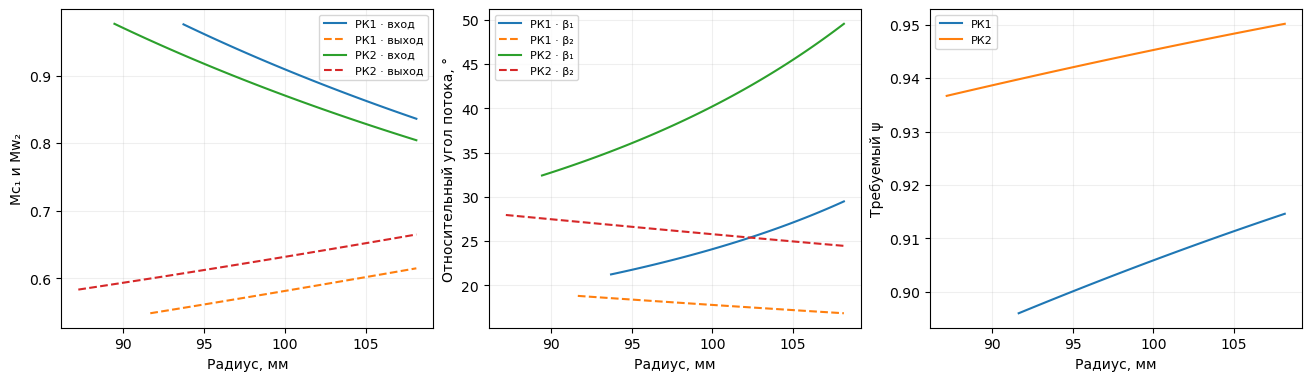

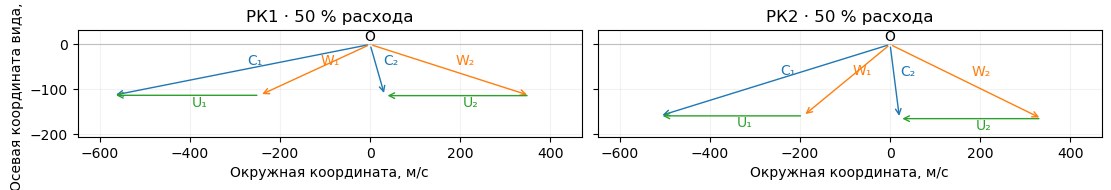

In [70]:
radial_checks = pd.DataFrame([
    {'Ступень':i,'ΔG СА, кг/с':rd['mass_in_residual'],
     'ΔG РК, кг/с':rd['mass_out_residual'],'max ΔLu, Дж/кг':rd['euler_max_residual'],
     'Отн. невязка радиального равновесия':rd['radial_eq_relative'],
     'Поправка скорости СА, %':rd['inlet_mean_velocity_change_pct'],
     'Mc₁ max':rd['inlet']['M_c'].max(),'Mw₂ max':rd['outlet']['M_w'].max(),
     'ψ min':rd['psi_required_min'],'ψ max':rd['psi_required_max']}
    for i,rd in enumerate(RADIAL_RESULTS,1)
])
display(radial_checks)

radial_sections = pd.concat([rd['sections'].assign(Ступень=i)
                            for i,rd in enumerate(RADIAL_RESULTS,1)],ignore_index=True)
radial_columns = {'r':'r, мм','T':'T, K','p':'p, кПа','ca':'cₐ, м/с',
                  'cu':'cᵤ, м/с','c':'c, м/с','w':'w, м/с','alpha':'α, °',
                  'beta':'β, °','M_c':'Mc','M_w':'Mw'}
for prefix,label in (('in','Вход РК'),('out','Выход РК')):
    columns = {prefix+'_'+k:v for k,v in radial_columns.items()}
    values = radial_sections[['Ступень','mass_fraction',*columns]].rename(
        columns={**columns,'mass_fraction':'Доля расхода'})
    values['r, мм'] *= 1e3
    values['p, кПа'] *= 1e-3
    print(label)
    with pd.option_context('display.max_columns',None):
        display(values.round(5))

radial_distribution = {
    side:pd.concat([rd[side].assign(Ступень=i) for i,rd in enumerate(RADIAL_RESULTS,1)],ignore_index=True)
    for side in ('inlet','outlet')
}
fig, axes = plt.subplots(1,3,figsize=(13,3.7),layout='constrained')
for i,rd in enumerate(RADIAL_RESULTS,1):
    for side,key,angle,style in (('inlet','M_c','β₁','-'),('outlet','M_w','β₂','--')):
        state = rd[side]
        label = f'РК{i} · {"вход" if side=="inlet" else "выход"}'
        axes[0].plot(state.r*1e3,state[key],style,label=label)
        axes[1].plot(state.r*1e3,state.beta,style,label=f'РК{i} · {angle}')
    axes[2].plot(rd['outlet'].r*1e3,rd['outlet']['psi_required'],label=f'РК{i}')
for ax,ylabel in zip(axes,('Mc₁ и Mw₂','Относительный угол потока, °','Требуемый ψ'),strict=True):
    ax.set(xlabel='Радиус, мм',ylabel=ylabel)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
plt.show()

# В каждом среднем массовом сечении вход и выход РК показываются из общего полюса.
fig, axes = plt.subplots(1,2,figsize=(11,3.8),layout='constrained',sharey=True)
colors = {'C':'tab:blue','W':'tab:orange','U':'tab:green'}
for i,(ax,rd) in enumerate(zip(axes,RADIAL_RESULTS,strict=True),1):
    values = rd['sections'].iloc[2]
    ax.axhline(0,color='0.75',lw=.8)
    for prefix,sign,suffix in (('in',1,'₁'),('out',-1,'₂')):
        key = prefix+'_'
        c = -np.array([sign*values[key+'cu'],values[key+'ca']])
        u = np.array([-2*np.pi*GEOMETRY[0]/60*values[key+'r'],0.])
        w = c-u
        for name,a,b in (('C',np.zeros(2),c),('W',np.zeros(2),w),('U',w,c)):
            color = colors[name]
            ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->','color':color})
            ax.annotate(name+suffix,(a+b)/2,xytext=(4,-8 if name=='U' else 4),
                        textcoords='offset points',color=color)
    ax.text(0,8,'O',ha='center')
    ax.set(title=f'РК{i} · 50 % расхода',xlabel='Окружная координата, м/с',
           aspect='equal',adjustable='box')
    ax.grid(alpha=.16)
    ax.autoscale_view()
    ax.set_xlim(-650,470)
    ax.set_ylim(-205,32)
axes[0].set_ylabel('Осевая координата вида, м/с')
plt.show()


## 4. Профили, меридиональный контур и потери

У лопатки две параболы спинки с общей касательной, параболическое корытце и круговые кромки. В таблице показаны проходы между соседними лопатками, угол по горлу и местное расширение приведённого канала. Подход к построению — Виноградов, 2010, §§4–5. Ориентиры геометрических проверок — Михальцев, ч. 1, 2006, с. 78–84.

Потери решёток оцениваются по смоченной длине, горлу, выходной кромке и высоте пера. Полученные коэффициенты скорости сравниваются с входными номинальными значениями. Невязки и геометрические замечания остаются в ведомостях.

Густота решётки — отношение хорды к окружному шагу, $b/t$, где $t=\pi D/Z$. В сводке для каждого венца указаны число лопаток $Z$, диаметр $D$ и густота на втулке, геометрической середине и периферии. Диаметры относятся к выходной стороне венца. Средний диаметр равен полусумме диаметров втулки и периферии. Хорда для него интерполируется линейно между соседними профилями по радиусу. В ведомости пяти профилей сечение 2 соответствует линии 50 % расхода. В `cascade_solidity.csv` дополнительно выводятся хорда $b$, шаг $t$ и $t/b$.

Диапазон чисел лопаток рассчитан для типичного ориентира $0{,}70\le t/b\le0{,}85$ по всем пяти сечениям, при сохранении диаметров и хорд. Этот тест показывает допустимый шаг при фиксированной геометрии. Выбор аэродинамического оптимума требует проверки потерь, горла и углов. Ориентир приведён у Михальцева и Молякова, ч. 1, с. 82–83.

Горло определяется по контакту спинки и выходной кромки соседней лопатки. Минимальный просвет между полными контурами проверяется отдельно. Окружности вписываются между стенками канала. Их приведённый диаметр $a'=a\,l(x)/l_\mathrm{вх}$ учитывает изменение высоты. Местное расширение — наибольшее отношение последующего приведённого диаметра к предыдущему, включая промежуточные пары точек. Для угла по горлу применяется $\theta_\mathrm{гор}=(l_\mathrm{гор}/l_\mathrm{вых})\arcsin(a_\mathrm{гор}/t)$.

До сопла меридиональные узлы соединены отрезками. Втулка сопла строится кубическим сплайном с нулевым наклоном на концах. Осевой зазор между венцами отсчитывается от выхода одного венца до входа следующего. Радиальный зазор в газодинамике — принятый рабочий размер 0,5 мм. Для холодного сборочного зазора нужны температурные деформации и допуски.

В ведомости НОД проверяются все шесть пар венцов, включая рабочие колёса разных ступеней. Для корневого сечения применяется принятый в геометрической проверке нижний предел t/b = 0,55. Ведомость типичного диапазона 0,70–0,85 показывает отклонения от общего ориентира.


Осевая ведомость венцов


,"x входа, мм","x выхода, мм","b_ax, мм","зазор после, мм","хорда среднего сечения, мм",Z
Венец,,,,,,
СА1,0.00000,30.61561,30.61561,7.04159,60.14343,13
РК1,37.65720,73.37455,35.71735,20.00000,55.51081,14
СА2,93.37455,121.50494,28.13039,6.46999,45.42944,17
РК2,127.97493,159.12770,31.15277,NaN,41.94828,19


Узлы меридионального канала


,station,"x, мм","r втулки, мм","r корпуса, мм","Площадь, см²",continuity_residual
0,Вход СА1,0.000000,96.509531,108.144276,74.804302,2.650102e-13
1,Выход СА1,30.615607,93.719951,108.144276,91.475493,2.648992e-13
2,Вход РК1,37.657197,93.719951,108.144276,91.475493,2.648992e-13
3,Кромка РК1,73.374548,91.661930,108.144276,103.461291,2.650102e-13
4,"После потерь РК1, 2+",79.374548,91.483691,108.144276,104.486824,2.626788e-13
5,Вход СА2,93.374548,89.316160,108.144276,116.798384,2.631229e-13
6,Выход СА2,121.504937,89.442711,108.144276,116.087693,2.644551e-13
7,Вход РК2,127.974927,89.442711,108.144276,116.087693,2.644551e-13
8,Кромка РК2,159.127695,87.203451,108.144276,128.514469,2.599032e-13
9,"После потерь РК2, 2+",165.127695,87.010581,108.144276,129.570064,2.582379e-13


Густота решёток на выходе каждого венца


Втулка         Геометрическая середина         Периферия        
             D, мм     b/t                   D, мм     b/t     D, мм     b/t
Венец Z                                                                     
СА1   13  187.4399  1.3598                201.8642  1.2337  216.2886  1.1802
РК1   14  183.3239  1.3744                199.8062  1.2381  216.2886  1.1793
СА2   17  178.8854  1.3772                197.5870  1.2438  216.2886  1.1785
РК2   19  174.4069  1.4953                195.3477  1.2977  216.2886  1.2443

... (3 outputs left out)

Контуры и межлопаточное горло во всех 20 сечениях


,Венец,Сечение,"r, мм",Z,"bа, мм","b, мм",t/b,"Горло, мм","Минимальный просвет, мм","Ошибка угла горла, °",Местное расширение,"F, мм²",Замечания
0,СА1,0,93.71995,13,30.61561,61.59694,0.73538,8.97928,8.97982,-0.10908,1.00000,266.51971,толщина тела без пережатия
1,СА1,1,97.49374,13,28.89846,60.79527,0.77507,9.22184,9.22226,-0.28051,1.00000,252.70900,толщина тела без пережатия
2,СА1,2,101.14313,13,28.86274,60.14343,0.81280,9.75563,9.75595,-0.07917,1.00000,252.78327,"максимальная толщина, толщина тела без пережатия"
3,СА1,3,104.68819,13,28.85802,60.15938,0.84107,10.59302,10.59329,0.44788,1.00000,246.28959,толщина тела без пережатия
4,СА1,4,108.14428,13,28.85218,61.68613,0.84733,10.47354,10.47380,-0.05584,1.00000,266.99870,толщина тела без пережатия
5,РК1,0,91.66193,14,35.71735,56.53782,0.72762,12.26456,12.26544,-1.84854,1.03169,211.67077,"местная диффузорность, толщина тела без пережатия"
6,РК1,1,96.06223,14,31.13434,55.55042,0.77610,12.49420,12.49545,-1.84956,1.00000,165.88704,
7,РК1,2,100.25950,14,30.02216,55.51081,0.81059,12.80870,12.80972,-1.66727,1.00000,164.44458,
8,РК1,3,104.27984,14,29.62864,55.84092,0.83811,13.05877,13.05957,-1.53674,1.00000,162.55512,
9,РК1,4,108.14428,14,28.97202,57.23729,0.84796,13.34908,13.34966,-1.35072,1.00000,156.43749,толщина тела без пережатия


,Венец,Сечение,"Угол установки, °","Угол входа по металлу, °","Угол выхода по металлу, °","Угол потока на выходе, °","Угол по горлу, °","Радиус входа, мм","Радиус выхода, мм","Макс. толщина, мм"
0,СА1,0,28.64614,94.11679,10.86667,11.20000,11.09092,1.16804,0.25,8.91239
1,СА1,1,27.23480,97.34279,10.70000,11.20000,10.91949,1.11839,0.25,8.71193
2,СА1,2,27.49898,91.08982,10.70000,11.20000,11.12083,1.14607,0.25,8.74269
3,СА1,3,27.51240,96.32910,10.70000,11.20000,11.64788,1.11482,0.25,8.45737
4,СА1,4,26.72565,94.92298,10.70000,11.20000,11.14416,1.14951,0.25,8.81299
5,РК1,0,37.97928,31.14267,17.82044,18.82044,16.97190,1.25155,0.25,6.38245
6,РК1,1,32.91461,32.07581,17.27461,18.27461,16.42505,1.10543,0.25,5.40626
7,РК1,2,31.58863,34.68094,16.76793,17.76793,16.10066,1.05997,0.25,5.45746
8,РК1,3,30.90366,34.56826,16.29717,17.29717,15.76042,1.04670,0.25,5.45906
9,РК1,4,29.27117,38.99201,15.85897,16.85897,15.50825,1.05330,0.25,5.55731


,Венец,Aкор/Aпериф,Цель,Площади убывают,Цель достигнута
0,РК1,1.35307,1.6,True,False
1,РК2,1.06695,1.6,True,False


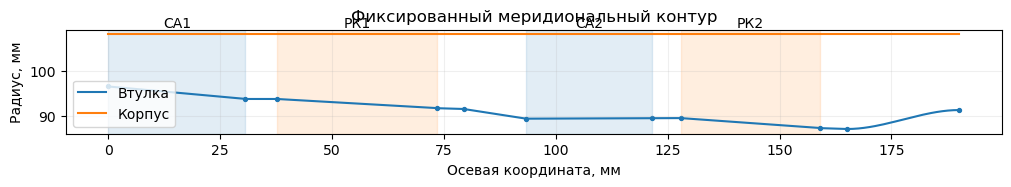

In [71]:
print('Осевая ведомость венцов')
display(drawing_schedule(CHANNEL,PROFILES).round(5))
print('Узлы меридионального канала')
display(CHANNEL_STATIONS.assign(
    **{'x, мм':CHANNEL_STATIONS.x*1e3,'r втулки, мм':CHANNEL_STATIONS.rhub*1e3,
       'r корпуса, мм':CHANNEL_STATIONS.rtip*1e3,'Площадь, см²':CHANNEL_STATIONS.A*1e4}
)[['station','x, мм','r втулки, мм','r корпуса, мм','Площадь, см²','continuity_residual']])

solidity_table, blade_count_check = cascade_solidity_report(PROFILES)
section_order = solidity_table['Сечение'].unique()
solidity_overview = (
    solidity_table.pivot(index=['Венец','Z'], columns='Сечение', values=['D, мм','b/t'])
    .swaplevel(axis='columns')
    .reindex(list(BLADE_COUNTS), level='Венец')
    .reindex(pd.MultiIndex.from_product([section_order, ['D, мм','b/t']]), axis='columns')
)
print('Густота решёток на выходе каждого венца')
with pd.option_context('display.max_columns', None, 'display.width', 120):
    display(solidity_overview.round(4))
display(blade_count_check.round(4))
print('Попарная взаимная простота чисел лопаток')
display(blade_count_pairs)
print('Контуры и межлопаточное горло во всех 20 сечениях')
display(profile_checks.round(5))
profile_angles = pd.DataFrame([
    {'Венец':row,'Сечение':j,'Угол установки, °':p['stagger_deg'],
     'Угол входа по металлу, °':p['beta_in_metal'],
     'Угол выхода по металлу, °':p['beta_out_metal'],
     'Угол потока на выходе, °':p['beta_out_flow'],
     'Угол по горлу, °':p['throat_angle_deg'],
     'Радиус входа, мм':p['rLE']*1e3,'Радиус выхода, мм':p['rTE']*1e3,
     'Макс. толщина, мм':p['maximum_thickness_m']*1e3}
    for (row,j),p in PROFILES.items()
])
display(profile_angles.round(5))
display(taper_checks.round(5))

fig,ax = plt.subplots(figsize=(10,3),layout='constrained')
stations = CHANNEL['stations']
contour = CHANNEL['contour']
ax.plot(contour.x*1e3,contour.rhub*1e3,label='Втулка')
ax.plot(contour.x*1e3,contour.rtip*1e3,label='Корпус')
for row in CHANNEL['blade_rows'].itertuples():
    ax.axvspan(row.x_le*1e3,row.x_te*1e3,alpha=.13,color='tab:blue' if row.kind=='СА' else 'tab:orange')
    ax.text((row.x_le+row.x_te)*.5e3, row.rtip*1e3+1.5,row.name,ha='center')
ax.scatter(stations.x*1e3,stations.rhub*1e3,s=8)
ax.set(xlabel='Осевая координата, мм',ylabel='Радиус, мм',title='Фиксированный меридиональный контур')
ax.set_aspect('equal',adjustable='box')
ax.grid(alpha=.2)
ax.legend(loc='lower left')
plt.show()


## 5. Потери решёток

Для каждого профиля вычисляются профильные и концевые потери:
$$\zeta_\mathrm{пр}=\zeta_\mathrm{тр}+\zeta_\mathrm{кр},\qquad
\zeta_\mathrm{тр}=C_f L_\mathrm{смоч}/a,\qquad
\zeta_\mathrm{кр}=0{,}2\,s_2/a,\qquad
\zeta_\mathrm{к}=2\zeta_\mathrm{пр}\,t\sin\theta/l.$$
Здесь $a$ — измеренное горло, $s_2$ — толщина выходной кромки, $L_\mathrm{смоч}$ — суммарная длина спинки и корытца, $l$ — выходная высота пера, $\theta=\alpha_1$ в СА и $\theta=\beta_2$ в РК. Для трения принято $C_f=0{,}074/Re^{0{,}2}$ как приближение для гладкой поверхности. Вязкость рассчитана по закону Сазерленда для воздуха как приближение для продуктов сгорания. Основа схемы — Михальцев и Моляков, ч. 2, 2008, с. 8–14 и пп. 4.5–4.6 исходной расчётной записки.

Потери усредняются по массовой координате с весом $V^2$. Из $\sqrt{1-\overline\zeta}$ получаем оценку коэффициента скорости и сравниваем её с номинальным входным $\phi$ или $\psi$. Невязка остаётся в отчёте. Потери зазора и диска уже учтены в газодинамическом расчёте ступени.


In [72]:
loss_sections, loss_rows = cascade_loss_review(P0,RADIAL_RESULTS,CHANNEL,PROFILES)
print('Средние потери четырёх венцов')
display(loss_rows.round(6))
print('Число Рейнольдса и составляющие потерь по сечениям')
display(loss_sections[[
    'Венец','Сечение','Re','Cf','Смоченная длина, мм','ζ трения',
    'ζ кромочные','ζ профильные','ζ концевые','ζ сумма','Коэффициент локальный'
]].round(6))
print(f"Максимальная невязка φ/ψ: {loss_rows['Невязка коэффициента'].abs().max():.6f}")


Средние потери четырёх венцов


,Венец,ζ трения,ζ кромочные,ζ концевые,ζ сумма,Коэффициент в ступени,Коэффициент по потерям,Невязка коэффициента
0,СА1,0.072899,0.010271,0.108719,0.191889,0.903022,0.898950,-0.004072
1,РК1,0.062271,0.007808,0.116620,0.186700,0.908467,0.901832,-0.006636
2,СА2,0.059575,0.009251,0.079076,0.147903,0.929007,0.923091,-0.005916
3,РК2,0.049494,0.007373,0.077421,0.134288,0.945803,0.930436,-0.015366


Число Рейнольдса и составляющие потерь по сечениям


,Венец,Сечение,Re,Cf,"Смоченная длина, мм",ζ трения,ζ кромочные,ζ профильные,ζ концевые,ζ сумма,Коэффициент локальный
0,СА1,0,665053.062856,0.005066,141.682779,0.079935,0.011137,0.091072,0.111099,0.202171,0.893213
1,СА1,1,650010.058520,0.005089,138.725718,0.076557,0.010844,0.087401,0.110915,0.198316,0.895368
2,СА1,2,635896.742724,0.005112,138.835206,0.072744,0.010250,0.082995,0.109266,0.192260,0.898743
3,СА1,3,628394.517270,0.005124,137.247903,0.066385,0.009440,0.075825,0.103326,0.179151,0.906007
4,СА1,4,636149.395216,0.005111,141.226715,0.068920,0.009548,0.078468,0.110456,0.188924,0.900598
5,РК1,0,321202.609524,0.005860,147.847455,0.070638,0.008154,0.078791,0.126882,0.205673,0.891250
6,РК1,1,325557.668579,0.005844,137.243155,0.064193,0.008004,0.072197,0.118432,0.190629,0.899650
7,РК1,2,335033.909778,0.005811,135.508035,0.061472,0.007807,0.069279,0.115430,0.184709,0.902935
8,РК1,3,346552.930484,0.005771,135.707592,0.059976,0.007658,0.067634,0.114199,0.181833,0.904526
9,РК1,4,364751.571940,0.005713,135.890459,0.058153,0.007491,0.065644,0.112120,0.177764,0.906772


Максимальная невязка φ/ψ: 0.015366


## 6. Прочность РК1 и РК2

Для каждого пера вычисляются площадь $F$, центр площади и моменты инерции по замкнутому контуру. Центральные главные оси определяются диагонализацией матрицы вторых моментов. Ведомость Чебышёва служит проверкой площадей и моментов по шести измеренным хордам.

**Пять сечений.** Центробежная сила вычисляется методом трапеций по пяти фактическим площадям. Для каждого радиуса $N(r)=\rho_{мат}\omega^2\int_r^{R_п}sF(s)\,ds$, а напряжение растяжения равно $\sigma_N=N/F$.

**Три сечения.** По корню, линии 50 % расхода и периферии строится квадратичная аппроксимация $F(r)$. При удельном расходе полоски $g'(r)$ газовые нагрузки на одну лопатку берутся по схеме ДЗ «УКР»:
$$q_x=\frac{2\pi r(p_1-p_2)-g'(c_{2a}-c_{1a})}{Z},\qquad
q_y=\frac{g'}{Z}\left(\frac{r_1}{r}c_{1u}+c_{2u}\right).$$
Входной радиус $r_1$ соответствует той же массовой линии. Осевая составляющая давления считается по кольцевым полоскам. Для номинального расчёта центры площадей сечений укладываются на одной радиальной оси.
$$M_\xi=-\int_r^{R_п}(s-r)q_y(s)\,ds,\quad
M_\eta=\int_r^{R_п}(s-r)q_x(s)\,ds,\quad
\sigma_\Sigma=\frac NF+\frac{M_uv}{I_u}-\frac{M_vu}{I_v}.$$
В ведомости также рассчитан центробежный крутящий момент. Экстремумы нормальных напряжений ищутся по всему контуру.

**Длительная прочность.** Для обоих РК принят отечественный литейный сплав ЖС6У с равноосной структурой. Верхняя тепловая оценка взята из максимальной относительной полной температуры по обеим сторонам РК, определяемой из $h(T^*_\mathrm{отн})=h(T)+w^2/2$. Запас вычисляется как отношение предела длительной прочности к максимальному номинальному растягивающему напряжению пера. Источники, проверка на 10 000 ч и восстановленный архивный расчёт приведены ниже.


In [73]:
def mechanical_trapezoid_sections(r,profiles,density_kg_m3):
    """Предварительная прочность каждого из пяти сечений: составные трапеции, СИ."""
    omega=2*math.pi*r['geometry'][0]/60;rows=[]
    for rotor in range(1,len(r['stages'])+1):
        points=[profiles[(f'РК{rotor}',j)] for j in range(5)]
        radius=np.array([p['radius'] for p in points]);area=np.array([p['area'] for p in points])
        if np.any(np.diff(radius)<=0) or np.any(area<=0):raise ValueError('Нужны положительные площади на возрастающих радиусах')
        force=-cumulative_trapezoid((density_kg_m3*omega**2*radius*area)[::-1],radius[::-1],initial=0.)[::-1]
        for j,(rr,F,N) in enumerate(zip(radius,area,force)):
            rows.append(dict(rotor=rotor,section=j,r=rr,F=F,N=N,sigma_tension=N/F))
    return pd.DataFrame(rows)


def ukr_slice_intervals(polygon,abscissa,axis=0):
    """Ординаты пересечений контура с прямой; полуоткрытые рёбра без удвоения вершин."""
    p=np.asarray(polygon);a=p[:-1];b=p[1:]
    hit=((a[:,axis]<=abscissa)&(abscissa<b[:,axis]))|((b[:,axis]<=abscissa)&(abscissa<a[:,axis]))
    aa=a[hit];bb=b[hit]
    yy=aa[:,1-axis]+(abscissa-aa[:,axis])*(bb[:,1-axis]-aa[:,1-axis])/(bb[:,axis]-aa[:,axis])
    yy=np.sort(yy)
    if len(yy)%2:raise ValueError('Нечётное число пересечений контура')
    return yy.reshape(-1,2)

def ukr_chebyshev(polygon):
    """Ручная схема ДЗ: шесть ординат, отдельные узлы площади, S и I."""
    p=np.asarray(polygon);center=(p.min(axis=0)+p.max(axis=0))/2;p=p-center
    a=np.ptp(p,axis=0)/2
    nodes_F=np.array([.8662,.4225,.2666,-.2666,-.4225,-.8662])
    nodes_S=np.array([.9295,.7118,.4437,-.4437,-.7118,-.9295])
    nodes_I=np.array([.9410,.8133,.5030,-.5030,-.8133,-.9410])
    def widths(nodes,axis):
        return np.array([np.diff(ukr_slice_intervals(p,float(t*a[axis]),axis),axis=1).sum() for t in nodes])
    f=widths(nodes_F,0);F=2*a[0]*f.mean()
    S=[];I=[]
    for axis in (0,1):
        w=widths(nodes_S,axis)
        S.append(.1599*a[axis]**2*(w[:3].sum()-w[3:].sum()))
        I.append(a[axis]**3/9*widths(nodes_I,axis).sum())
    c=np.asarray(S)/F
    return dict(F=F,centroid=c+center,Ixi=I[1]-F*c[1]**2,Ieta=I[0]-F*c[0]**2,
                nodes=nodes_F*a[0]+center[0],widths=f)

def ukr_tail(r,values):
    """Интеграл от текущего радиуса до конца: первообразная PCHIP, без разности сумм сетки."""
    antiderivative=PchipInterpolator(r,values).antiderivative()
    return antiderivative(r[-1])-antiderivative(r)

def ukr_gas_loads(r,stage,radial,Z,cfg,mode):
    if mode=='homework':
        # Свободный вихрь и постоянная осевая скорость — допущения раздела 2 ДЗ.
        c1u=stage['c1u']*(stage['Dc']/2)/r;c2u=stage['c2u']*(stage['Dl']/2)/r
        c1a=np.full_like(r,stage['c1a']);c2a=np.full_like(r,stage['c2a'])
        pressure=[]
        for index,cu in ((1,c1u),(2,c2u)):
            T=stage[f'T{index}'];k=sound(T,stage['alpha'],cfg)**2/(cfg.R*T)
            cm=stage[f'c{index}u'];base=1+(k-1)/2*(cm/sound(T,stage['alpha'],cfg))**2*(1-(stage['Dc' if index==1 else 'Dl']/2/r)**2)
            if np.any(base<=0):raise ValueError('Свободный вихрь ДЗ: недопустимое давление по радиусу')
            pressure.append(stage[f'p{index}']*base**(k/(k-1)))
        p1,p2=pressure;mass_per_span=2*math.pi*r*p1/(cfg.R*stage['T1'])*c1a
        c1u_equivalent=c1u
    elif mode=='radial':
        # Массовое отображение существующей осесимметричной модели на выходной радиус.
        inlet=radial['inlet'];outlet=radial['outlet'];G=stage['G']
        f=np.interp(r,outlet.r,outlet.mass/G)
        def upstream(key):return np.interp(f,inlet.mass/G,inlet[key])
        p1=upstream('p');p2=np.interp(r,outlet.r,outlet.p)
        c1a=upstream('ca');c2a=np.interp(r,outlet.r,outlet.ca)
        c1u=upstream('cu');c2u=np.interp(r,outlet.r,outlet.cu)
        mass_per_span=PchipInterpolator(outlet.r,outlet.mass).derivative()(r)
        # Эквивалентный входной вихрь переносит момент количества движения к выходному цилиндру.
        c1u_equivalent=upstream('r')/r*c1u
    else:raise ValueError(mode)
    # Сила на ЛОПАТКУ: +eta по вращению; физический c2theta=-c2u.
    # Давление — полосочная аппроксимация ДЗ, не интеграл по поверхности 3D-лопатки.
    qx=(2*math.pi*r*(p1-p2)-mass_per_span*(c2a-c1a))/Z
    qy=mass_per_span*(c1u_equivalent+c2u)/Z
    return qx,qy

def ukr_area_laws(r,F,omega,density):
    rk,rp=r[0],r[-1];t=(r-rk)/(rp-rk);chi=F[-1]/F[0]
    baseline=density*omega**2*(rp*rp-rk*rk)/2
    laws=[]
    def add(name,area):
        sigma=density*omega**2*ukr_tail(r,r*area)/area
        laws.append(dict(name=name,r=r,F=area,sigma=sigma,beta=float(sigma.max()/baseline)))
    add('Текущий профиль: три сечения',F)
    add('Постоянная площадь',np.full_like(r,F[0]))
    add(f'Линейный, χ={chi:.3f}',F[0]*(1+(chi-1)*t))
    add(f'Экспоненциальный, χ={chi:.3f}',F[0]*chi**t)
    def equal_strength(chi_value,label):
        if not 0<chi_value<1:return None
        R3sq=(rk*rk-rp*rp*math.log(chi_value))/(1-math.log(chi_value))
        sigma_max=density*omega**2*(rp*rp-R3sq)/2
        area=F[0]*chi_value*np.exp(np.maximum(R3sq-r*r,0)*density*omega**2/(2*sigma_max))
        add(label,area)
        return math.sqrt(R3sq)
    transition=equal_strength(chi,'Почти равнопрочный: текущая χ')
    return laws,dict(chi=chi,baseline=baseline,transition=transition)

def ukr_balancing_offsets(r,F,qx,qy,density,omega):
    """Компенсационные выносы: газовый интеграл ВНУТРИ интеграла по высоте."""
    Phi=ukr_tail(r,r*F);Qx=ukr_tail(r,qx);Qyr=ukr_tail(r,r*qy)
    xprime=np.empty_like(r);vprime=np.empty_like(r)
    xprime[:-1]=Qx[:-1]/(density*omega**2*Phi[:-1])
    vprime[:-1]=Qyr[:-1]/(density*omega**2*r[:-1]**2*Phi[:-1])
    # Пределы отношений при r -> Rп; Phi(Rп)=0, но выносы конечны.
    xprime[-1]=qx[-1]/(density*omega**2*r[-1]*F[-1])
    vprime[-1]=qy[-1]/(density*omega**2*r[-1]**2*F[-1])
    x=cumulative_trapezoid(xprime,r,initial=0.)
    y=r*cumulative_trapezoid(vprime,r,initial=0.)
    Mxi_q=-(ukr_tail(r,r*qy)-r*ukr_tail(r,qy))
    Meta_q=ukr_tail(r,r*qx)-r*ukr_tail(r,qx)
    Mxi_omega=density*omega**2*(r*ukr_tail(r,y*F)-y*Phi)
    Meta_omega=density*omega**2*(x*Phi-ukr_tail(r,x*r*F))
    return pd.DataFrame(dict(r=r,x=x,y=y,Mxi_residual=Mxi_q+Mxi_omega,Meta_residual=Meta_q+Meta_omega))

def ukr_rotor_strength(result,profiles,radials,cfg,material,nodes=801,load_model='radial',rotor=None):
    number=len(result['stages']) if rotor is None else int(rotor)
    if number not in (1,2):raise ValueError('Нужен номер РК 1 или 2')
    stage=result['stages'][number-1];radial=radials[number-1]
    omega=2*math.pi*result['geometry'][0]/60;density=material['density_kg_m3']
    sections=[];geometry_rows=[];cheb_rows=[];ordinate_rows=[]
    for j,name in ((0,'Корневое'),(2,'Среднее'),(4,'Периферийное')):
        profile=profiles[(f'РК{number}',j)];poly=profile['polygon']
        sec=ukr_section_properties(poly);sec.update(name=name,r=profile['radius'],polygon=poly)
        sections.append(sec);cheb=ukr_chebyshev(poly)
        geometry_rows.append({'Сечение':name,'r, мм':sec['r']*1e3,'F, мм²':sec['F']*1e6,
            'ξц, мм':sec['centroid'][0]*1e3,'ηц, мм':sec['centroid'][1]*1e3,
            'Iξ, мм⁴':sec['Ixi']*1e12,'Iη, мм⁴':sec['Ieta']*1e12,'Iξη, мм⁴':sec['Ixy']*1e12,
            'Iu, мм⁴':sec['Iu']*1e12,'Iv, мм⁴':sec['Iv']*1e12,'φ, °':math.degrees(sec['principal_angle_rad'])})
        cheb_rows.append({'Сечение':name,'F Чебышёв, мм²':cheb['F']*1e6,'ΔF, %':100*(cheb['F']/sec['F']-1),
            'Δξц, мм':(cheb['centroid'][0]-sec['centroid'][0])*1e3,'Δηц, мм':(cheb['centroid'][1]-sec['centroid'][1])*1e3,
            'Iξ Чебышёв, мм⁴':cheb['Ixi']*1e12,'Iη Чебышёв, мм⁴':cheb['Ieta']*1e12})
        for i,(xx,ww) in enumerate(zip(cheb['nodes'],cheb['widths']),1):
            ordinate_rows.append({'Сечение':name,'Узел':i,'ξ, мм':xx*1000,'f(ξ), мм':ww*1000})
    radii=np.array([s['r'] for s in sections]);areas=np.array([s['F'] for s in sections])
    r=np.unique(np.r_[np.linspace(radii[0],radii[-1],nodes),radii])
    area_polynomial=np.polynomial.Polynomial.fit(radii,areas,2).convert()
    F=area_polynomial(r)
    # Квадратичный закон ДЗ должен оставаться положительным и МЕЖДУ сечениями.
    extrema=area_polynomial.deriv().roots()
    probes=np.r_[radii,extrema[(extrema>=radii[0])&(extrema<=radii[-1])]]
    if np.any(area_polynomial(probes)<=0):raise ValueError('Квадратичная F(r) неположительна; нужны другие сечения/закон')
    Phi_polynomial=(area_polynomial*np.polynomial.Polynomial([0,1])).integ()
    N=density*omega**2*(Phi_polynomial(r[-1])-Phi_polynomial(r))
    Ixy_polynomial=np.polynomial.Polynomial.fit(radii,[s['Ixy'] for s in sections],2).convert().integ()
    Tomega=density*omega**2*(Ixy_polynomial(r[-1])-Ixy_polynomial(r))
    Z=profiles[(f'РК{number}',0)]['Z'];qx,qy=ukr_gas_loads(r,stage,radial,Z,cfg,load_model)
    Mxi=-(ukr_tail(r,r*qy)-r*ukr_tail(r,qy));Meta=ukr_tail(r,r*qx)-r*ukr_tail(r,qx)
    span=pd.DataFrame(dict(r=r,F=F,N=N,qx=qx,qy=qy,Mxi=Mxi,Meta=Meta,Tomega=Tomega,sigma_tension=N/F))
    stress_rows=[];point_rows=[]
    for sec in sections:
        index=np.searchsorted(r,sec['r']);basis=sec['principal_axes'];p=sec['centered']
        sec.update(N=N[index],Mxi=Mxi[index],Meta=Meta[index],Tomega=Tomega[index],sigma_tension=N[index]/sec['F'])
        Mu,Mv=basis.T@np.array([sec['Mxi'],sec['Meta']]);uv=p@basis
        gradient=basis@np.array([-Mv/sec['Iv'],Mu/sec['Iu']])
        bending=p@gradient;total=sec['sigma_tension']+bending
        sec.update(Mu=Mu,Mv=Mv,stress_gradient=gradient,sigma_bending=bending,sigma_total=total,
                   neutral_angle_rad=math.atan2(gradient[0],-gradient[1]) if np.linalg.norm(gradient)>1e-10 else None)
        # A — входная кромка, B — выходная; C — максимальный прогиб контура от хорды.
        A=int(np.argmin(sec['polygon'][:,0]));B=int(np.argmax(sec['polygon'][:,0]))
        chord=p[B]-p[A];distance=(chord[0]*(p[:,1]-p[A,1])-chord[1]*(p[:,0]-p[A,0]))/np.linalg.norm(chord)
        Cpoint=int(np.argmax(np.abs(distance)))
        sec['points']={'A':A,'B':B,'C':Cpoint}
        stress_rows.append({'Сечение':sec['name'],'N, Н':sec['N'],'Mξ, Н·м':sec['Mxi'],'Mη, Н·м':sec['Meta'],
            'Mu, Н·м':Mu,'Mv, Н·м':Mv,'Mzω, Н·м':sec['Tomega'],'σN, МПа':sec['sigma_tension']/1e6,
            'σизг min, МПа':bending.min()/1e6,'σизг max, МПа':bending.max()/1e6,
            'σΣ min, МПа':total.min()/1e6,'σΣ max, МПа':total.max()/1e6,
            'β нейтр., °':math.degrees(sec['neutral_angle_rad']) if sec['neutral_angle_rad'] is not None else None})
        for label,vertex in sec['points'].items():
            point_rows.append({'Сечение':sec['name'],'Точка':label,'ξ−ξц, мм':p[vertex,0]*1000,'η−ηц, мм':p[vertex,1]*1000,
                'u, мм':uv[vertex,0]*1000,'v, мм':uv[vertex,1]*1000,'σизг, МПа':bending[vertex]/1e6,'σΣ, МПа':total[vertex]/1e6})
    laws,law_info=ukr_area_laws(r,F,omega,density)
    offsets=ukr_balancing_offsets(r,F,qx,qy,density,omega)
    return dict(rotor=number,sections=sections,span=span,area_laws=laws,area_law_info=law_info,offsets=offsets,
                geometry_table=pd.DataFrame(geometry_rows),chebyshev_table=pd.DataFrame(cheb_rows),
                ordinates_table=pd.DataFrame(ordinate_rows),section_table=pd.DataFrame(stress_rows),points_table=pd.DataFrame(point_rows),
                omega=omega,density=density,Z=Z,area_coefficients=area_polynomial.coef,load_model=load_model)

def lm_sigma(P, points):
    """P в K, результат MPa; NaN означает вне оцифрованного графика."""
    p = np.asarray(P, dtype=float) / 1000.
    return np.where((p >= points[0, 0]) & (p <= points[-1, 0]),
                    np.exp(np.interp(p, points[:, 0], np.log(points[:, 1]))), np.nan)

def lm_parameter(sigma_MPa, points):
    """Обратная интерполяция той же logσ(P), без экстраполяции."""
    s = np.asarray(sigma_MPa, dtype=float)
    valid = (s >= points[-1, 1]) & (s <= points[0, 1])
    log_s = np.log(np.where(s > 0, s, 1.))
    return np.where(valid, 1000.*np.interp(log_s, np.log(points[::-1, 1]), points[::-1, 0]), np.nan)

def candidate_temperature_bound(radial, stage, cfg):
    """Maximum relative total temperature over BOTH complete radial states.

    recovery=1, no cooling: a conservative thermal bound, NOT an independently
    solved metal temperature. No user-assigned temperatures or fixed cp.
    """
    sides = {}
    for side in ('inlet', 'outlet'):
        frame = radial[side]
        radius = np.asarray(frame['r'], dtype=float)
        temperature = np.asarray(frame['T'], dtype=float)
        speed = np.asarray(frame['w'], dtype=float)
        if (radius.ndim != 1 or len(radius) < 2 or
                temperature.shape != radius.shape or speed.shape != radius.shape or
                not np.all(np.isfinite(radius)) or np.any(np.diff(radius) <= 0) or
                not np.all(np.isfinite(temperature)) or np.any(temperature <= 0) or
                not np.all(np.isfinite(speed)) or np.any(speed < 0)):
            raise ValueError(f'{side}: недопустимые радиальные состояния r, T, w')
        relative_total = np.array([
            inv_h(h(float(T), stage['alpha'], cfg) + float(w)**2 / 2,
                  stage['alpha'], cfg)
            for T, w in zip(temperature, speed)
        ], dtype=float)
        if not np.all(np.isfinite(relative_total)) or np.any(relative_total <= 0):
            raise ValueError(f'{side}: недопустимая относительная полная температура')
        sides[side] = dict(r_m=radius.copy(), relative_total_K=relative_total,
                           min_K=float(relative_total.min()),
                           max_K=float(relative_total.max()))
    return dict(
        min_relative_total_K=min(side['min_K'] for side in sides.values()),
        upper_K=max(side['max_K'] for side in sides.values()),
        sides=sides,
        origin='max inv_h(h(T)+w²/2) по обоим полным радиальным состояниям; '
               'recovery=1, без охлаждения; верхняя тепловая оценка, не расчёт Tмет',
    )

def _candidate_lm_rows(rotor, stresses, bound, requirements, points):
    """Evaluate only tensile normal stress; unknown allowable always fails."""
    rows = []
    temperature = bound['upper_K']
    life = float(requirements['life_hours'])
    C = float(requirements['C_LM'])
    P = temperature * (C + np.log10(life))
    allowed = float(lm_sigma(P, points))
    known = bool(np.isfinite(allowed) and allowed > 0)
    required = float(requirements['required_margin'])
    for stress in stresses:
        sigma = float(stress['sigma_normal_max_MPa'])
        if not np.isfinite(sigma) or sigma < 0:
            raise ValueError('Неконечное/отрицательное расчётное растягивающее напряжение')
        # At the free tip N=M=0: infinity is valid ONLY with a known allowable.
        margin = allowed / sigma if known and sigma > 0 else (np.inf if known else np.nan)
        inverse = float(lm_parameter(sigma, points)) if sigma > 0 else np.nan
        loglife = inverse / temperature - C if np.isfinite(inverse) else np.nan
        rupture = 10.**loglife if np.isfinite(loglife) and loglife < 308 else np.nan
        design_P=float(lm_parameter(required*sigma,points)) if sigma>0 else np.nan
        design_loglife=design_P/temperature-C if np.isfinite(design_P) else np.nan
        design_life=10.**design_loglife if np.isfinite(design_loglife) and design_loglife<308 else np.nan
        passed = bool(known and margin >= required)
        reason = ('' if passed else
                  'P вне документированной LM-кривой: допуск неизвестен' if not known else
                  'Запас длительной прочности по нормальным напряжениям ниже требования')
        rows.append(dict(
            rotor=rotor, **stress, T_bound_K=temperature,
            life_hours=life, P_K=P, allowable_MPa=allowed, margin=margin,
            required_margin=required, rupture_hours=rupture, design_life_hours=design_life, passed=passed,
            material=requirements['material'], reason=reason,
            scope='Только длительная прочность по нормальным напряжениям, не общий запас',
        ))
    return rows

def candidate_strength(result, profiles, radials, cfg, requirements):
    """Screen actual five-section profiles of BOTH rotors, without side effects.

    requirements has mandatory material, life_hours, C_LM, curve_points
    (P/1000 in K, stress in MPa), required_margin and density_kg_m3.
    Curve provenance and material/life suitability must be justified by caller.
    Unknown requirements/allowables yield passed=False, never a green fallback.

    table contains five-section trapezoidal centrifugal tension AND three-section
    quadratic-area centrifugal tension + gas bending. Both methods must meet the
    required normal-stress LM margin. They are not summed or conflated.
    """
    rows, reasons, rotor_results, bounds = [], [], {}, {}

    def finish():
        table = pd.DataFrame(rows)
        if table.empty:
            minimum = np.nan
        else:
            margins = table['margin'].to_numpy(dtype=float)
            minimum = float(np.min(margins)) if not np.any(np.isnan(margins)) else np.nan
        passed = bool(not reasons and len(rotor_results) == 2 and
                      not table.empty and table['passed'].all())
        return dict(table=table, passed=passed, min_margin=minimum,
                    rotor_results=rotor_results, temperature_bounds=bounds,
                    reasons=reasons)

    required = ('material', 'life_hours', 'C_LM', 'curve_points',
                'required_margin', 'density_kg_m3')
    missing = [key for key in required if key not in requirements or requirements[key] is None]
    if missing:
        reasons.append('Не заданы требования: ' + ', '.join(missing))
        return finish()
    try:
        if not isinstance(requirements['material'], str) or not requirements['material'].strip():
            raise ValueError('Нужна явно идентифицированная марка материала')
        life, C = float(requirements['life_hours']), float(requirements['C_LM'])
        density = float(requirements['density_kg_m3'])
        margin = float(requirements['required_margin'])
        if (not np.isfinite(life) or life <= 0 or not np.isfinite(C) or
                C + np.log10(life) <= 0):
            raise ValueError('Ресурс должен быть >0 ч, C_LM конечен, C_LM+log10(ресурс)>0')
        if not np.isfinite(density) or density <= 0 or not np.isfinite(margin) or margin <= 0:
            raise ValueError('Плотность и требуемый запас должны быть конечными и >0')
        points = np.asarray(requirements['curve_points'], dtype=float)
        if (points.ndim != 2 or points.shape[1] != 2 or len(points) < 2 or
                not np.all(np.isfinite(points)) or np.any(points[:, 0] <= 0) or
                np.any(points[:, 1] <= 0) or np.any(np.diff(points[:, 0]) <= 0) or
                np.any(np.diff(points[:, 1]) >= 0)):
            raise ValueError('LM-кривая: возрастающие P/1000>0 и убывающие σ>0, без экстраполяции')
        if len(result['stages']) != 2 or len(radials) != 2:
            raise ValueError('Проверка требует обе ступени и радиальные состояния обоих РК')
        # Recompute areas from the actual polygons; do not trust stale cached area.
        actual_areas = {}
        for rotor in (1, 2):
            radii = []
            for j in range(5):
                profile = profiles[(f'РК{rotor}', j)]
                polygon = np.asarray(profile['polygon'], dtype=float)
                if (polygon.ndim != 2 or polygon.shape[1] != 2 or len(polygon) < 4 or
                        not np.all(np.isfinite(polygon))):
                    raise ValueError(f'РК{rotor}, сечение {j}: недопустимый реальный контур')
                radius = float(profile['radius'])
                if not np.isfinite(radius) or radius <= 0:
                    raise ValueError(f'РК{rotor}, сечение {j}: недопустимый радиус')
                area = ukr_section_properties(polygon)['F']
                actual_areas[(f'РК{rotor}', j)] = dict(radius=radius, area=area)
                radii.append(radius)
            if np.any(np.diff(radii) <= 0):
                raise ValueError(f'РК{rotor}: пять радиусов должны строго возрастать')
        trapezoids = mechanical_trapezoid_sections(result, actual_areas, density_kg_m3=density)
    except (KeyError, TypeError, ValueError, IndexError, FloatingPointError, OverflowError) as error:
        reasons.append(str(error))
        return finish()

    for rotor in (1, 2):
        try:
            bound = candidate_temperature_bound(radials[rotor-1], result['stages'][rotor-1], cfg)
            bounds[rotor] = bound
            ukr = ukr_rotor_strength(
                result, profiles, radials, cfg, requirements,
                rotor=rotor, load_model='radial',
            )
            rotor_results[rotor] = ukr
            preliminary = trapezoids.loc[trapezoids['rotor'] == rotor].copy()
            stresses = []
            for entry in preliminary.itertuples(index=False):
                stresses.append(dict(
                    method='trapezoid_5_tension', section=int(entry.section),
                    section_name=f'Сечение {entry.section}', r_m=float(entry.r),
                    sigma_tension_MPa=float(entry.sigma_tension) / 1e6,
                    sigma_bending_min_MPa=np.nan, sigma_bending_max_MPa=np.nan,
                    sigma_normal_min_MPa=float(entry.sigma_tension) / 1e6,
                    sigma_normal_max_MPa=max(0., float(entry.sigma_tension)) / 1e6,
                ))
            for index, section in zip((0, 2, 4), ukr['sections']):
                total = np.asarray(section['sigma_total'], dtype=float)
                bending = np.asarray(section['sigma_bending'], dtype=float)
                if not np.all(np.isfinite(total)) or not np.all(np.isfinite(bending)):
                    raise ValueError('Неконечные нормальные напряжения UKR')
                stresses.append(dict(
                    method='quadratic_3_tension_gas_bending', section=index,
                    section_name=section['name'], r_m=float(section['r']),
                    sigma_tension_MPa=float(section['sigma_tension']) / 1e6,
                    sigma_bending_min_MPa=float(bending.min()) / 1e6,
                    sigma_bending_max_MPa=float(bending.max()) / 1e6,
                    sigma_normal_min_MPa=float(total.min()) / 1e6,
                    sigma_normal_max_MPa=max(0., float(total.max())) / 1e6,
                ))
            rotor_rows = _candidate_lm_rows(rotor, stresses, bound, requirements, points)
            rows.extend(rotor_rows)
            ukr['trapezoid_table'] = preliminary
            ukr['lm_table'] = pd.DataFrame(rotor_rows)
            for row in rotor_rows:
                if not row['passed']:
                    reasons.append(f"РК{rotor}, {row['method']}, {row['section_name']}: {row['reason']}")
        except (KeyError, TypeError, ValueError, IndexError, FloatingPointError, OverflowError) as error:
            reasons.append(f'РК{rotor}: {error}')
    return finish()

# INCO, Alloy IN-738, bulletin 497 (1981; Nickel Institute reprint 2020),
# p.3: плотность/термообработка; p.8 Table IX: IN-738C, 100 и 1000 ч.
# Первичный бюллетень: https://nickelinstitute.org/en/resources/technical-guides/in-738-alloy-preliminary-data-497
# Доступная копия: https://www.scribd.com/document/664099561/ni-inco-497-alloy738
IN738C_RUPTURE_DATA=pd.DataFrame([
    (1350.,100.,96000.),(1350.,1000.,78000.),
    (1500.,100.,66000.),(1500.,1000.,48000.),
    (1700.,100.,31000.),(1700.,1000.,20000.),
    (1800.,100.,19000.),(1800.,1000.,12000.)],columns=['T_F','life_h','stress_psi'])
IN738C_RUPTURE_DATA['T_K']=(IN738C_RUPTURE_DATA.T_F-32)*5/9+273.15
IN738C_RUPTURE_DATA['sigma_MPa']=IN738C_RUPTURE_DATA.stress_psi*.006894757293168
IN738C_RUPTURE_DATA['P_1000']=IN738C_RUPTURE_DATA.T_K*(20+np.log10(IN738C_RUPTURE_DATA.life_h))/1000
IN738C_LM_POINTS=IN738C_RUPTURE_DATA.sort_values('P_1000')[['P_1000','sigma_MPa']].to_numpy()
IN738C_REQUIREMENTS=dict(material='IN-738C, вакуумное литьё',life_hours=10000.,C_LM=20.,
    curve_points=IN738C_LM_POINTS,required_margin=1.2,density_kg_m3=8110.,
    curve_source='INCO bulletin 497, p.8 Table IX, IN-738C (не LC): 100/1000 h; logσ(P), C=20 — принятое LM-замыкание',
    source_url='https://www.scribd.com/document/664099561/ni-inco-497-alloy738',
    heat_treatment='2050°F/2h/air cool + 1550°F/24h/air cool; INCO p.3',
    margin_basis='1.2 — выбранный предварительный проектный запас, не норматив и не статистический допуск поставки')


In [74]:
ZHS6U_SOURCE = ('С. Т. Кишкин и др., «Литейные жаропрочные сплавы на никелевой основе», '
                'с. 73, табл. 15, равноосный ЖС6У, средние значения с использованием экстраполяции')
ZHS6U_URL = ('https://foundry.kpi.ua/wp-content/uploads/2020/05/'
             'kyshkyn-st-lytejn%D1%8Be-zharoprochn%D1%8Be-splav%D1%8B-na-nykelevoj-osnove.pdf')
DENSITY_URL = 'https://conf.viam.ru/sites/default/files/uploads/proceedings/1059.pdf'
ZHS6K_SOURCE = 'А. Ф. Белов и др., «Строение и свойства авиационных материалов», раздел о длительной прочности, рис. 99'
ZHS6K_URL = 'https://djvu.online/file/VFveSPQ4Ogpea'

# Табл. 15. Табл. 21 относится к направленной структуре и здесь не применяется.
ZHS6U_RUPTURE_DATA = pd.DataFrame([
    (760., 1000., 660.), (800., 100., 600.),
    (900., 100., 350.), (900., 1000., 230.), (900., 10000., 145.),
    (982., 100., 200.), (982., 1000., 120.),
    (1000., 100., 170.), (1000., 10000., 57.),
    (1050., 100., 105.), (1050., 1000., 60.),
], columns=['T_C', 'life_h', 'sigma_MPa'])
ZHS6U_RUPTURE_DATA['T_K'] = ZHS6U_RUPTURE_DATA.T_C + 273.15
ZHS6U_RUPTURE_DATA['material'] = 'ЖС6У, равноосное литьё'
ZHS6U_RUPTURE_DATA['source'] = ZHS6U_SOURCE
ZHS6U_RUPTURE_DATA['source_url'] = ZHS6U_URL

def zhs6u_lm_points(data, C_LM):
    """Выбираем строго убывающие точки, пропуская противоречащие им завышенные ординаты."""
    ranked = data.assign(P_1000=data.T_K * (C_LM + np.log10(data.life_h)) / 1000)
    ranked = ranked.sort_values(['P_1000', 'sigma_MPa']).reset_index(drop=True)
    sigma = ranked.sigma_MPa
    ranked['used_in_lm'] = sigma.lt(sigma.cummin().shift(fill_value=np.inf))
    return ranked, ranked.loc[ranked.used_in_lm, ['P_1000', 'sigma_MPa']].to_numpy()

ZHS6U_RUPTURE_DATA, ZHS6U_LM_POINTS = zhs6u_lm_points(
    ZHS6U_RUPTURE_DATA, IN738C_REQUIREMENTS['C_LM']
)
STRENGTH_REQUIREMENTS = dict(
    material='ЖС6У, равноосное литьё', density_kg_m3=8400.,
    density_source='ВИАМ, «Фундаментальные и прикладные исследования…», табл. 1',
    density_source_url=DENSITY_URL,
    life_hours=IN738C_REQUIREMENTS['life_hours'], required_margin=IN738C_REQUIREMENTS['required_margin'],
    C_LM=IN738C_REQUIREMENTS['C_LM'], curve_points=ZHS6U_LM_POINTS,
    curve_source=ZHS6U_SOURCE, source_url=ZHS6U_URL,
    margin_basis='1,2 — принятый проектный ориентир. Статистический допуск отливок не задан.',
)

ZHS6K_RUPTURE_DATA = pd.DataFrame([
    (800., 100., 520.), (800., 1000., 380.),
], columns=['T_C', 'life_h', 'sigma_MPa'])
ZHS6K_RUPTURE_DATA['material'] = 'ЖС6К, равноосное литьё'
ZHS6K_RUPTURE_DATA['source'] = ZHS6K_SOURCE
ZHS6K_RUPTURE_DATA['source_url'] = ZHS6K_URL
ZHS6K_DENSITY = 8160.  # ВИАМ, табл. 1, см. DENSITY_URL

# Восстановлено из прежнего ноутбука, §32.6: исходные параметры и 148,226733 ч.
LEGACY_ROTOR2 = dict(
    material='ХН70ВМТЮ (ЭИ617)', rotor=2, T_bound_K=1026.015766,
    sigma_normal_max_MPa=358.853117, archived_rupture_hours=148.226733, C_LM=20.,
    source='Архивный §32.6. Кривая 7 из «Пример курсового/РПЗ.pdf», печатные с. 59–60, рис. 6.',
)
LEGACY_LM_POINTS = np.array([
    (19., 750.), (20., 660.), (21., 550.), (22., 440.),
    (23., 335.), (24., 235.), (25., 160.), (26., 100.),
])


РК1. F(r) = A₀ + A₁r + A₂r², r в метрах, F в м²


,A₀,A₁,A₂
РК1,0.003212,-0.057629,0.271652


РК2. F(r) = A₀ + A₁r + A₂r², r в метрах, F в м²


,A₀,A₁,A₂
РК2,0.000241,-0.002674,0.012151


Проверка газового момента, свободного конца и закона площади


,РК,"Момент по нагрузке, Н·м","Момент по Эйлеру, Н·м","Отличие момента, %","N на свободном конце, Н","max |M| на свободном конце, Н·м",F(r) положительна
0,1,50.571114,50.571115,-0.000003,0.0,0.0,True
1,2,43.781362,43.781358,0.000008,0.0,0.0,True


... (12 outputs left out)

Исходные данные равноосного ЖС6У для диаграммы Ларсона — Миллера


,T_C,life_h,sigma_MPa,P_1000,used_in_lm
0,800.0,100.0,600.0,23.60930,True
1,760.0,1000.0,660.0,23.76245,False
2,900.0,100.0,350.0,25.80930,True
3,900.0,1000.0,230.0,26.98245,True
4,982.0,100.0,200.0,27.61330,True
5,1000.0,100.0,170.0,28.00930,True
6,900.0,10000.0,145.0,28.15560,True
7,982.0,1000.0,120.0,28.86845,True
8,1050.0,100.0,105.0,29.10930,True
9,1050.0,1000.0,60.0,30.43245,True


Расчёт на 10 000 ч по каждому методу


,РК,Метод,Сечение,"T металла, верхняя оценка, K","P, K","σ дл. по LM, МПа","σ max, МПа",Запас,Требуемый запас,"До разрушения по LM, ч","По LM при требуемом запасе, ч",Критерий модели выполнен
0,1,5 сечений · трапеции,0,1147.14073,27531.37740,203.66306,114.20901,1.78325,1.2,> 10000 (модель),> 10000 (модель),True
1,1,5 сечений · трапеции,1,1147.14073,27531.37740,203.66306,105.03963,1.93892,1.2,> 10000 (модель),> 10000 (модель),True
2,1,5 сечений · трапеции,2,1147.14073,27531.37740,203.66306,70.03755,2.90791,1.2,> 10000 (модель),> 10000 (модель),True
3,1,5 сечений · трапеции,3,1147.14073,27531.37740,203.66306,34.95200,5.82694,1.2,—,—,True
4,1,5 сечений · трапеции,4,1147.14073,27531.37740,203.66306,0.00000,inf,1.2,—,—,True
5,1,3 сечения · растяжение и изгиб,0,1147.14073,27531.37740,203.66306,116.78322,1.74394,1.2,> 10000 (модель),> 10000 (модель),True
6,1,3 сечения · растяжение и изгиб,2,1147.14073,27531.37740,203.66306,68.98939,2.95209,1.2,> 10000 (модель),> 10000 (модель),True
7,1,3 сечения · растяжение и изгиб,4,1147.14073,27531.37740,203.66306,0.00000,inf,1.2,—,—,True
8,2,5 сечений · трапеции,0,1012.42753,24298.26083,506.80958,170.67228,2.96949,1.2,> 10000 (модель),> 10000 (модель),True
9,2,5 сечений · трапеции,1,1012.42753,24298.26083,506.80958,128.40911,3.94684,1.2,> 10000 (модель),> 10000 (модель),True


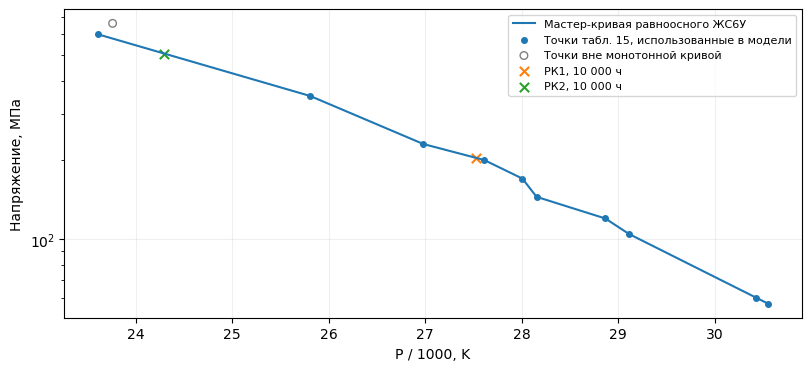

In [75]:
strength = candidate_strength(P0,PROFILES,RADIAL_RESULTS,C,STRENGTH_REQUIREMENTS)
if strength['reasons']:
    print('Замечания расчёта прочности:', ' | '.join(strength['reasons']))

detail_keys = ('geometry_table','chebyshev_table','ordinates_table','section_table','points_table','span')
strength_frames = {key:[] for key in detail_keys}
checks = []
for i in (1,2):
    rotor = strength['rotor_results'].get(i)
    if rotor is None:
        raise Bad(f'РК{i}: прочность не рассчитана')
    for j, section in zip((0,2,4),rotor['sections'],strict=True):
        np.testing.assert_array_equal(section['polygon'],PROFILES[f'РК{i}',j]['polygon'])
    print(f"РК{i}. F(r) = A₀ + A₁r + A₂r², r в метрах, F в м²")
    display(pd.DataFrame([rotor['area_coefficients']],index=[f'РК{i}'],columns=['A₀','A₁','A₂']))
    for key in detail_keys:
        strength_frames[key].append(rotor[key].assign(РК=i))

    span = rotor['span']
    torque = rotor['Z']*np.trapezoid(span.r*span.qy,span.r)
    stage = P0['stages'][i-1]
    euler = stage['G']*stage['Lu']/rotor['omega']
    checks.append({'РК':i,'Момент по нагрузке, Н·м':torque,'Момент по Эйлеру, Н·м':euler,
                   'Отличие момента, %':100*(torque/euler-1),
                   'N на свободном конце, Н':span.N.iloc[-1],
                   'max |M| на свободном конце, Н·м':max(abs(span.Mxi.iloc[-1]),abs(span.Meta.iloc[-1])),
                   'F(r) положительна':bool((span.F>0).all())})

strength_details = {key:pd.concat(tables,ignore_index=True) for key,tables in strength_frames.items()}
strength_checks = pd.DataFrame(checks)
print('Проверка газового момента, свободного конца и закона площади')
display(strength_checks.round(7))

tension_five = mechanical_trapezoid_sections(P0,PROFILES,STRENGTH_REQUIREMENTS['density_kg_m3']).rename(
    columns={'rotor':'РК','section':'Сечение','r':'r, мм','F':'F, мм²','N':'N, Н',
             'sigma_tension':'σN трапеции, МПа'})
tension_five['r, мм'] *= 1e3
tension_five['F, мм²'] *= 1e6
tension_five['σN трапеции, МПа'] *= 1e-6
print('Растяжение по пяти сечениям')
display(tension_five.round(6))
for key,description in (
    ('geometry_table','Площади, центры, моменты инерции и главные оси'),
    ('chebyshev_table','Проверка по схеме Чебышёва'),
    ('ordinates_table','Измеренные хорды для схемы Чебышёва'),
    ('section_table','Нагрузки и напряжения в трёх сечениях'),
    ('points_table','Напряжения в контрольных точках A, B и C'),
):
    frame = strength_details[key]
    print(description)
    with pd.option_context('display.max_columns',None):
        display(frame[['РК',*frame.columns.drop('РК')]].round(5))

method_names = {'trapezoid_5_tension':'5 сечений · трапеции',
                'quadratic_3_tension_gas_bending':'3 сечения · растяжение и изгиб'}
lm_columns = {'rotor':'РК','method':'Метод','section':'Сечение',
              'T_bound_K':'T металла, верхняя оценка, K','P_K':'P, K','allowable_MPa':'σ дл. по LM, МПа',
              'sigma_normal_max_MPa':'σ max, МПа','margin':'Запас','required_margin':'Требуемый запас',
              'rupture_hours':'До разрушения по LM, ч','design_life_hours':'По LM при требуемом запасе, ч',
              'passed':'Критерий модели выполнен'}
print('Исходные данные равноосного ЖС6У для диаграммы Ларсона — Миллера')
display(ZHS6U_RUPTURE_DATA[['T_C','life_h','sigma_MPa','P_1000','used_in_lm']].round(5))
print('Расчёт на 10 000 ч по каждому методу')
lm_view = strength['table'][list(lm_columns)].copy()
published_max_h = ZHS6U_RUPTURE_DATA.life_h.max()
for time_column in ('rupture_hours', 'design_life_hours'):
    strength['table'][time_column + '_beyond_source_time'] = strength['table'][time_column].gt(published_max_h)
    lm_view[time_column] = lm_view[time_column].map(
        lambda hours: f'> {published_max_h:g} (модель)' if hours > published_max_h
        else f'{hours:.2f}' if np.isfinite(hours) else '—'
    )
lm_view = lm_view.replace({'method':method_names}).rename(columns=lm_columns)
with pd.option_context('display.max_columns',None):
    display(lm_view.round(5))

fig,ax = plt.subplots(figsize=(8,3.6),layout='constrained')
p_axis = np.linspace(ZHS6U_LM_POINTS[0,0],ZHS6U_LM_POINTS[-1,0],160)
ax.semilogy(p_axis,lm_sigma(p_axis*1000,ZHS6U_LM_POINTS),label='Мастер-кривая равноосного ЖС6У')
ax.scatter(ZHS6U_LM_POINTS[:,0],ZHS6U_LM_POINTS[:,1],s=16,label='Точки табл. 15, использованные в модели')
unused_points = ZHS6U_RUPTURE_DATA.loc[~ZHS6U_RUPTURE_DATA.used_in_lm]
ax.scatter(unused_points.P_1000,unused_points.sigma_MPa,marker='o',facecolors='none',
           edgecolors='gray',s=30,label='Точки вне монотонной кривой')
for i,g in strength['table'].groupby('rotor'):
    row = g.iloc[0]
    ax.scatter(row['P_K']/1000,row['allowable_MPa'],marker='x',s=45,label=f'РК{i}, 10 000 ч')
ax.set(xlabel='P / 1000, K',ylabel='Напряжение, МПа')
ax.grid(alpha=.2)
ax.legend(fontsize=8)
plt.show()


### 6.1. Ресурс пера и выбор отечественного материала

**Базовый вариант РК1 и РК2 — ЖС6У, равноосное литьё.** Плотность 8400 кг/м³ взята из таблицы ВИАМ. Для номинальной геометрии в обоих методах пересчитана центробежная нагрузка. Газовые силы определяются прежними расходами, давлениями и скоростями. Для ЖС6У доступны опубликованные значения на базе 10 000 ч. Одним сплавом можно покрыть оба венца на стадии предварительного проектирования. Вакуумно-индукционная шихтовая заготовка ЖС6У-ВИ есть в каталоге ВИАМ. Равноосное литьё менее трудоёмко, чем направленная кристаллизация и монокристаллическое литьё. Для сравнения себестоимости серийных отливок нужны цены на одинаковый объём годных деталей с учётом термообработки и контроля. [Кишкин и др., с. 73, табл. 15](https://foundry.kpi.ua/wp-content/uploads/2020/05/kyshkyn-st-lytejn%D1%8Be-zharoprochn%D1%8Be-splav%D1%8B-na-nykelevoj-osnove.pdf), [ВИАМ, свойства сплавов, табл. 1](https://conf.viam.ru/sites/default/files/uploads/proceedings/1059.pdf), [Каталог ВИАМ](https://catalog.viam.ru/catalog/zhs6u/litye-prutkovye-shikhtovye-zagotovki-iz-splava-marki-zhs6u-vi/), [Каблов, с. 187](https://djvu.online/file/LefiZguX6ErSj).

**Две проверки на 10 000 ч.** Основная строка берётся по максимальному растягивающему напряжению среди всех сечений обоих методов. Для неё выводятся предел длительной прочности по Ларсону — Миллеру, запас и обратная оценка времени при рабочем напряжении и при умножении его на запас 1,2. Исходное значение $C=20$ сохранено из прежнего алгоритма. На графике отмечены точки, пропущенные при построении убывающей $\log\sigma(P)$. Выход за диапазон $P$ даёт пустое значение. Отдельная проверка использует ближайшую более горячую точку таблицы с той же базой времени. Это консервативная оценка относительно температурной зависимости средних значений источника при предположении, что длительная прочность снижается с ростом температуры. Для ЖС6У при 900 °C приведено 145 МПа на 10 000 ч. Если этой величины не хватает, по одной такой точке результат при фактической более низкой температуре неизвестен.

**Область применимости.** Точки таблицы 15 — средние значения выбранных плавок, полученные по испытаниям и экстраполяции авторами. Интерполяция по $P$ может соответствовать выходу за диапазон исходных температур или времени. Такие случаи отмечены в сводке, поэтому большие значения обратного расчёта следует читать как прогноз модели. Измерения на реальных отливках нужны для назначения нижней границы материала. Для ресурса установки нужны также температурное поле и ползучесть, термоциклическая и вибрационная усталость, проверки замков и дисков, окисление, а также спектр режимов. На образцах ЖС6У-ВИ из другой турбины опубликовано падение долговечности после наработки. Численный коэффициент из этого исследования в текущую конструкцию не переносится. [Великанова и Великанов, 2023, рис. 7](https://vestnik.kubsu.ru/article/download/1006/1812).

**Кандидат для РК2 — ЖС6К.** Альтернативный равноосный сплав содержит меньше вольфрама и кобальта. При оценке используется его собственная плотность, вклад газового изгиба сохраняется. Экстраполяция на 10 000 ч выполняется степенным законом по двум опубликованным точкам на 100 и 1000 ч при 800 °C. Этой оценки достаточно для сравнения кандидатов и постановки задачи поставщику. Основной расчёт остаётся на ЖС6У до появления сопоставимого подтверждения длительной прочности ЖС6К. [Белов и др., с. 159](https://djvu.online/file/VFveSPQ4Ogpea), [Каблов, с. 50, табл. 2.1](https://djvu.online/file/LefiZguX6ErSj).

**История.** Возвращена ведомость прежнего РК2 из §32.6. Для ХН70ВМТЮ (ЭИ617) сохранены архивное напряжение и температура, 148,23 ч до разрушения и восстановленная оценка времени с запасом 1,2. Кривая 7 перенесена из прежней ручной оцифровки. Погрешность оцифровки оценивалась в ±0,15 по $P/1000$ и ±10% по напряжению. Архив относится к прежней конфигурации, его числа показаны отдельно от расчёта текущего РК2.


In [76]:
life_target = STRENGTH_REQUIREMENTS['life_hours']
required_margin = STRENGTH_REQUIREMENTS['required_margin']
ref_strength = candidate_strength(P0, PROFILES, RADIAL_RESULTS, C, IN738C_REQUIREMENTS)
limit_columns = ['rotor', 'material', 'method', 'section_name', 'T_bound_K',
                 'sigma_normal_max_MPa', 'allowable_MPa', 'margin', 'rupture_hours', 'design_life_hours']
resource_comparison = pd.concat([
    result['table'].loc[result['table'].groupby('rotor')['sigma_normal_max_MPa'].idxmax(), limit_columns]
    for result in (strength, ref_strength)
], ignore_index=True)
resource_comparison['T_bound_C'] = resource_comparison.T_bound_K - 273.15
resource_comparison['stress_required_at_10000h_MPa'] = resource_comparison.sigma_normal_max_MPa * required_margin
resource_comparison['meets_model_margin'] = resource_comparison.margin.ge(required_margin)
material_evidence = pd.DataFrame([
    dict(material=requirements['material'], min_source_T_K=data.T_K.min(), max_source_T_K=data.T_K.max(),
         max_source_time_h=data.life_h.max(), source=requirements['curve_source'], source_url=requirements['source_url'])
    for requirements, data in ((STRENGTH_REQUIREMENTS, ZHS6U_RUPTURE_DATA), (IN738C_REQUIREMENTS, IN738C_RUPTURE_DATA))
])
resource_comparison = resource_comparison.merge(material_evidence, on='material', validate='many_to_one')
resource_comparison['within_source_temperature_range'] = resource_comparison.T_bound_K.between(
    resource_comparison.min_source_T_K, resource_comparison.max_source_T_K
)
resource_comparison['design_life_exceeds_source_time_range'] = (
    resource_comparison.design_life_hours > resource_comparison.max_source_time_h
)

resource_view = resource_comparison.copy()
resource_view['design_life_hours'] = resource_view.apply(
    lambda row: f"> {row.max_source_time_h:g} (модель)" if row.design_life_exceeds_source_time_range
    else f"{row.design_life_hours:.2f}" if np.isfinite(row.design_life_hours) else '—', axis=1
)

print('Определяющее сечение каждого РК по двум методам и сравнение с прежним IN-738C')
with pd.option_context('display.max_columns', None):
    display(resource_view[['rotor', 'material', 'section_name', 'T_bound_C', 'sigma_normal_max_MPa',
        'allowable_MPa', 'margin', 'design_life_hours', 'meets_model_margin',
        'within_source_temperature_range', 'design_life_exceeds_source_time_range']].rename(columns={
        'rotor': 'РК', 'material': 'Сплав', 'section_name': 'Сечение',
        'T_bound_C': 'Верхняя оценка T, °C', 'sigma_normal_max_MPa': 'σmax, МПа',
        'allowable_MPa': 'σ дл. по LM, МПа', 'margin': 'Запас по LM',
        'design_life_hours': 'Время по LM с запасом, ч',
        'meets_model_margin': 'Критерий модели',
        'within_source_temperature_range': 'T в диапазоне таблицы',
        'design_life_exceeds_source_time_range': 'Время за базой таблицы',
    }).round(3))

zhs6u_limits = resource_comparison.loc[resource_comparison.material.eq(STRENGTH_REQUIREMENTS['material'])]
hotter_rows = []
for row in zhs6u_limits.itertuples(index=False):
    data = ZHS6U_RUPTURE_DATA
    matching = data.loc[data.life_h.eq(life_target) & data.T_K.ge(row.T_bound_K)].sort_values('T_K')
    point = matching.iloc[0] if not matching.empty else None
    sigma_life = float(point.sigma_MPa) if point is not None else np.nan
    hotter_margin = sigma_life / row.sigma_normal_max_MPa
    hotter_rows.append(dict(
        rotor=row.rotor, material=row.material, T_bound_C=row.T_bound_C, life_h=life_target,
        sigma_normal_max_MPa=row.sigma_normal_max_MPa, required_MPa=row.stress_required_at_10000h_MPa,
        source_temperature_C=float(point.T_C) if point is not None else np.nan,
        source_sigma_MPa=sigma_life, source_margin=hotter_margin, source=ZHS6U_SOURCE, source_url=ZHS6U_URL,
        status=('нет табличной точки' if point is None else
                'ориентир выполнен' if hotter_margin >= required_margin else 'оценка снизу недостаточна'),
    ))
resource_hotter_table = pd.DataFrame(hotter_rows)
print('Контроль без LM по опубликованной точке 10 000 ч при более высокой температуре')
display(resource_hotter_table.drop(columns=['source', 'source_url']).rename(columns={
    'rotor': 'РК', 'material': 'Сплав', 'T_bound_C': 'Оценка T, °C', 'life_h': 'База, ч',
    'sigma_normal_max_MPa': 'σmax, МПа', 'required_MPa': 'Требуется, МПа',
    'source_temperature_C': 'T табл., °C', 'source_sigma_MPa': 'σ табл., МПа',
    'source_margin': 'Табличный запас', 'status': 'Результат',
}).round(3))

# Проверяем, насколько выбор C в принятой мастер-кривой влияет на запас на 10 000 ч.
sensitivity = []
for lm_c in (15., STRENGTH_REQUIREMENTS['C_LM'], 25.):
    _, points = zhs6u_lm_points(ZHS6U_RUPTURE_DATA, lm_c)
    for row in zhs6u_limits.itertuples(index=False):
        parameter = row.T_bound_K * (lm_c + np.log10(life_target))
        sigma_life = float(lm_sigma(parameter, points))
        sensitivity.append(dict(rotor=row.rotor, C_LM=lm_c, P_K=parameter,
                                model_sigma_MPa=sigma_life, model_margin=sigma_life/row.sigma_normal_max_MPa))
resource_lm_sensitivity = pd.DataFrame(sensitivity)
print('Чувствительность ЖС6У к выбору C Ларсона — Миллера')
display(resource_lm_sensitivity.round(3))

# РК2 при смене материала: газовый изгиб в этой модели не зависит от плотности.
# Пересчитываем линейный по плотности вклад растяжения в каждом из двух методов.
rotor2 = strength['table'].loc[lambda d: d.rotor.eq(2)]
rho_ratio = ZHS6K_DENSITY / STRENGTH_REQUIREMENTS['density_kg_m3']
sigma_zhs6k = rotor2.sigma_normal_max_MPa + (rho_ratio - 1) * rotor2.sigma_tension_MPa
zhs6k_limit = rotor2.loc[sigma_zhs6k.idxmax()]
zhs6k_sigma = float(sigma_zhs6k.max())
zhs6k_t = zhs6k_limit.T_bound_K - 273.15
zhs6k_reference_t = ZHS6K_RUPTURE_DATA.T_C.iat[0]
log_h = np.log10(ZHS6K_RUPTURE_DATA.life_h.to_numpy())
log_sigma = np.log10(ZHS6K_RUPTURE_DATA.sigma_MPa.to_numpy())
slope = (log_sigma[1] - log_sigma[0]) / (log_h[1] - log_h[0])
zhs6k_screen = 10.**(log_sigma[0] + slope * (np.log10(life_target) - log_h[0]))
if zhs6k_t > zhs6k_reference_t:
    zhs6k_screen = np.nan
resource_zhs6k = pd.DataFrame([dict(
    rotor=2, material='ЖС6К, равноосное литьё', density_kg_m3=ZHS6K_DENSITY,
    T_bound_C=zhs6k_t, extrapolation_T_C=zhs6k_reference_t, life_h=life_target,
    sigma_normal_max_MPa=zhs6k_sigma, extrapolated_sigma_MPa=zhs6k_screen,
    extrapolated_margin=zhs6k_screen/zhs6k_sigma,
    source=ZHS6K_SOURCE, source_url=ZHS6K_URL,
    status='Оценка по двум точкам. Подтверждение на 10 000 ч требуется.',
)])
print('Кандидат ЖС6К для РК2: экстраполяция по двум точкам при 800 °C')
display(resource_zhs6k.drop(columns=['source', 'source_url']).rename(columns={
    'rotor': 'РК', 'material': 'Сплав', 'density_kg_m3': 'Плотность, кг/м³',
    'T_bound_C': 'Оценка T, °C', 'extrapolation_T_C': 'T исходных точек, °C', 'life_h': 'База, ч',
    'sigma_normal_max_MPa': 'σmax, МПа', 'extrapolated_sigma_MPa': 'σ дл. экстр., МПа',
    'extrapolated_margin': 'Оценка запаса', 'status': 'Результат',
}).round(3))

# В прежнем файле точки графика округлены. Сохраняем и архивное, и воспроизведённое значение.
t = LEGACY_ROTOR2['T_bound_K']
s = LEGACY_ROTOR2['sigma_normal_max_MPa']
legacy_c = LEGACY_ROTOR2['C_LM']
legacy_sigma = float(lm_sigma(t * (legacy_c + np.log10(life_target)), LEGACY_LM_POINTS))
resource_historical = pd.DataFrame([dict(
    **LEGACY_ROTOR2, life_h=life_target, required_margin=required_margin,
    recomputed_rupture_hours=10.**(float(lm_parameter(s, LEGACY_LM_POINTS)) / t - legacy_c),
    design_life_hours=10.**(float(lm_parameter(required_margin*s, LEGACY_LM_POINTS)) / t - legacy_c),
    sigma_at_target_MPa=legacy_sigma, margin_at_target=legacy_sigma/s,
)])
print('Архивный РК2 на прежней геометрии, восстановление расчёта по кривой 7')
display(resource_historical.drop(columns=['source']).rename(columns={
    'rotor': 'РК', 'material': 'Сплав', 'T_bound_K': 'Оценка T, K', 'sigma_normal_max_MPa': 'σmax, МПа',
    'archived_rupture_hours': 'До разрушения в архиве, ч', 'C_LM': 'C', 'life_h': 'База, ч',
    'required_margin': 'Требуемый запас', 'recomputed_rupture_hours': 'До разрушения, пересчёт, ч',
    'design_life_hours': 'С требуемым запасом, ч', 'sigma_at_target_MPa': 'σ дл. по LM, МПа',
    'margin_at_target': 'Запас на заданной базе',
}).round(4))


Определяющее сечение каждого РК по двум методам и сравнение с прежним IN-738C


,РК,Сплав,Сечение,"Верхняя оценка T, °C","σmax, МПа","σ дл. по LM, МПа",Запас по LM,"Время по LM с запасом, ч",Критерий модели,T в диапазоне таблицы,Время за базой таблицы
0,1,"ЖС6У, равноосное литьё",Корневое,873.991,116.783,203.663,1.744,> 10000 (модель),True,True,True
1,2,"ЖС6У, равноосное литьё",Корневое,739.278,173.684,506.810,2.918,> 10000 (модель),True,False,True
2,1,"IN-738C, вакуумное литьё",Корневое,873.991,112.796,141.178,1.252,> 1000 (модель),True,True,True
3,2,"IN-738C, вакуумное литьё",Корневое,739.278,167.807,411.164,2.450,> 1000 (модель),True,True,True


Контроль без LM по опубликованной точке 10 000 ч при более высокой температуре


,РК,Сплав,"Оценка T, °C","База, ч","σmax, МПа","Требуется, МПа","T табл., °C","σ табл., МПа",Табличный запас,Результат
0,1,"ЖС6У, равноосное литьё",873.991,10000.0,116.783,140.14,900.0,145.0,1.242,ориентир выполнен
1,2,"ЖС6У, равноосное литьё",739.278,10000.0,173.684,208.42,900.0,145.0,0.835,оценка снизу недостаточна


Чувствительность ЖС6У к выбору C Ларсона — Миллера


,rotor,C_LM,P_K,model_sigma_MPa,model_margin
0,1,15.0,21795.674,163.753,1.402
1,2,15.0,19236.123,438.004,2.522
2,1,20.0,27531.377,203.663,1.744
3,2,20.0,24298.261,506.810,2.918
4,1,25.0,33267.081,217.421,1.862
5,2,25.0,29360.399,555.575,3.199


Кандидат ЖС6К для РК2: экстраполяция по двум точкам при 800 °C


,РК,Сплав,"Плотность, кг/м³","Оценка T, °C","T исходных точек, °C","База, ч","σmax, МПа","σ дл. экстр., МПа",Оценка запаса,Результат
0,2,"ЖС6К, равноосное литьё",8160.0,739.278,800.0,10000.0,168.82,277.692,1.645,Оценка по двум точкам. Подтверждение на 10 000...


Архивный РК2 на прежней геометрии, восстановление расчёта по кривой 7


,Сплав,РК,"Оценка T, K","σmax, МПа","До разрушения в архиве, ч",C,"База, ч",Требуемый запас,"До разрушения, пересчёт, ч","С требуемым запасом, ч","σ дл. по LM, МПа",Запас на заданной базе
0,ХН70ВМТЮ (ЭИ617),2,1026.0158,358.8531,148.2267,20.0,10000.0,1.2,148.2267,33.0496,184.8542,0.5151


### 6.1. Оси сечений и эпюры обоих РК

A — входная кромка, B — выходная, C — точка максимального удаления контура от хорды. Эпюры показывают распределение по направлению градиента изгибных напряжений. У свободного конца центробежная сила и изгибающий момент обращаются в нуль.


In [77]:
from matplotlib.patches import Arc, Polygon

_UKR_TEAL = "#008f91"
_UKR_BLUE = "#259fc1"

def _ukr_angle_arc(ax, angle, radius, label, color='0.25'):
    """Размерная дуга от положительного направления ξ к заданному углу."""
    angle = (float(angle) + np.pi) % (2 * np.pi) - np.pi
    if abs(angle) < 1e-10:
        ax.annotate(label, (radius, 0), xytext=(4, 6),
                    textcoords='offset points', fontsize=8, color=color)
        return
    degrees = np.degrees(angle)
    ax.add_patch(Arc((0, 0), 2 * radius, 2 * radius,
                     theta1=min(0, degrees), theta2=max(0, degrees), color=color, lw=.8))
    end = radius * np.array([np.cos(angle), np.sin(angle)])
    before = radius * np.array([np.cos(angle * .94), np.sin(angle * .94)])
    ax.annotate('', end, before, arrowprops=dict(arrowstyle='->', color=color, lw=.8))
    mid = 1.14 * radius * np.array([np.cos(angle / 2), np.sin(angle / 2)])
    ax.text(*mid, label, fontsize=8, color=color, ha='center', va='center',
            bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1))


def _ukr_section(ax, section, neutral=False):
    p = np.asarray(section['centered'], dtype=float) * 1e3
    axes = np.asarray(section['principal_axes'], dtype=float)
    length = max(float(np.max(np.linalg.norm(p, axis=1))), np.finfo(float).eps)
    ax.add_patch(Polygon(p, closed=True, facecolor='#e6f5f3', edgecolor=_UKR_TEAL,
                         lw=1.7, hatch='///', zorder=2))
    for direction, label, color in [(np.array([1., 0.]), 'ξ', _UKR_BLUE),
                                     (np.array([0., 1.]), 'η', _UKR_BLUE),
                                     (axes[:, 0], 'u', '0.4'),
                                     (axes[:, 1], 'v', '0.4')]:
        ax.plot(*np.array([-1.17 * length * direction, 1.17 * length * direction]).T,
                color=color, lw=.7, zorder=1)
        end = 1.17 * length * direction
        ax.annotate(label, end, xytext=(3, 3), textcoords='offset points',
                    color=color, fontsize=9)
    ax.scatter([0], [0], c='black', s=14, zorder=4)
    ax.annotate('O', (0, 0), xytext=(4, -12), textcoords='offset points', fontsize=8)
    for label, index in section['points'].items():
        point = p[int(index)]
        ax.scatter(*point, s=13, color=_UKR_TEAL, zorder=4)
        ax.annotate(label, point, xytext=(4, 5), textcoords='offset points', fontsize=8)
    angle = float(section['principal_angle_rad'])
    _ukr_angle_arc(ax, angle, .56 * length, f'φ = {np.degrees(angle):.2f}°')
    if neutral:
        gradient = np.asarray(section['stress_gradient'], dtype=float)
        norm = float(np.linalg.norm(gradient))
        if norm > 0:
            normal = gradient / norm
            tangent = np.array([-normal[1], normal[0]])
            ends = np.array([-1.3 * length * tangent, 1.3 * length * tangent])
            ax.plot(*ends.T, '--', color='#a44a00', lw=1, label='σизг = 0')
            shift = -float(section['sigma_tension']) / norm * 1e3 * normal
            # Нулевая линия суммарных напряжений может лежать вне сечения.
            if np.linalg.norm(shift) <= 1.3 * length:
                ax.plot(*(ends + shift).T, ':', color='#942c7d', lw=1.2,
                        label='σΣ = 0')
            else:
                ax.text(.02, .02, 'σΣ = 0 вне поля чертежа', transform=ax.transAxes,
                        fontsize=7, color='#942c7d')
            beta = section.get('neutral_angle_rad')
            if beta is not None:
                _ukr_angle_arc(ax, beta, .85 * length,
                               f'θн = {np.degrees(beta):.2f}°', '#a44a00')
            ax.legend(loc='upper left', fontsize=7, framealpha=.85)
        else:
            ax.text(.02, .02, 'Изгиб отсутствует; нейтральная линия не определена',
                    transform=ax.transAxes, fontsize=7, wrap=True)
    ax.set(xlim=(-1.42 * length, 1.42 * length), ylim=(-1.42 * length, 1.42 * length),
           xlabel='ξ − ξO, мм', ylabel='η − ηO, мм',
           title=f"{section['name']} сечение\nr = {section['r']:.4f} м")
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(labelsize=8)
    ax.grid(alpha=.15)


def _ukr_epure(ax, distance, stress, title, point_distances, point_values):
    # Расстояния на ординате — мм, напряжения на абсциссе — МПа.
    y = np.asarray(distance, dtype=float) * 1e3
    x = np.asarray(stress, dtype=float) * 1e-6
    ax.fill_betweenx(y, 0, x, facecolor='#e6f5f3', edgecolor=_UKR_TEAL,
                     hatch='---', linewidth=.8)
    ax.plot(x, y, color=_UKR_TEAL, lw=1.5)
    ax.axvline(0, color='0.3', lw=.8)
    ax.axhline(0, color='0.55', lw=.6)
    for label, distance_value in (point_distances.items() if np.any(x) else ()):
        value = float(point_values[label]) * 1e-6
        ordinate = float(distance_value) * 1e3
        ax.scatter([value], [ordinate], s=13, color=_UKR_TEAL, zorder=4)
        ax.annotate(f'{label}: {value:.3f}', (value, ordinate), xytext=(4, 4),
                    textcoords='offset points', fontsize=7)
    low, high = float(np.min(x)), float(np.max(x))
    width = max(abs(low), abs(high), high - low)
    if width == 0:
        ax.set_xlim(-1, 1)
        ax.text(.98, .98, 'A = B = C = 0 МПа', transform=ax.transAxes,
                ha='right', va='top', fontsize=9)
    else:
        ax.set_xlim(min(0., low) - .22 * width, max(0., high) + .55 * width)
        ax.text(.02, .98, f'min {low:.3f}\nmax {high:.3f} МПа',
                transform=ax.transAxes, va='top', fontsize=8)
    height = float(np.ptp(y))
    ax.set_ylim(float(np.min(y)) - .12 * height, float(np.max(y)) + .15 * height)
    ax.set(title=title, xlabel='σ, МПа', ylabel='s, мм')
    ax.tick_params(labelsize=8)
    ax.grid(alpha=.18)


def plot_ukr_stress_epures(result):
    """Эпюры по направлению градиента: растяжение, изгиб и их сумма."""
    fig, axes = plt.subplots(3, 4, figsize=(15, 11), constrained_layout=True)
    for row, section in zip(axes, result['sections']):
        _ukr_section(row[0], section, neutral=True)
        p = np.asarray(section['centered'], dtype=float)
        gradient = np.asarray(section['stress_gradient'], dtype=float)
        norm = float(np.linalg.norm(gradient))
        # При нулевом изгибе используем v только как координату развертки;
        # никакой фиктивный наклон эпюры или нейтральной линии не вводится.
        direction = gradient / norm if norm > 0 else np.asarray(section['principal_axes'])[:, 1]
        distance = p @ direction
        ends = np.array([np.min(distance), np.max(distance)])
        tension = float(section['sigma_tension'])
        indices = section['points']
        point_distances = {key: distance[int(index)] for key, index in indices.items()}
        bending_vertices = np.asarray(section['sigma_bending']).reshape(-1)
        total_vertices = np.asarray(section['sigma_total']).reshape(-1)
        for ax, stress, title, values in [
            (row[1], np.full(2, tension), 'Растяжение σN = N/F',
             {key: tension for key in indices}),
            (row[2], norm * ends, 'Изгиб σизг',
             {key: bending_vertices[int(index)] for key, index in indices.items()}),
            (row[3], tension + norm * ends, 'Суммарное σΣ = σN + σизг',
             {key: total_vertices[int(index)] for key, index in indices.items()})]:
            _ukr_epure(ax, ends, stress, title, point_distances, values)
        if norm == 0:
            row[2].text(.5, .72, 'Градиент напряжений равен нулю',
                        transform=row[2].transAxes, ha='center', fontsize=8)
    fig.suptitle(f"РК{result['rotor']} — эпюры нормальных напряжений\n"
                 's — расстояние от центра масс вдоль ∇σ; при ∇σ = 0 — вдоль v')
    return [fig]


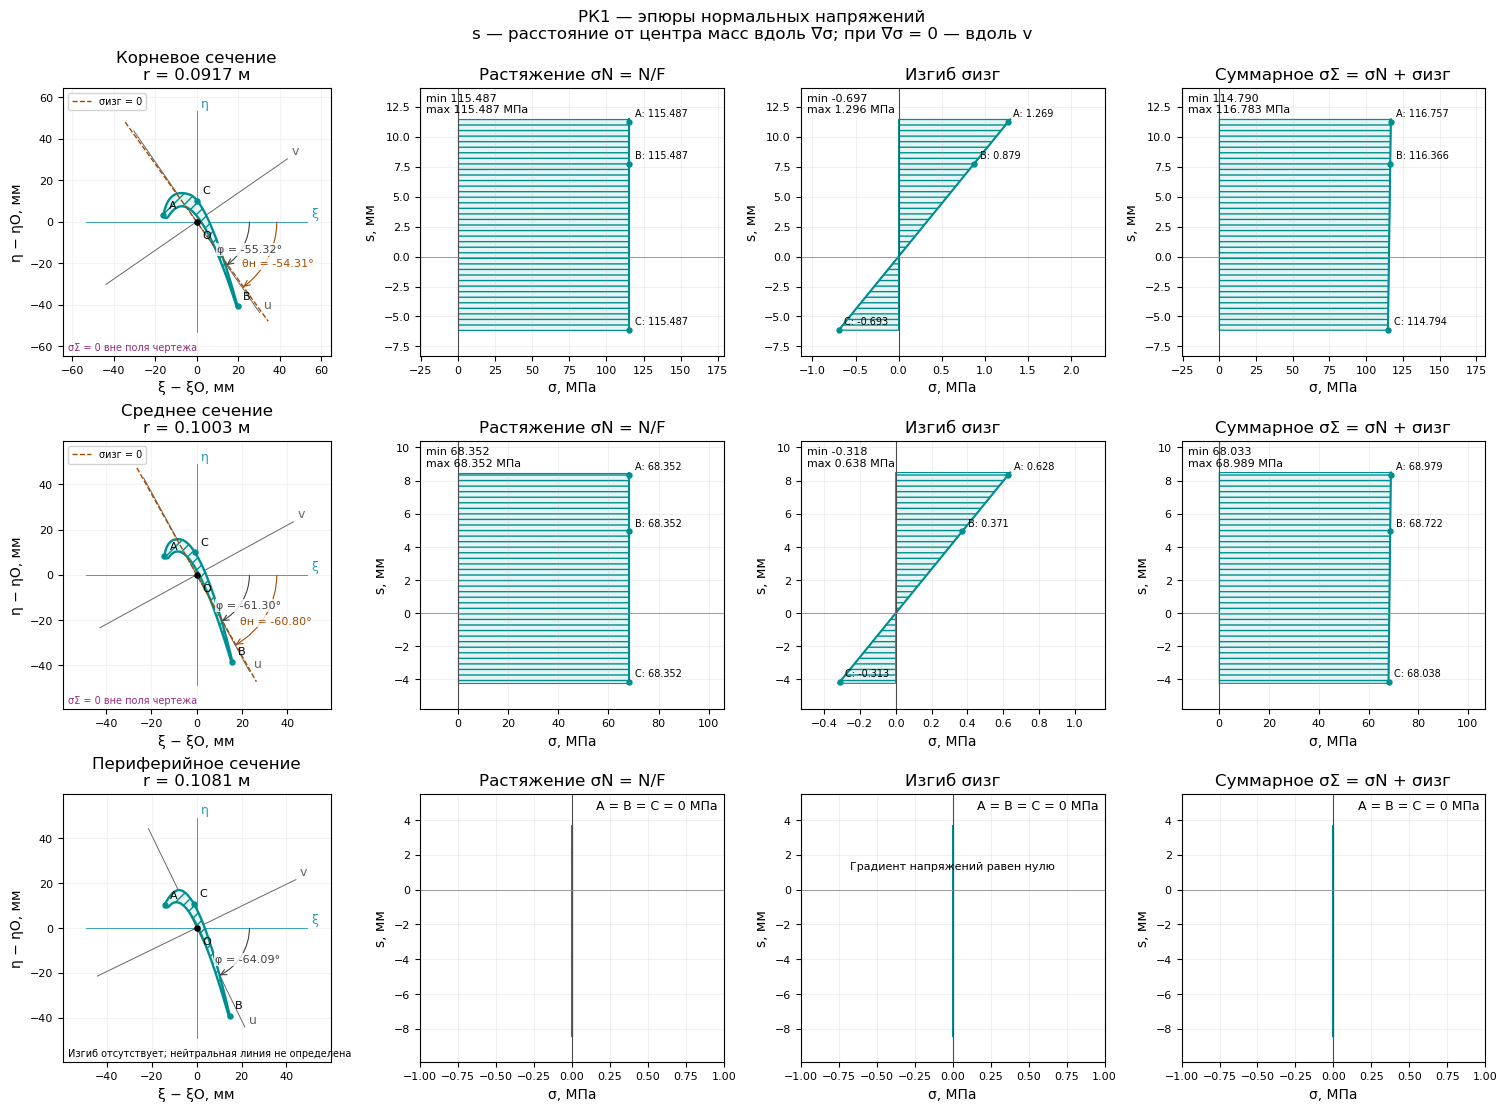

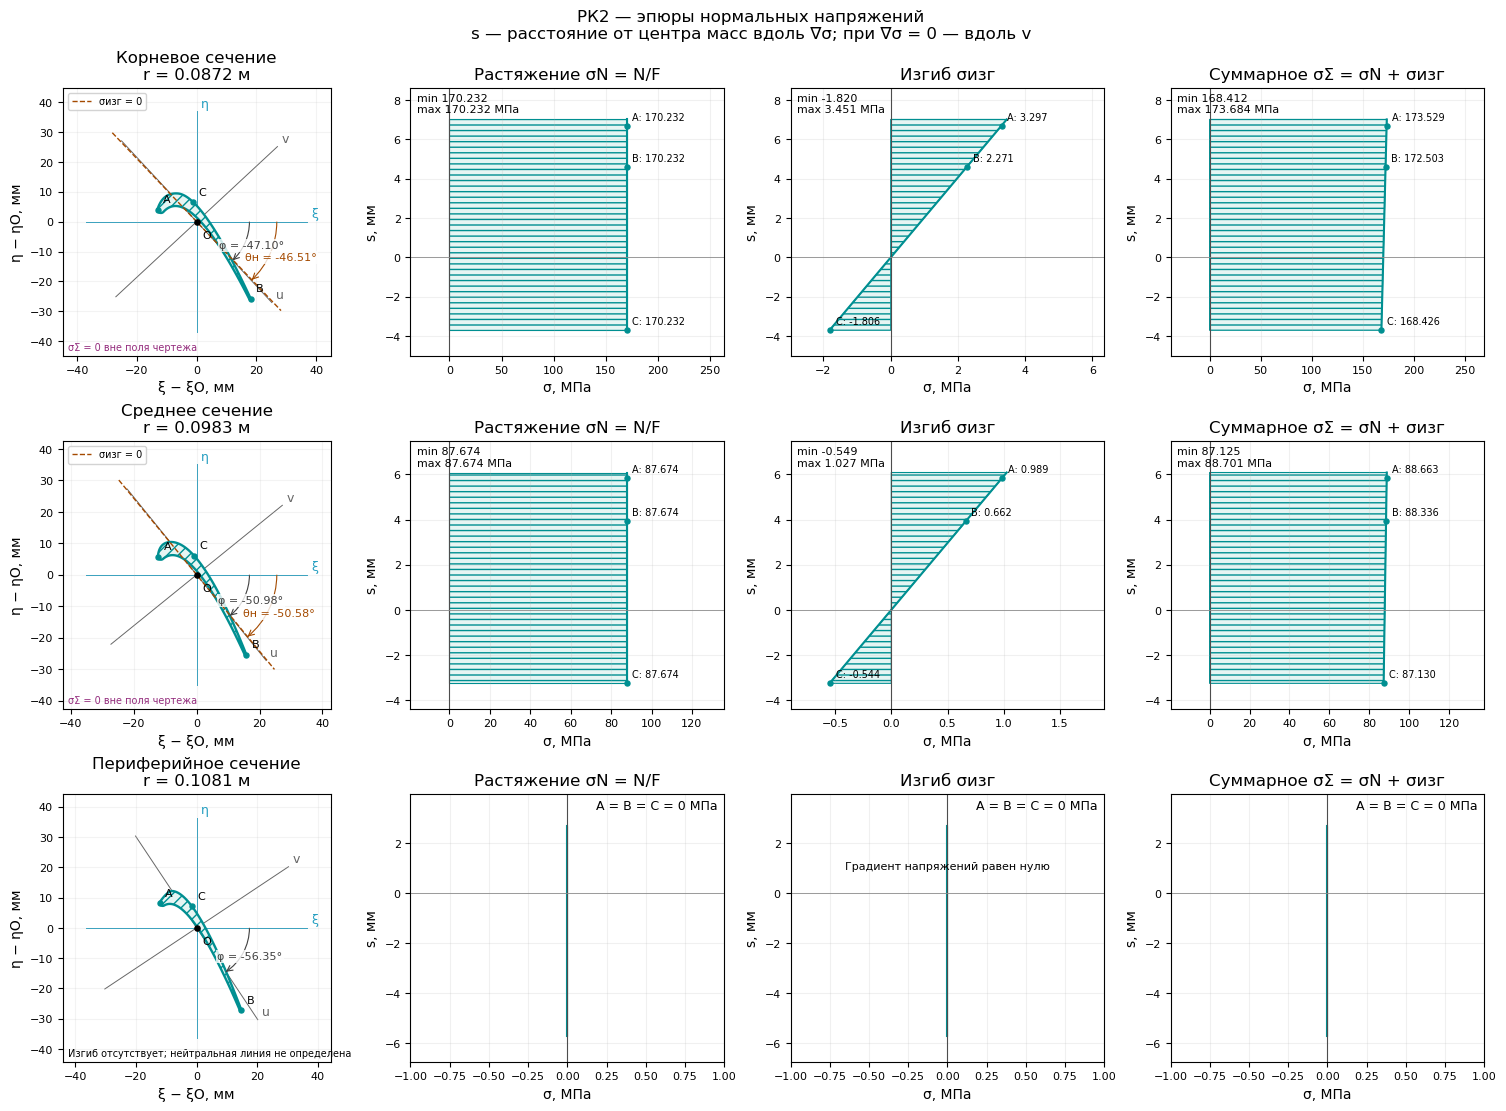

In [78]:
for rotor in strength['rotor_results'].values():
    plot_ukr_stress_epures(rotor)
plt.show()


## 7. Чертёж и экспорт

Файлы записываются в export/fixed. Лист А1 второй ступени содержит три сечения СА2 и РК2, каналы и треугольники скоростей с общим полюсом. Поток направлен сверху вниз, вид РК зеркальный. Отдельный DXF треугольников выполнен в масштабе 1 мм = 1 м/с. Файлы контуров и точек для сплайнов содержат локальные координаты сечений. Таблицы и эскиз меридиональной геометрии используют этот же расчёт.
Подробные расчётные ведомости также записываются в CSV для проверки и переноса в пояснительную записку.
Сводка ресурса пера записывается в `resource_material_comparison.csv`. Отдельными файлами выгружаются сравнение с более горячей точкой таблицы, чувствительность к $C$, альтернативный ЖС6К для РК2 и архивный расчёт.

Спинка, корытце и средняя линия записываются отдельными сплайнами на слоях SUCTION, PRESSURE и CAMBER. Точки разделения лежат на дугах кромок, где касательная к контуру перпендикулярна местному расчётному направлению потока: абсолютному для СА и относительному для РК. Касательные к средней линии на концах совпадают с направлениями потока. В теле профиля сплайн проходит через равноудалённые от сторон точки. Вблизи кромок сплайн плавно соединяет эти точки с заданными касательными. Файлы `*_suction.txt`, `*_pressure.txt` и `*_camber.txt` содержат точки от натекания до стока в локальных координатах, в миллиметрах.

Для КОМПАС‑3D файлы второй ступени также записываются в `export/fixed/Точки профилей`. В папках `РК` и `СА` есть по три сечения: `Втулка`, `Среднее`, `Периферия`. В каждом сечении импортируйте по одному файлу для средней линии, спинки и корытца. В модели откройте «Пространственный сплайн», выберите построение по точкам и нажмите «Читать из файла» над таблицей точек. Для каждой линии создайте новый сплайн. TXT содержит по одной строке `X Y Z` на точку, с пробелами и десятичной точкой. Координаты даны в миллиметрах от натекания к стоку. Каждый профиль расположен в своей локальной плоскости XY при `Z = 0`, ось X направлена по потоку. Для построения трёхмерной лопатки разместите сечения в модели на нужных радиусах. [Справка КОМПАС‑3D](https://help.ascon.ru/KOMPAS/25/ru-RU/bk1216038.html).

Хорда на листе А1 соединяет точки натекания и стока. Подписи `b` и `δ` обозначают длину этого отрезка и его угол к окружному направлению. Осевая ширина `bₐ` измеряется между осевыми экстремумами контура. В расчётных ведомостях длина хорды отсчитывается по принятым там геометрическим базам профиля.

**Проточная часть для КОМПАС‑3D.** Папка `export/fixed/Проточная часть` содержит четыре направляющие от входа СА1 до среза сопла. В подпапке `Кромки` лежат передняя и задняя кромки каждого венца СА1, РК1, СА2 и РК2, по пяти расчётным сечениям. Осевая координата кромки взята из точки натекания или стока профиля. Радиус перенесён на соответствующую осевую координату с сохранением доли площади кольца. Средняя направляющая проходит через среднее расчётное сечение каждой кромки. Между кромками доля площади кольца интерполируется по оси.

В `meridional_2d.dxf` все 12 линий записаны как разомкнутые двумерные ломаные на отдельных слоях. Масштаб 1:1, координаты в миллиметрах. В КОМПАС‑3D откройте DXF в графическом документе. TXT содержит по две координаты `X Y` на вершину. Здесь `X` — координата вдоль оси, `Y` — радиус. Для переноса готовых ломаных используйте DXF. [Справка КОМПАС‑3D](https://help.ascon.ru/KOMPAS/25/ru-RU/bm1510125.html).


In [79]:
CAD_SECTIONS = ((0,'root','Корень'),(2,'middle','Среднее сечение'),(4,'tip','Периферия'))
CAD_VENETS = (('СА2','SA2'),('РК2','RK2'))
CAD_VECTORS = ((0,1,'U','#365f68'),(1,2,'W','#b06932'),(0,2,'C','#234d7c'))


def stage2_velocity_triangles(result, radial_sections):
    """Вершины O, A, B. Окружная ось по вращению, осевая положительна по потоку."""
    omega = result['geometry'][0]*np.pi/30
    triangles = {}
    for j,key,_ in CAD_SECTIONS:
        section = radial_sections.iloc[j]
        for prefix,station,sign in (('in','inlet',1.),('out','outlet',-1.)):
            c = np.array([sign*section[f'{prefix}_cu'],section[f'{prefix}_ca']])
            u = np.array([omega*section[f'{prefix}_r'],0.])
            np.testing.assert_allclose([np.linalg.norm(c),np.linalg.norm(c-u)],
                [section[f'{prefix}_c'],section[f'{prefix}_w']],rtol=5e-5,atol=.003)
            # Числа в м/с становятся миллиметрами без изменения величин.
            triangles[key,station] = np.vstack((np.zeros(2),u,c))
    return triangles


def stage2_circles(profile):
    centers = profile['inscribed_circle_centers']*1000
    diameters = profile['local_width']*1000
    reduced = profile['reduced_width']*1000
    if not (profile['geometry_valid'] and len(centers)==len(diameters)==len(reduced)>1):
        raise ValueError('Для вывода окружностей нужен проверенный канал')
    distance = np.r_[0.,np.cumsum(np.linalg.norm(np.diff(centers,axis=0),axis=1))]
    sample = np.unique(np.searchsorted(distance,np.linspace(0.,distance[-1],8)))
    return centers,diameters,reduced,distance,sample


def blade_sheet_coordinates(points, row):
    """Локальные осевая и окружная координаты в осях вида на листе."""
    axial, tangential = np.moveaxis(np.asarray(points), -1, 0)
    handedness = -1 if row.startswith("РК") else 1
    return np.stack((handedness * tangential, -axial), axis=-1)

def common_velocity_vertices(raw):
    """O, концы C и W в координатах чертежа при 1 мм = 1 м/с."""
    o, u_end, c_end = np.asarray(raw)
    c, u = c_end - o, u_end - o
    return np.vstack((np.zeros(2), -c, -(c-u)))


PROFILE_SIDE_LAYERS = {'suction': 'SUCTION', 'pressure': 'PRESSURE'}


def profile_flow_edges(profile):
    """Радиусы и центры кромок, направления потока и точки разделения в мм."""
    r_le, r_te = 1000 * np.array([profile['rLE'], profile['rTE']])
    nose, tail = 1000 * profile['suction'][[0, -1]]
    c_le, c_te = nose + [r_le, 0], tail - [r_te, 0]
    # На входе угол отсчитан от +y, на выходе от −y.
    theta = np.deg2rad([90 - profile['beta_in_flow'], profile['beta_out_actual_flow'] - 90])
    directions = np.column_stack((np.cos(theta), np.sin(theta)))
    split = np.stack((c_le - r_le * directions[0], c_te + r_te * directions[1]))
    return split, directions, theta, c_le, c_te, r_le, r_te


def flow_split_profile(profile):
    """Точные дуги кромок и параболы, от точки натекания до точки стока, в мм."""
    from scipy.interpolate import BSpline

    split, directions, theta, c_le, c_te, r_le, r_te = profile_flow_edges(profile)

    def angle(point, center):
        return np.arctan2(*(point - center)[::-1])

    def arc(center, radius, start, end):
        # Разбивка дуг на участки не длиннее 90°, положительные веса NURBS.
        angles = np.linspace(start, end, max(1, int(np.ceil(abs(end - start) / (np.pi / 2)))) + 1)
        for first, last in zip(angles[:-1], angles[1:], strict=True):
            t = np.array([first, (first + last) / 2, last])
            weights = np.array([1., np.cos((last - first) / 2), 1.])
            vertices = center + radius * np.column_stack((np.cos(t), np.sin(t))) / weights[:, None]
            yield vertices, weights

    front, rear = profile['controls']
    walls = {}
    for side, body in (('suction', (front, rear)), ('pressure', (profile['pressure_control'],))):
        body = [1000 * piece for piece in body]
        le_join = angle(body[0][0], c_le) % (2 * np.pi)
        te_join = angle(body[-1][-1], c_te)
        le_angle, te_angle = np.pi + theta[0], theta[1]
        between = ((le_join <= le_angle and te_join >= te_angle) if side == 'suction'
                   else (le_join >= le_angle and te_join <= te_angle))
        if not between:
            raise ValueError('Точка по вектору потока находится за пределами дуги кромки')

        pieces = [*arc(c_le, r_le, le_angle, le_join),
                  *((piece, np.ones(3)) for piece in body),
                  *arc(c_te, r_te, te_join, te_angle)]
        for first, second in zip(pieces[:-1], pieces[1:], strict=True):
            np.testing.assert_allclose(first[0][-1], second[0][0], rtol=0, atol=1e-8)
        controls = np.vstack([pieces[0][0][0], *(points[1:] for points, _ in pieces)])
        controls[[0, -1]] = split
        weights = np.concatenate(([1.], *(w[1:] for _, w in pieces)))
        knots = np.r_[np.zeros(3), np.repeat(np.arange(1, len(pieces)), 2), np.full(3, len(pieces))]
        homogeneous = np.column_stack((controls * weights[:, None], weights))
        curve = BSpline(knots, homogeneous, 2)
        values = curve(np.linspace(0, len(pieces), 32 * len(pieces) + 1))
        walls[side] = dict(controls=controls, weights=weights, knots=knots,
                           points=values[:, :2] / values[:, 2:])
    return walls, split, directions


def profile_mean_line(profile, split, directions):
    """Кубический сплайн с касательными по потоку на входе и выходе."""
    from scipy.interpolate import make_interp_spline

    sp, pr = (1000 * profile[side] for side in ('suction', 'pressure'))
    # В округлениях продолжаем среднюю линию по касательной потока.
    # В теле профиля берём точки равного расстояния до обеих поверхностей.
    length = split[1, 0] - split[0, 0]
    x_start = max(1000 * profile['rLE'] * 1.8, length * .05)
    x_end = max(1000 * profile['rTE'] * 2.5, length * .04)
    body_x = np.linspace(split[0, 0] + x_start, split[1, 0] - x_end, 65)

    def mid_y(x):
        lower, upper = sorted(np.interp(x, side[:, 0], side[:, 1]) for side in (sp, pr))

        def distance_difference(y):
            point = np.array([x, y])
            return _book_point_distance(point, sp)[0] - _book_point_distance(point, pr)[0]

        return brentq(distance_difference, lower, upper, xtol=1e-10)

    nodes = np.vstack((split[0], np.column_stack((body_x, [mid_y(x) for x in body_x])), split[1]))
    parameters = (nodes[:, 0] - split[0, 0]) / length
    tangents = length * directions / directions[:, :1]
    curve = make_interp_spline(parameters, nodes, k=3,
                               bc_type=([(1, tangents[0])], [(1, tangents[1])]))
    sample = (1 - np.cos(np.linspace(0, np.pi, 193))) / 2
    return curve(sample), curve


def add_profile_layers(doc):
    doc.linetypes.new('CAMBER_DASH', dxfattribs={'description': 'Blade mean camber line',
                                               'pattern': [4.4, 3.2, -1.2]})
    doc.layers.new('CAMBER', dxfattribs={'color': 6, 'linetype': 'CAMBER_DASH', 'lineweight': 18})
    for layer in PROFILE_SIDE_LAYERS.values():
        doc.layers.new(layer, dxfattribs={'color': 7, 'lineweight': 50})
        doc.layers.new('NEIGHBOR_' + layer, dxfattribs={'color': 8, 'lineweight': 35})


def draw_blade_splines(msp, walls, camber, transform, neighbor=False):
    for side, layer in PROFILE_SIDE_LAYERS.items():
        wall = walls[side]
        msp.add_rational_spline(transform(wall['controls']), wall['weights'], degree=2,
                                knots=wall['knots'],
                                dxfattribs={'layer': 'NEIGHBOR_' + layer if neighbor else layer})
    msp.add_open_spline(transform(camber.c), degree=camber.k, knots=camber.t,
                       dxfattribs={'layer': 'CAMBER'})


def export_meridional_polylines(folder, channel, profiles):
    """Двумерные меридиональные ломаные DXF и координаты их вершин XY."""
    import ezdxf

    target = Path(folder) / 'Проточная часть'
    target.mkdir(parents=True, exist_ok=True)
    doc = ezdxf.new('R2010', units=ezdxf.units.MM)
    doc.header['$MEASUREMENT'] = 1
    msp = doc.modelspace()
    contour = channel['contour'].drop_duplicates('x')
    x_wall, r_hub, r_tip = (contour[['x', 'rhub', 'rtip']].to_numpy() * 1000).T
    x_station = channel['stations']['x'].to_numpy() * 1000

    def walls(x):
        return np.interp(x, x_wall, r_hub), np.interp(x, x_wall, r_tip)

    def radius(x, fraction):
        hub, tip = walls(x)
        return np.sqrt(hub**2 + fraction * (tip**2 - hub**2))

    def write_polyline(path, x, r, layer, color):
        points = np.round(np.column_stack((x, r)), 9)
        np.savetxt(path, points, fmt='%.9f')
        doc.layers.new(layer, dxfattribs={'color': color})
        msp.add_lwpolyline(points, format='xy', close=False, dxfattribs={'layer': layer})

    edge_x_all, middle_x, middle_fraction = [], [], []
    for row in channel['blade_rows'].itertuples(index=False):
        edges, fractions = [], []
        for j in range(5):
            profile = profiles[row.name, j]
            split, *_ = profile_flow_edges(profile)
            axial = profile['x_le_m'] * 1000 + split[:, 0]
            edges.append(axial)
            # Сохраняем место расчётного сечения в площади кольца.
            hub, tip = walls(profile['x_te_m'] * 1000)
            radial = profile['radius'] * 1000
            fraction = (radial**2 - hub**2) / (tip**2 - hub**2)
            if not -1e-8 <= fraction <= 1 + 1e-8:
                raise ValueError(f'{row.name}/{j}: радиус сечения вне расчётного венца')
            fractions.append(float(np.clip(fraction, 0, 1)))

        x_le, x_te = np.round(np.asarray(edges).T, 9)
        edge_x_all.extend((x_le, x_te))
        middle_x.extend((x_le[2], x_te[2]))
        middle_fraction.extend((fractions[2], fractions[2]))
        edge_dir = target / 'Кромки' / row.name
        edge_dir.mkdir(parents=True, exist_ok=True)
        row_tag = ('SA' if row.kind == 'СА' else 'RK') + str(row.stage)
        for name, x, end, color in (('Передняя кромка', x_le, 'LE', 3),
                                    ('Задняя кромка', x_te, 'TE', 6)):
            write_polyline(edge_dir / f'{name}.txt', x, radius(x, fractions),
                           f'{row_tag}_{end}', color)

    # Прямые стенки задаём по станциям, криволинейный участок сопла — по контуру.
    # Включаем абсциссы кромок, чтобы ломаные пересекались в опорных сечениях.
    x_guide = np.unique(np.round(np.concatenate((
        x_station, x_wall[x_wall > x_station[-2]], *edge_x_all,
    )), 9))
    middle = np.interp(x_guide, middle_x, middle_fraction)
    write_polyline(target / 'Осевая линия.txt', x_guide[[0, -1]], np.zeros(2), 'AXIS', 8)
    for name, fraction, layer, color in (('Линия втулочного сечения', 0., 'HUB', 5),
                                         ('Линия среднего сечения', middle, 'MID', 4),
                                         ('Линия периферии', 1., 'TIP', 1)):
        write_polyline(target / f'{name}.txt', x_guide, radius(x_guide, fraction), layer, color)
    height = float(np.max(r_tip))
    doc.set_modelspace_vport(height * 1.2, (float((x_guide[0] + x_guide[-1]) / 2), height / 2))
    doc.saveas(target / 'meridional_2d.dxf')


def export_stage2_data(folder,profiles,triangles,strength):
    import ezdxf
    from ezdxf.enums import TextEntityAlignment

    folder = Path(folder)
    profile_dir,triangle_dir = folder/'profiles',folder/'triangles'
    for directory in (profile_dir,triangle_dir):
        directory.mkdir(parents=True,exist_ok=True)

    def new_dxf():
        doc = ezdxf.new('R2010')
        doc.units = ezdxf.units.MM
        for layer,color in (('PROFILE',7),('NEIGHBOR',8),('CIRCLES',4),('THROAT',30),
                            ('U',7),('W',30),('C',5),('LABELS',7)):
            doc.layers.new(layer,dxfattribs={'color':color})
        add_profile_layers(doc)
        return doc,doc.modelspace()

    def label(msp,value,x,y,height):
        msp.add_text(value,dxfattribs={'height':height,'layer':'LABELS'}).set_placement(
            (x,y),align=TextEntityAlignment.LEFT)

    def point_file(path,xy):
        np.savetxt(path,np.column_stack((xy,np.zeros(len(xy)))),fmt='%.9f')

    sheet,sheet_space = new_dxf()
    for col,(j,key,_) in enumerate(CAD_SECTIONS):
        for row,(name,tag) in enumerate(CAD_VENETS):
            p = profiles[name,j]
            prefix = profile_dir/f'{tag}_{key}'
            contour = p['polygon']*1000
            walls, split, directions = flow_split_profile(p)
            camber_points, camber = profile_mean_line(p, split, directions)
            section_name = {'root': 'Втулка', 'middle': 'Среднее', 'tip': 'Периферия'}[key]
            kompas_dir = folder / 'Точки профилей' / name.removesuffix('2') / section_name
            kompas_dir.mkdir(parents=True, exist_ok=True)
            for suffix, title, points in (
                ('camber', 'Средняя линия', camber_points),
                ('suction', 'Спинка', walls['suction']['points']),
                ('pressure', 'Корытце', walls['pressure']['points']),
            ):
                point_file(prefix.with_name(f'{prefix.name}_{suffix}.txt'), points)
                point_file(kompas_dir / f'{title}.txt', points)
            np.testing.assert_allclose(contour[0],contour[-1],rtol=0,atol=1e-9)
            pd.DataFrame(contour,columns=['x_mm','y_mm']).to_csv(
                prefix.with_name(prefix.name+'_closed.csv'),index=False,float_format='%.9f')
            doc,msp = new_dxf()
            draw_blade_splines(msp, walls, camber, lambda points: points)
            doc.saveas(prefix.with_suffix('.dxf'))

            shift = np.array([col*145.,-row*155.])
            xy = blade_sheet_coordinates(contour[:-1],name)+shift
            pitch = p['pitch']*1000
            for is_neighbor, offset in ((False, 0.), (True, pitch)):
                def view(points):
                    return blade_sheet_coordinates(points + [0., offset], name) + shift
                draw_blade_splines(sheet_space, walls, camber, view, neighbor=is_neighbor)
            centers,diameter,reduced,distance,sample = stage2_circles(p)
            pd.DataFrame({'x_mm':centers[:,0],'y_mm':centers[:,1],'axis_mm':distance,
                          'diameter_mm':diameter,'reduced_diameter_mm':reduced}).to_csv(
                prefix.with_name(prefix.name+'_circles.csv'),index=False,float_format='%.9f')
            view_centers = blade_sheet_coordinates(centers,name)+shift
            for i in sample:
                sheet_space.add_circle(tuple(view_centers[i]),diameter[i]/2,dxfattribs={'layer':'CIRCLES'})
            a,b = blade_sheet_coordinates(p['throat_contacts']*1000,name)+shift
            sheet_space.add_line(tuple(a),tuple(b),dxfattribs={'layer':'THROAT'})
            label(sheet_space,f'{tag} {key}',shift[0],xy[:,1].max()+pitch+9.,3.)
    sheet.saveas(folder/'stage2_profiles_channels.dxf')

    doc,msp = new_dxf()
    records = []
    extent = np.ptp(np.vstack(list(triangles.values())),axis=0)+[130.,100.]
    for col,(_,key,_) in enumerate(CAD_SECTIONS):
        for row,station in enumerate(('inlet','outlet')):
            vertices = triangles[key,station]
            point_file(triangle_dir/f'RK2_{key}_{station}.txt',vertices)
            shift = np.array([col,-row])*extent
            moved = vertices+shift
            for a,b,vector,_ in CAD_VECTORS:
                msp.add_line(tuple(moved[a]),tuple(moved[b]),dxfattribs={'layer':vector})
                x,y = (moved[a]+moved[b])/2
                label(msp,vector.lower(),x+7.,y+7.,13.)
            label(msp,f'RK2 {key} {station}',shift[0],moved[:,1].max()+35.,17.)
            for vertex,point,drawing_point in zip(('O','A','B'),vertices,moved):
                records.append({'section':key,'station':station,'vertex':vertex,
                                'x_mm':point[0],'y_mm':point[1],'z_mm':0.,
                                'drawing_x_mm':drawing_point[0],'drawing_y_mm':drawing_point[1]})
    doc.saveas(folder/'stage2_velocity_triangles.dxf')
    pd.DataFrame(records).to_csv(triangle_dir/'vertices.csv',index=False,float_format='%.9f')

    strength['table'].loc[lambda t:t.rotor==2].to_csv(
        folder/'RK2_strength.csv',index=False,float_format='%.10g')
    strength['rotor_results'][2]['geometry_table'].to_csv(
        folder/'RK2_section_properties.csv',index=False,float_format='%.10g')


"""Лист А1 второй ступени. Все геометрические координаты DXF заданы в мм."""
from pathlib import Path

import numpy as np

SHEET_W, SHEET_H = 841, 594
COLUMNS = (22, 290, 558)
BLADE_SCALE = 2
VELOCITY_SCALE = 0.2
SHEET_LAYERS = {
    "FRAME": (7, 35),
    "GRID": (8, 13),
    "PROFILE": (7, 50),
    "NEIGHBOR": (7, 35),
    "TANGENT": (8, 13),
    "CHORD": (8, 13),
    "CIRCLES": (4, 13),
    "AXIS": (8, 13),
    "THROAT": (30, 35),
    "THICKNESS": (5, 18),
    "DIM": (7, 18),
    "TEXT": (7, 18),
    "C": (5, 25),
    "W": (30, 25),
    "U": (3, 25),
}


class TurbineSheet:
    def __init__(self):
        import ezdxf

        self.doc = ezdxf.new("R2010", units=4)
        self.doc.header["$MEASUREMENT"] = 1
        self.doc.styles.get("Standard").dxf.font = "arial.ttf"
        for name, (color, weight) in SHEET_LAYERS.items():
            self.doc.layers.new(name, dxfattribs={"color": color, "lineweight": weight})
        add_profile_layers(self.doc)
        self.msp = self.doc.modelspace()

    def line(self, start, end, layer="DIM"):
        if np.linalg.norm(np.asarray(start) - end) > 1e-7:
            self.msp.add_line(start, end, dxfattribs={"layer": layer})

    def poly(self, points, layer, closed=False):
        points = np.asarray(points)
        if closed and np.allclose(points[0], points[-1], atol=1e-7, rtol=0):
            points = points[:-1]
        self.msp.add_lwpolyline(points, close=closed, dxfattribs={"layer": layer})

    def circle(self, center, radius, layer="CIRCLES"):
        self.msp.add_circle(center, radius, dxfattribs={"layer": layer})

    def text(self, value, at, height=2.8, *, align="left", layer="TEXT", rotation=0):
        from ezdxf.enums import TextEntityAlignment

        alignment = {"left": TextEntityAlignment.LEFT,
                     "center": TextEntityAlignment.CENTER,
                     "right": TextEntityAlignment.RIGHT}[align]
        self.msp.add_text(value, dxfattribs={"layer": layer, "height": height,
                                           "rotation": rotation}).set_placement(
                                               at, align=alignment)

    def arrow(self, start, end, layer="DIM", size=2.4, both=False):
        self.line(start, end, layer)
        delta = np.asarray(end) - start
        length = np.linalg.norm(delta)
        if length <= 1e-7:
            return
        unit = delta / length
        normal = np.array([-unit[1], unit[0]])
        shifts = [(end, unit)]
        if both:
            shifts.append((start, -unit))
        size = min(size, 0.34 * length)
        for tip, direction in shifts:
            base = tip - size * direction
            for sign in (-1, 1):
                self.line(tip, base + sign * 0.30 * size * normal, layer)

    def dimension(self, a, b, offset, label):
        a, b, offset = map(np.asarray, (a, b, offset))
        for point in (a, b):
            self.line(point, point + offset * 1.08)
        self.arrow(a + offset, b + offset, both=True)
        mid = (a + b) / 2 + offset
        vertical = abs(b[1] - a[1]) > abs(b[0] - a[0])
        self.text(label, mid + ([-1.3, 0] if vertical else [0, 1.1]), 2.5,
                  align="center", rotation=90 if vertical else 0)

    def leader(self, point, elbow, label, layer="DIM"):
        corner = np.asarray(elbow)
        self.arrow(corner, point, layer, size=1.7)
        self.line(corner, corner + [4, 0], layer)
        self.text(label, corner + [4.6, -0.8], 2.4, layer=layer)

    def angled_arc(self, center, radius, vector, label, reference):
        """Дуга между выбранной окружной полуосью и вектором скорости."""
        angle = np.arctan2(vector[1], vector[0])
        arc = np.linspace(reference, angle, 32)
        self.poly(center + radius * np.c_[np.cos(arc), np.sin(arc)], "AXIS")
        middle = (reference + angle) / 2
        at = center + (radius + 3.2) * np.array([np.cos(middle), np.sin(middle)])
        self.text(label, at, 2.8, align="center", layer="AXIS")


def mm(value, precision=2):
    return f"{value:.{precision}f}".replace(".", ",")


def make_frame(sheet):
    sheet.poly(((0, 0), (SHEET_W, 0), (SHEET_W, SHEET_H), (0, SHEET_H)), "GRID", True)
    sheet.poly(((20, 10), (831, 10), (831, 584), (20, 584)), "FRAME", True)
    for y in (555, 538, 409, 280, 163, 58):
        sheet.line((20, y), (831, y), "FRAME")
    for x in COLUMNS[1:]:
        sheet.line((x, 58), (x, 555), "GRID")
    sheet.text("ВТОРАЯ СТУПЕНЬ ТУРБИНЫ", (425.5, 570), 6.5, align="center")
    sheet.text("Профили лопаток, межлопаточные каналы и треугольники скоростей",
               (425.5, 561), 3.6, align="center")
    sheet.text("Обозначения", (27, 50), 3.6)
    sheet.line((76, 51.1), (92, 51.1), "CAMBER")
    sheet.text("Средняя линия профиля", (95, 50), 2.7)
    notes = (
        "r₁, r₂ — радиусы входной и выходной кромок.  bₐ — осевая ширина.  b — хорда от натекания до стока.  t — шаг.",
        "δ — угол установки хорды к окружному направлению.  ε₁, ε₂ — углы клина кромок.",
        "φ₁м, φ₂м — металлические углы к окружному направлению.  φ₂ — угол потока на выходе из решётки.  R — радиус сечения.",
        "a — геометрическое горло.  c — толщина.  s — путь вдоль оси канала.  a′ = a(s)·h(s)/hвх.  Emax = max[a′(s₂)/a′(s₁)], s₂ ≥ s₁.",
        "C₁ — выход СА2 / вход РК2, C₂ — выход РК2.  C = W + U.  Ось потока направлена вниз.",
        "Углы α₁, β₁ отсчитаны от +u, углы α₂, β₂ — от −u.   +x — ось по потоку, +y — локальная окружная ось профиля.",
    )
    for y, note in zip((43, 37.3, 31.6, 25.9, 20.2, 14.5), notes, strict=True):
        sheet.text(note, (27, y), 2.7)
    sheet.line((611, 10), (611, 58), "FRAME")
    sheet.line((611, 43), (831, 43), "FRAME")
    sheet.line((611, 25), (831, 25), "FRAME")
    for x in (665, 719, 773):
        sheet.line((x, 10), (x, 25), "GRID")
    sheet.text("СА2 И РК2", (622, 48), 5.2)
    sheet.text("Профилирование второй ступени", (622, 31), 4.4)
    for x, title, value in ((638, "Формат", "А1"), (692, "Лист", "1 / 1"),
                            (746, "Размеры", "мм"), (802, "Единицы углов", "°")):
        sheet.text(title, (x, 20.1), 2.3, align="center")
        sheet.text(value, (x, 13.3), 3.7, align="center")


def draw_profile(sheet, p, circle_data, left, bottom, row):
    sheet.text(f"{row}  ·  Профили и межлопаточный канал  ·  2:1",
               (left + 130, bottom + 120), 3.6, align="center")
    xy = p["polygon"] * 1000
    pitch = p["pitch"] * 1000
    centers, diameters, _, _, sample = circle_data
    neighbor = xy + [0, pitch]
    combined = np.vstack((xy, neighbor, centers[sample] - diameters[sample, None] / 2,
                          centers[sample] + diameters[sample, None] / 2))
    bounds_mid = (combined.min(axis=0) + combined.max(axis=0)) / 2
    is_rotor = row.startswith("РК")
    origin = np.array([left + (105 if is_rotor else 112), bottom + 62])

    def view(points):
        points = np.asarray(points) - bounds_mid
        return origin + BLADE_SCALE * blade_sheet_coordinates(points, row)

    sheet.poly(view(centers), "AXIS")
    for k in sample:
        sheet.circle(view(centers[k]), diameters[k] * BLADE_SCALE / 2)
    walls, split, directions = flow_split_profile(p)
    _, camber = profile_mean_line(p, split, directions)
    draw_blade_splines(sheet.msp, walls, camber, view)
    draw_blade_splines(sheet.msp, walls, camber, lambda pts: view(pts + [0., pitch]), neighbor=True)

    front, rear = p["controls"]
    pressure = p["pressure_control"]
    for curve, index in ((front, 0), (rear, -1), (pressure, 0), (pressure, -1)):
        delta = curve[1] - curve[0] if index == 0 else curve[-1] - curve[-2]
        unit = delta / np.linalg.norm(delta)
        anchor = curve[index] * 1000
        for lo, hi in ((-7, -4), (-3, 0), (1, 4), (5, 7)):
            sheet.line(*view(anchor + np.array([[lo], [hi]]) * unit), "TANGENT")

    # Геометрические экстремумы сохраняют базы размера bₐ.
    nose, tail = xy[np.argmin(xy[:, 0])], xy[np.argmax(xy[:, 0])]
    other_nose = nose + [0, pitch]
    sheet.dimension(*view(np.vstack((other_nose, nose))), [0, 9], f"t = {mm(pitch)}")
    # Осевая ширина между крайними точками профиля в направлении x.
    nose_draw, tail_draw = view((nose, tail))
    dim_x = (max(nose_draw[0], tail_draw[0]) + 8 if is_rotor else
             min(nose_draw[0], tail_draw[0]) - 8)
    for endpoint in (nose_draw, tail_draw):
        sheet.line(endpoint, (dim_x + (1.5 if is_rotor else -1.5), endpoint[1]))
    sheet.arrow((dim_x, nose_draw[1]), (dim_x, tail_draw[1]), both=True)
    sheet.text(f"bₐ = {mm(p['bax'] * 1000)}", (dim_x - 1.6, (nose_draw[1] + tail_draw[1]) / 2),
               2.5, align="center", rotation=90)

    throat = view(p["throat_contacts"] * 1000)
    thickness = view(p["thickness_contacts"] * 1000)
    sheet.arrow(*throat, "THROAT", size=1.9, both=True)
    sheet.arrow(*thickness, "THICKNESS", size=1.9, both=True)
    sheet.text("a", throat.mean(axis=0) + [2.6, 2.6], 3.0, layer="THROAT")
    sheet.text("c", thickness.mean(axis=0) + [2.3, 2.3], 3.0, layer="THICKNESS")

    # Выноски кромок показывают точки разделения поверхностей по потоку.
    flow_nose, flow_tail = view(split)
    sheet.leader(flow_nose, flow_nose + [5, -5], "r₁")
    sheet.leader(flow_tail, flow_tail + [-8, -9], "r₂")

    # Хорда и средняя линия имеют общие концы в точках разделения сторон.
    sheet.line(flow_nose, flow_tail, "CHORD")
    chord_vector = split[1] - split[0]
    chord_mm = np.linalg.norm(chord_vector)
    chord_stagger = np.rad2deg(np.arctan2(chord_vector[0], abs(chord_vector[1])))

    measurements = (
        (f"R = {mm(p['radius'] * 1000)} мм", "TEXT"),
        (f"Z = {p['Z']}", "TEXT"),
        (f"b = {mm(chord_mm)} мм", "TEXT"),
        (f"r₁ = {mm(p['rLE'] * 1000)} мм", "TEXT"),
        (f"r₂ = {mm(p['rTE'] * 1000)} мм", "TEXT"),
        (f"a = {mm(np.linalg.norm(p['throat_contacts'][1] - p['throat_contacts'][0]) * 1000)} мм", "THROAT"),
        (f"c = {mm(p['design_thickness_m'] * 1000)} мм", "THICKNESS"),
        (f"δ = {mm(chord_stagger, 1)}°", "TEXT"),
        (f"φ₁м = {mm(p['beta_in_metal'], 1)}°", "TEXT"),
        (f"φ₂м = {mm(p['beta_out_metal'], 1)}°", "TEXT"),
        (f"φ₂ = {mm(p['beta_out_flow'], 1)}°", "TEXT"),
        (f"ε₁ = {mm(p['inlet_wedge_deg'], 1)}°  /  ε₂ = {mm(p['trailing_wedge_deg'], 1)}°", "TEXT"),
    )
    for i, (label, layer) in enumerate(measurements):
        sheet.text(label, (left + 221, bottom + 102 - i * 6.4), 2.7, layer=layer)

    o = np.array([left + (24 if is_rotor else 223), bottom + 26])
    direction = -1 if is_rotor else 1
    sheet.arrow(o, o - [0, 11], "AXIS")
    sheet.arrow(o, o + [direction * 11, 0], "AXIS")
    sheet.text("+x", o + [-1.2, -16], 2.5)
    sheet.text("+y", o + [direction * 14, -1], 2.5, align="center")

    flow = np.array([left + 24, bottom + (92 if is_rotor else 104)])
    sheet.arrow(flow, flow - [0, 18], "AXIS", size=3.3)
    sheet.text("Поток", flow + [0, 4], 2.7, align="center")


def draw_reduced_channels(sheet, profiles, circles, left, j):
    sheet.text("Каналы по приведённым диаметрам  ·  1:1",
               (left + 130, 271), 3.6, align="center")
    for x, row in zip((left + 68, left + 193), ("СА2", "РК2"), strict=True):
        p = profiles[row, j]
        _, _, reduced, s, sample = circles[row, j]
        y = 229 + s[-1] / 2 - s
        sheet.text(row, (x - 32, 246), 3.3, align="center")
        for sign in (-1, 1):
            sheet.poly(np.c_[x + sign * reduced / 2, y], "THICKNESS")
        for k in sample:
            sheet.circle((x, y[k]), reduced[k] / 2)
        sheet.arrow((x, y[0] + 3), (x, y[-1] - 12), "AXIS")
        sheet.text("s", (x + 2, y[-1] - 12), 2.8, layer="AXIS")
        # Emax — наибольшее отношение a′(s₂)/a′(s₁) при s₂ ≥ s₁.
        sheet.text(f"a′вх = {mm(reduced[0])}   a′горл = {mm(reduced[-1])} мм",
                   (x, 182), 2.8, align="center")
        sheet.text(f"sгорл = {mm(s[-1])} мм    Emax = {mm(p['max_reduced_expansion'], 3)}",
                   (x, 173), 2.7, align="center")


def draw_velocity_vectors(sheet, vertices, index, *, annotation_scale=1.):
    """Общие начальные точки C и W. Замыкающий вектор U направлен к концу C."""
    o, c_tip, w_tip = vertices
    inlet = index == "₁"
    vectors = (
        ("C", o, c_tip, np.array([-7, 3.4]) if inlet else np.array([-6.1, -2.7])),
        ("W", o, w_tip, np.array([-3, -6.3]) if inlet else np.array([6.8, 1.])),
        ("U", w_tip, c_tip, np.array([0., -5.5])),
    )
    for name, start, end, offset in vectors:
        sheet.arrow(start, end, name, size=3.1 * annotation_scale)
        sheet.text(f"{name}{index}", (start + end)/2 + offset*annotation_scale,
                   3.0*annotation_scale, align="center", layer=name)


def draw_velocity_pair(sheet, inlet_raw, outlet_raw, left):
    inlet = common_velocity_vertices(inlet_raw) * VELOCITY_SCALE
    outlet = common_velocity_vertices(outlet_raw) * VELOCITY_SCALE
    envelope = np.r_[inlet[:, 0], outlet[:, 0]]
    o = np.array([left + 130 - (envelope.min()+envelope.max())/2, 134.])
    sheet.text("Треугольники скоростей  ·  1 мм = 5 м/с",
               (left+130,152),3.5,align="center")
    sheet.line(o - [67, 0], o + [60, 0], "AXIS")
    sheet.arrow(o - [67, 0], o - [72, 0], "AXIS", size=1.8)
    sheet.arrow(o + [60, 0], o + [65, 0], "AXIS", size=1.8)
    sheet.text("+u", o + [-67, 3.7], 2.7, align="center")
    sheet.text("−u", o + [60, 3.7], 2.7, align="center")
    sheet.text("O", o + [0, 4.2], 3.1, align="center")
    for geometry, index, reference, raw in (
        (inlet, "₁", -np.pi, inlet_raw), (outlet, "₂", 0., outlet_raw)
    ):
        draw_velocity_vectors(sheet, o + geometry, index)
        _, c, w = geometry
        sheet.angled_arc(o, 37 if index == "₁" else 26, c, f"α{index}", reference)
        sheet.angled_arc(o, 18 if index == "₁" else 35, w, f"β{index}", reference)
        speed_values = [mm(np.linalg.norm(v),1) for v in np.stack((c,w,c-w))/VELOCITY_SCALE]
        angles = [mm(np.rad2deg(abs(np.arctan2(v[1],v[0])-reference)),1) for v in (c,w)]
        x = left + (64 if index == "₁" else 194)
        station = "СА2 → РК2" if index == "₁" else "Выход из РК2"
        sheet.text(station, (x,83), 2.8, align="center")
        sheet.text(f"C{index} = {speed_values[0]}   W{index} = {speed_values[1]}   U{index} = {speed_values[2]} м/с",
                   (x,75),2.6,align="center")
        sheet.text(f"α{index} = {angles[0]}°    β{index} = {angles[1]}°",
                   (x,66),2.9,align="center")
    sheet.circle(o,.62,"AXIS")


def export_common_velocity_triangles(triangles, filename):
    """Три совмещённые пары 1:1 и координаты их вершин в общей системе листа."""
    import csv

    sheet = TurbineSheet()
    filename = Path(filename)
    labels = (("root","КОРНЕВОЕ СЕЧЕНИЕ"), ("middle","СРЕДНЕЕ СЕЧЕНИЕ"),
              ("tip","ПЕРИФЕРИЙНОЕ СЕЧЕНИЕ"))
    rows = []
    for i, (key,title) in enumerate(labels):
        o = np.array([i*1170.,0.])
        sheet.text(title+"  ·  1 мм = 1 м/с", o+[0,65], 16, align="center")
        sheet.text("O",o+[0,17],13,align="center")
        sheet.line(o-[420,0],o+[330,0],"AXIS")
        for station, index in (("inlet","₁"),("outlet","₂")):
            geometry = common_velocity_vertices(triangles[key,station])
            draw_velocity_vectors(sheet, geometry+o,index,annotation_scale=5.)
            for vertex,xy,draw_xy in zip(("O","C","W"),geometry,geometry+o,strict=True):
                rows.append((key,station,vertex,*xy,0.,*draw_xy))
    sheet.doc.set_modelspace_vport(360, (1080,-65))
    sheet.doc.saveas(filename)
    points_path = filename.parent/"triangles"/"common_origin_vertices.csv"
    points_path.parent.mkdir(parents=True, exist_ok=True)
    with points_path.open("w", encoding="utf-8", newline="") as stream:
        writer=csv.writer(stream)
        writer.writerow(("section","station","vertex","x_mm","y_mm","z_mm","drawing_x_mm","drawing_y_mm"))
        writer.writerows(rows)
    return filename


def make_stage2_dxf(profiles, triangles, circles_for_profile, filename):
    """Строит один лист из расчётных профилей и треугольников второй ступени."""
    sheet = TurbineSheet()
    make_frame(sheet)
    sections = ((0, "root", "КОРНЕВОЕ СЕЧЕНИЕ"),
                (2, "middle", "СРЕДНЕЕ СЕЧЕНИЕ"),
                (4, "tip", "ПЕРИФЕРИЙНОЕ СЕЧЕНИЕ"))
    for left, (j, key, label) in zip(COLUMNS, sections, strict=True):
        sheet.text(label, (left + 130, 544), 4.4, align="center")
        circles = {}
        for row, bottom in (("СА2", 409), ("РК2", 280)):
            profile = profiles[row, j]
            circles[row, j] = circles_for_profile(profile)
            draw_profile(sheet, profile, circles[row, j], left, bottom, row)
        draw_reduced_channels(sheet, profiles, circles, left, j)
        draw_velocity_pair(sheet, triangles[key,"inlet"], triangles[key,"outlet"], left)

    path = Path(filename)
    path.parent.mkdir(parents=True, exist_ok=True)
    audit = sheet.doc.audit()
    if audit.errors or audit.fixes:
        raise RuntimeError("Проверка структуры DXF обнаружила ошибки")
    sheet.doc.set_modelspace_vport(SHEET_H + 12, (SHEET_W / 2, SHEET_H / 2))
    sheet.doc.saveas(path)
    return path


def render_stage2_dxf(dxf_path, jpeg_path, dpi=185):
    """Предпросмотр из того же DXF, который открывается в КОМПАС-3D."""
    import ezdxf
    from ezdxf.addons.drawing import Frontend, RenderContext
    from ezdxf.addons.drawing.config import Configuration, BackgroundPolicy
    from ezdxf.addons.drawing.matplotlib import MatplotlibBackend
    import matplotlib.pyplot as plt

    doc = ezdxf.readfile(dxf_path)
    rgb = {
        "FRAME": "#253643", "GRID": "#87939b", "PROFILE": "#172e3d",
        "NEIGHBOR": "#435f70", "TANGENT": "#7a8389", "CHORD": "#7a8389", "CIRCLES": "#4e8680",
        "AXIS": "#68787e", "THROAT": "#a1491d", "THICKNESS": "#255a8c",
        "CAMBER": "#82356e", "SUCTION": "#172e3d", "PRESSURE": "#172e3d",
        "NEIGHBOR_SUCTION": "#435f70", "NEIGHBOR_PRESSURE": "#435f70",
        "DIM": "#36444a", "TEXT": "#202e36", "C": "#235b8a",
        "W": "#a1491d", "U": "#307565",
    }
    for name, color in rgb.items():
        doc.layers.get(name).rgb = tuple(bytes.fromhex(color[1:]))
    figure = plt.figure(figsize=(18, 18 * SHEET_H / SHEET_W), facecolor="white")
    try:
        ax = figure.add_axes((0, 0, 1, 1))
        ax.set_axis_off()
        config = Configuration(background_policy=BackgroundPolicy.WHITE,
                               lineweight_scaling=1.28, min_lineweight=0.17)
        Frontend(RenderContext(doc), MatplotlibBackend(ax, adjust_figure=False), config=config).draw_layout(
            doc.modelspace())
        ax.set_xlim(-3, SHEET_W + 3)
        ax.set_ylim(-3, SHEET_H + 3)
        figure.savefig(jpeg_path, dpi=dpi, pil_kwargs={"quality": 95, "subsampling": 0})
    finally:
        plt.close(figure)
    return Path(jpeg_path)


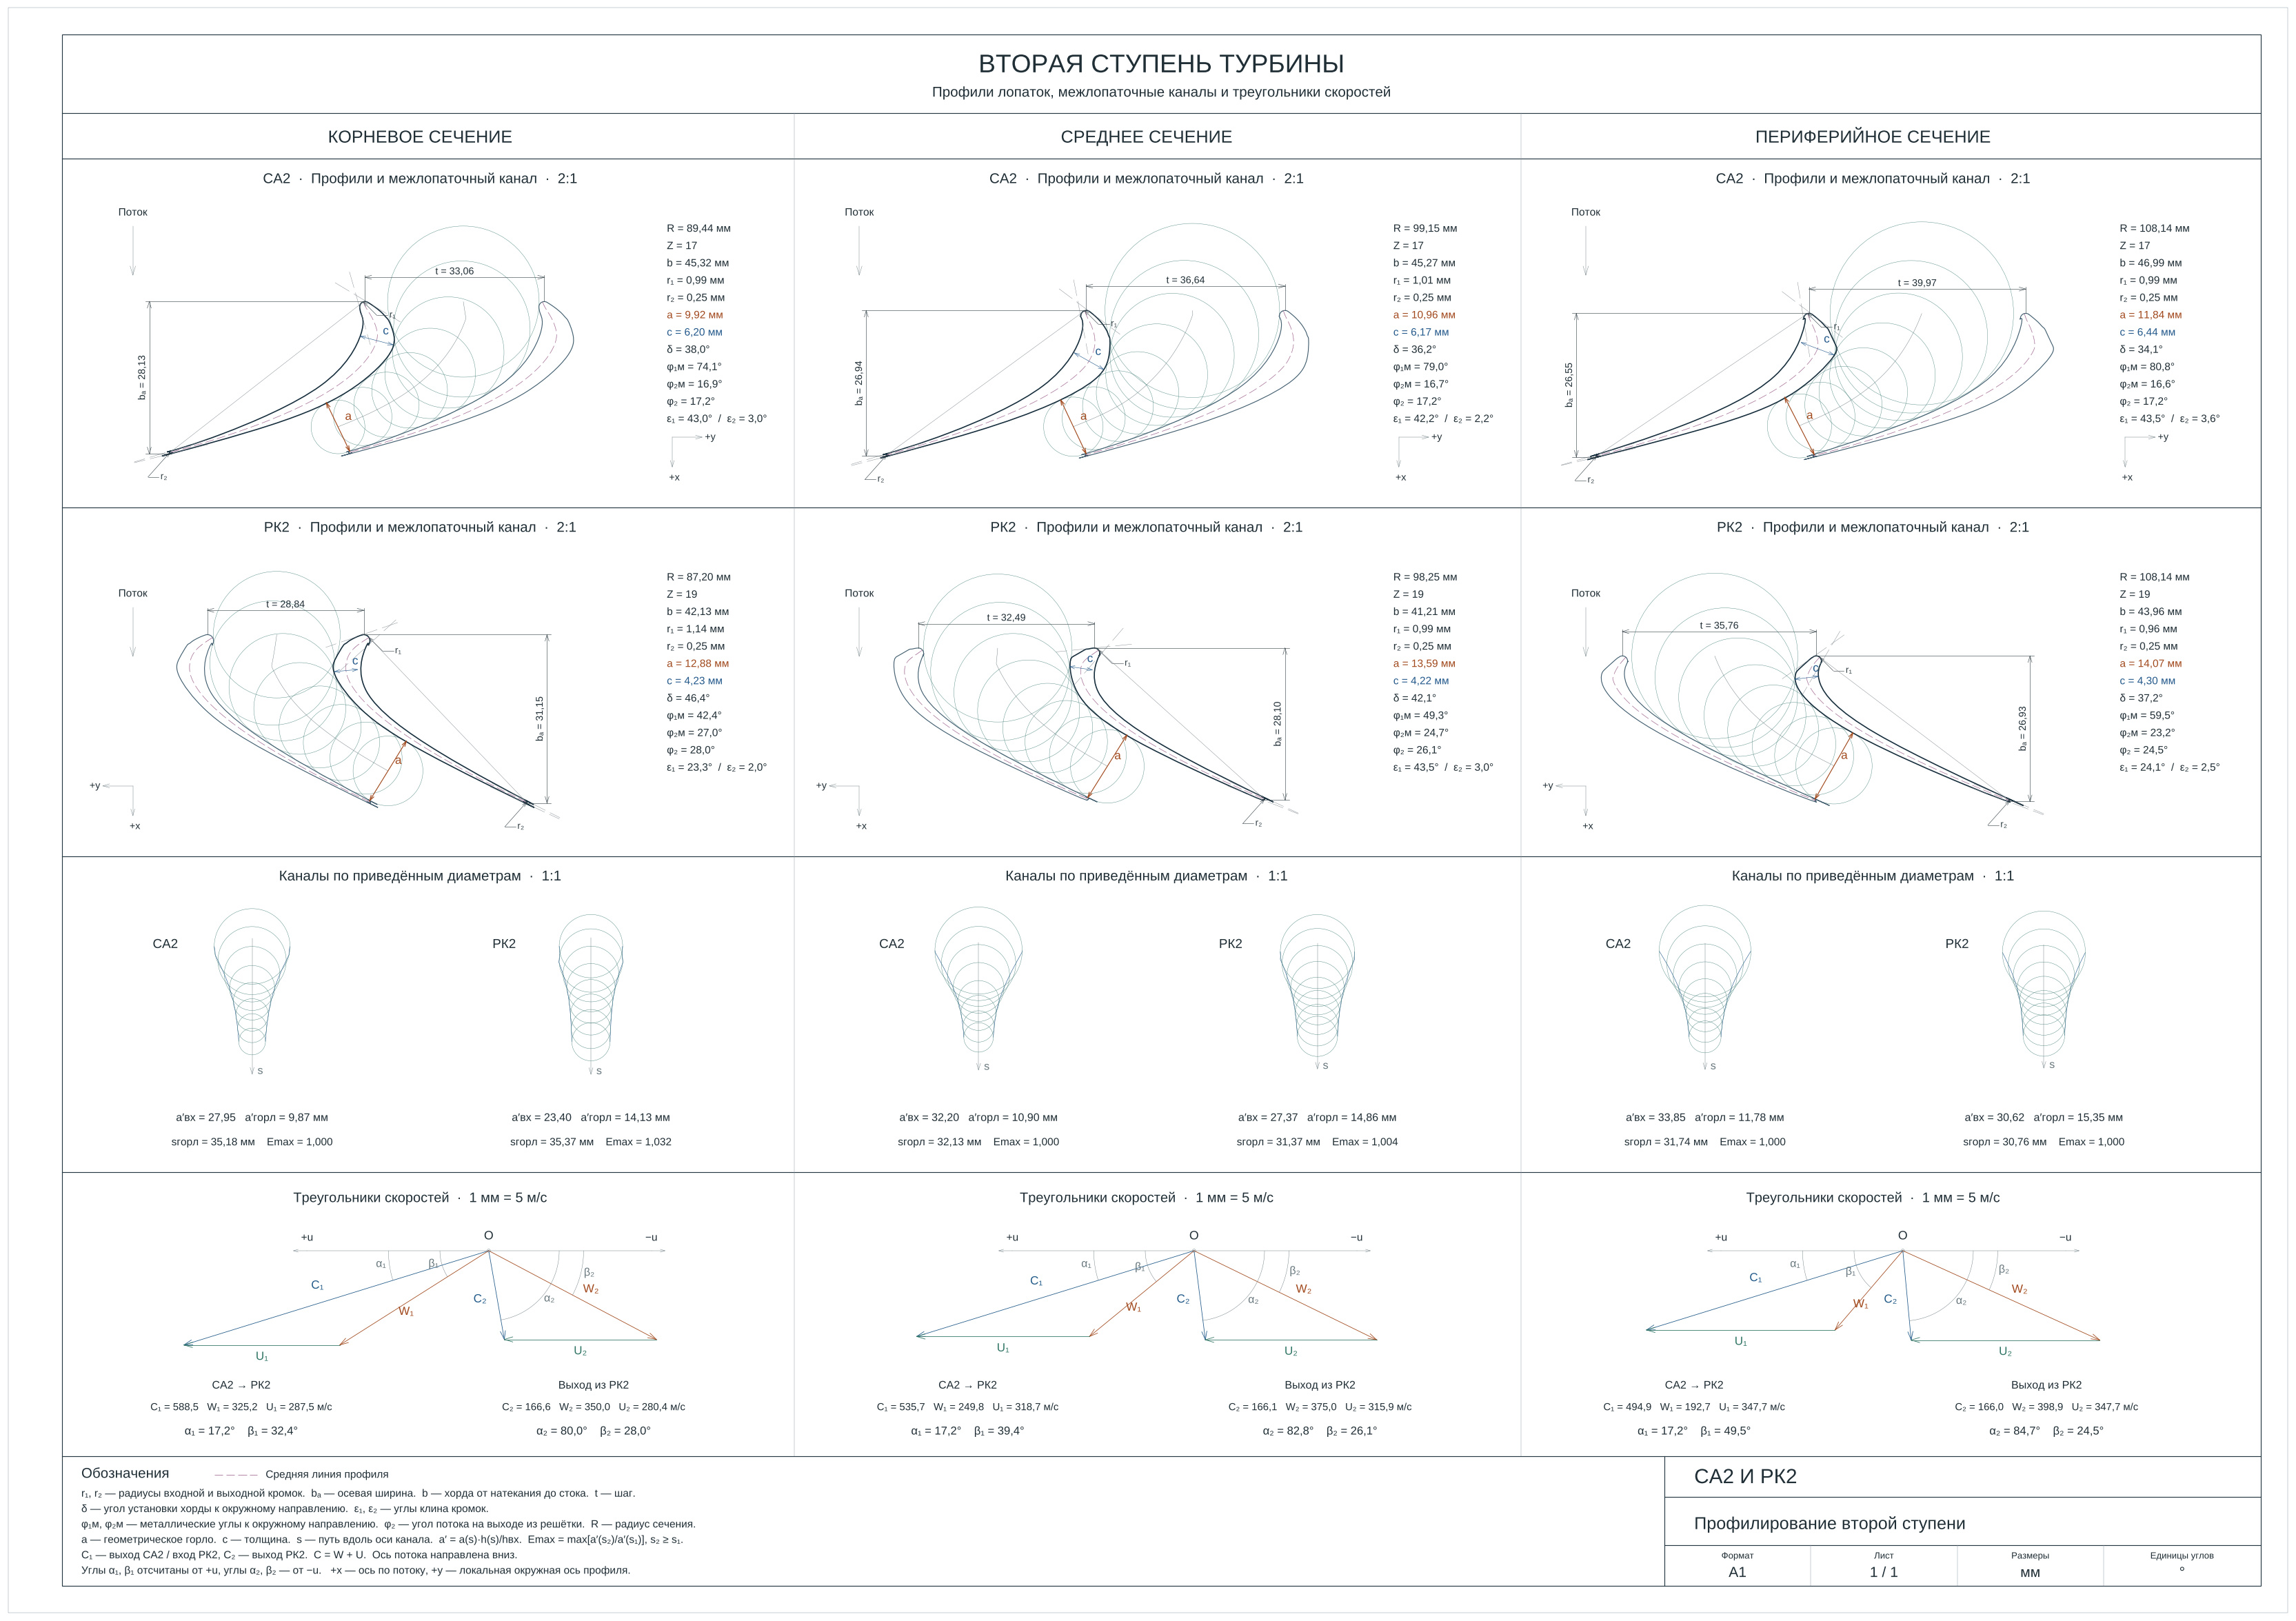

In [80]:
output = Path('export') / 'fixed'
triangles = stage2_velocity_triangles(P0,RADIAL_RESULTS[1]['sections'])
export_stage2_data(output,PROFILES,triangles,strength)
export_meridional_polylines(output, CHANNEL, PROFILES)
sheet_path = make_stage2_dxf(PROFILES,triangles,stage2_circles,output/'stage2_fixed_A1.dxf')
preview = render_stage2_dxf(sheet_path,sheet_path.with_suffix('.jpeg'))
export_common_velocity_triangles(triangles,output/'stage2_velocity_common_origin.dxf')
for filename, table in {
    'nominal_summary.csv':summary_table(P0),
    'meridional_nodes.csv':CHANNEL_STATIONS,
    'meridional_contour.csv':CHANNEL['contour'],
    'blade_rows.csv':drawing_schedule(CHANNEL,PROFILES).reset_index(),
    'profile_checks.csv':profile_checks,
    'cascade_solidity.csv':solidity_table,
    'blade_count_check.csv':blade_count_check,
    'blade_count_pairs.csv':blade_count_pairs,
    'rotor_taper.csv':taper_checks,
    'losses.csv':loss_rows,
    'strength.csv':strength['table'],
    'balances.csv':balance_table,
    'gas_stations.csv':gas_stations.reset_index(),
    'stage_calculation.csv':stage_values.reset_index(),
    'radial_checks.csv':radial_checks,
    'radial_sections.csv':radial_sections,
    'radial_inlet_distribution.csv':radial_distribution['inlet'],
    'radial_outlet_distribution.csv':radial_distribution['outlet'],
    'profile_angles.csv':profile_angles,
    'loss_sections.csv':loss_sections,
    'rotor_tension_trapezoids.csv':tension_five,
    'rotor_section_properties.csv':strength_details['geometry_table'],
    'rotor_chebyshev_check.csv':strength_details['chebyshev_table'],
    'rotor_chebyshev_ordinates.csv':strength_details['ordinates_table'],
    'rotor_loads_and_stresses.csv':strength_details['section_table'],
    'rotor_control_point_stresses.csv':strength_details['points_table'],
    'rotor_strength_span.csv':strength_details['span'],
    'rotor_strength_checks.csv':strength_checks,
    'material_rupture_data.csv':ZHS6U_RUPTURE_DATA,
    'material_rupture_data_ZHS6K.csv':ZHS6K_RUPTURE_DATA,
    'material_reference_IN738C.csv':IN738C_RUPTURE_DATA,
    'resource_material_comparison.csv':resource_comparison,
    'resource_hotter_reference.csv':resource_hotter_table,
    'resource_lm_sensitivity.csv':resource_lm_sensitivity,
    'resource_zhs6k_rotor2.csv':resource_zhs6k,
    'resource_historical.csv':resource_historical,
}.items():
    table.to_csv(output/filename,index=False,encoding='utf-8-sig',float_format='%.11g')
(output/'geometry_id.txt').write_text(signature+'\n',encoding='utf-8')
display(Image(filename=str(preview),width=1100))
